# **Multimorbidade e uso de serviços de saúde na PNS-2019: derivação de perfis por clusterização e avaliação do uso de serviços**

## **1. Formalização do problema**

A multimorbidade – presença simultânea de duas ou mais doenças crônicas – está associada a pior qualidade de vida, maior uso de serviços de saúde e custos elevados para o sistema. Em bases populacionais como a Pesquisa Nacional de Saúde (PNS-2019), as doenças crônicas não aparecem isoladas, mas em **padrões de combinação** que podem ser sintetizados em perfis de saúde.

### **1.1 Objetivo geral**

Derivar e caracterizar perfis populacionais de multimorbidade na PNS-2019 e comparar o uso de serviços de saúde entre esses perfis.

### **1.2 Objetivos específicos**

1. Entender a estrutura do dado da PNS-2019, com foco no módulo de doenças crônicas e uso de serviços de saúde.  
2. Realizar curadoria de variáveis, selecionando comorbidades, indicadores de saúde e variáveis sociodemográficas relevantes para o problema.  
3. Tratar qualidade de dados (faltantes, códigos “ignorados” e inconsistências) e preparar pesos amostrais compatíveis com a análise.  
4. Aplicar técnicas de **redução de dimensionalidade** (PCA / MCA) nas comorbidades, obtendo representações mais compactas e estáveis para clusterização.  
5. Estimar e comparar perfis de multimorbidade usando:
   - K-Means ponderado (aproximação clássica de clusterização por distância);
   - Análise de Classes/Perfis Latentes (LCA/LPA) com StepMix (abordagem baseada em modelos de mistura).  
6. Realizar **validação interna** dos agrupamentos (método do cotovelo, BIC, coeficiente de Silhouette e dispersão intra-cluster).  
7. Descrever e interpretar os perfis obtidos usando gráficos (mapas de calor, diagramas de radar, barras e bolhas) e tabelas.  
8. Comparar o uso de serviços de saúde entre perfis, discutindo implicações para planejamento em saúde.

---

## **2. Análise exploratória e transformações de dados**

Nesta parte, o notebook implementa a **Etapa 1 (1.x)**, dedicada a montar uma base consistente a partir dos microdados brutos da PNS-2019.

### **2.1 Fonte de dados e recortes**

- Base: microdados da **PNS-2019**, com plano amostral complexo e pesos calibrados pelo IBGE.   
- Recorte: população adulta (por exemplo, ≥ 18 anos), com foco nos indivíduos que responderam ao módulo de doenças crônicas e uso de serviços.  
- São mantidas variáveis que representam:
  - **Comorbidades crônicas** (hipertensão, diabetes, cardiopatias, depressão, câncer, DPOC, etc.);  
  - **Autoavaliação de saúde** (muito boa, boa, regular, ruim, muito ruim);  
  - **Uso de serviços** (consultas, internações, uso do SUS, plano de saúde, medicamentos, urgência, etc.);  
  - **Variáveis sociodemográficas** (sexo, idade, escolaridade, renda, região, zona urbano/rural);  
  - **Medidas antropométricas** e derivados (peso, altura, IMC, classes de IMC, indicador de obesidade).

### **2.2 Limpeza, filtragem e tratamento de faltantes**

- Remoção de registros com **NA nas variáveis-chave** (por exemplo, comorbidades usadas na clusterização), garantindo que o PCA e os métodos de clusterização trabalhem com casos completos.
- Tratamento de códigos especiais (1=Sim, 2=Não, 9=Ignorado, etc.), padronizando missing/ignorados e evitando que “9” seja interpretado como valor real.  
- Segmentação da amostra para **adultos** e, em alguns pontos, subgrupos específicos (por exemplo, quem respondeu a determinado módulo).

### **2.3 Recodificações e variáveis derivadas**

A etapa de pré-processamento (seções 1.3 e 1.4) organiza as variáveis em uma estrutura mais amigável para modelagem:

- **Mapeamentos categóricos**: códigos numéricos são traduzidos em rótulos legíveis (UF, região, escolaridade, renda per capita, estado civil, situação de domicílio, etc.).  
- **Dummies binárias 0/1**:
  - Doenças crônicas (hipertensão, diabetes, depressão, etc.) passam a ser indicadores binários 0/1, facilitando interpretação e uso em modelos;   
  - Indicadores de utilização de serviços (ex.: “Serviço de Saúde”, “Internação”, “Plano de Saúde”) também são tratados como 0/1 quando adequado.  
- **Variáveis derivadas**:
  - **Região geográfica** (Norte, Nordeste, Sudeste, Sul, Centro-Oeste) a partir da UF;  
  - **Classe de IMC** (baixo peso, peso normal, sobrepeso, obesidade) derivada de peso e altura;   
  - Indicadores agregados de multimorbidade (por exemplo, contagem de condições crônicas em cada indivíduo).

Além disso, o notebook constrói um conjunto de colunas de **peso** que respeitam o plano amostral:

- `Peso Amostral` → peso original do IBGE;  
- `Peso Populacional` → versão diretamente usada para estimar totais populacionais;  
- `Peso Normalizado` → peso reescalado para que a soma dos pesos seja igual ao tamanho da amostra;  
- `Peso ML (média=1)` → peso normalizado com média 1, usado nas partes de PCA, K-Means e LCA/LPA que aceitam `sample_weight`.

### **2.4 Normalização e bases para modelagem**

Para as etapas de mineração de dados:

- É construída uma base com as **comorbidades processadas** (binárias) como matriz de entrada para o PCA.  
- Variáveis numéricas são **normalizadas em escala 0–1** (MinMaxScaler) em uma cópia específica da base, **exceto** as colunas de peso (`Peso Amostral`, `Peso Populacional`, `Peso Normalizado`, `Peso ML (média=1)`), que mantêm a escala própria da amostragem complexa.  
- As bases são salvas em arquivos **parquet** separados (numérica / nominal, com e sem rótulos de cluster) para reutilização nas etapas de clusterização, validação e gráficos (mapas de calor, radar, barras e bolhas).

---

## **3. Algoritmos utilizados e justificativa**

O pipeline de mineração de dados (Etapa 2) combina métodos clássicos de redução de dimensionalidade e clusterização com abordagens baseadas em modelos de mistura.

### **3.1 Redução de dimensionalidade: PCA e MCA (2.3)**

- Aplicação de **Análise de Componentes Principais (PCA)** sobre a matriz de comorbidades, previamente padronizada (média 0, desvio 1).  
- Cálculo da **variância explicada** e **variância acumulada** para escolher um número de componentes que retenha a maior parte da informação com menor dimensionalidade.  
- Em paralelo, o notebook estrutura o uso de **Análise de Correspondência Múltipla (MCA)** como alternativa para dados categoricamente ricos, mantendo a mesma lógica de trabalhar em um espaço reduzido contínuo.

Motivação:  
- PCA/MCA ajudam a **reduzir ruído e colinearidade** entre comorbidades, produzindo eixos latentes que capturam padrões conjuntos de doenças.  
- Trabalhar em um espaço de baixa dimensão reduz instabilidade de K-Means, melhora visualização (PC1×PC2) e torna a estimação de modelos baseados em mistura mais estável.   

### **3.2 K-Means ponderado (2.4–2.5.1)**

- É aplicado **K-Means** sobre os escores de PCA, com múltiplas inicializações (várias seeds) para cada valor de \(k\) (por exemplo, \(k = 2,\dots,15\)).  
- Em cada combinação, o algoritmo pode usar o vetor de pesos `Peso ML (média=1)` como `sample_weight`, aproximando a representatividade populacional dos clusters.  
- O notebook calcula a **Inércia/Within-Cluster Sum of Squares (WCSS)** e, a partir dela, a **fração de variância explicada (EV(k))** para o método do cotovelo.

Motivação:  
- K-Means é uma abordagem direta, escalável e bem estabelecida para clusterização quando a métrica de distância euclidiana faz sentido nos escores de PCA.   
- É um bom “baseline” para comparar com métodos mais sofisticados (como LCA/LPA), além de produzir centróides que facilitam a interpretação geométrica dos perfis.

### **3.3 Análise de Classes/Perfis Latentes (LCA/LPA) com StepMix (2.5.2)**

- O notebook utiliza o pacote **StepMix** para ajustar modelos de mistura gaussianos sobre os escores de PCA (LPA) com diferentes números de classes.   
- Para cada \(k\) candidato, é calculado o **BIC (Bayesian Information Criterion)**, e o modelo com **menor BIC** é escolhido como melhor compromisso entre ajuste e parcimônia.  
- As classes latentes estimadas são então usadas para gerar rótulos de cluster (1..k), que são anexados às bases numéricas e nominais.

Motivação:  
- LCA/LPA são métodos **baseados em modelos de mistura**, oferecendo:
  - Probabilidades de pertença de cada indivíduo a cada classe;  
  - Modelagem explícita de variância intra-classe;  
  - Maior flexibilidade em diferentes tipos de variáveis e na incorporação de pesos e variáveis externas.   
- Em contextos de multimorbidade, LCA/LPA costumam gerar **perfis mais interpretáveis** e estáveis ao longo do tempo, o que os torna muito atraentes para estudos de perfis clínicos.   

### **3.4 Validação interna e métricas**

O notebook utiliza principalmente:

- **Método do Cotovelo** (Elbow): WCSS e EV(k), com banda p10–p90 entre seeds e um critério tipo “Kneedle”/segunda derivada para sugerir \(k^\*\).   
- **BIC** para escolha do número de classes no LCA/LPA.  
- **Coeficiente de Silhouette** global e por amostra:
  - Silhouette médio global para avaliar separação média entre clusters;  
  - Distribuição de valores de Silhouette por cluster, para identificar grupos bem definidos e pontos mal alocados.  
- **Dispersão interna (WCSS) e “erro médio por ponto”** como medida adicional de compactação intra-cluster.

---

## **4. Trabalhos correlatos (revisão da literatura)**

A estratégia adotada (PCA/MCA + K-Means e LCA/LPA) está alinhada ao que vem sendo feito na literatura recente de multimorbidade e uso de serviços:

- [Zhong et al., 2023 – BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-023-15412-5): aplica **LCA** para identificar padrões de multimorbidade a partir de múltiplas doenças crônicas em amostras populacionais, mostrando perfis como “relativamente saudável”, “vascular”, entre outros.   
- [Ansari et al., 2023 – PLOS Global Public Health](https://journals.plos.org/globalpublichealth/article/file?id=10.1371%2Fjournal.pgph.0002330&type=printable): usa **LCA** para extrair clusters de multimorbidade em idosos e relacioná-los ao uso de serviços de saúde e à autoavaliação de saúde, abordagem muito próxima da proposta deste estudo.   
- [Dong et al., 2013 – BMC Geriatrics](https://bmcgeriatr.biomedcentral.com/articles/10.1186/1471-2318-13-120): emprega **análise de clusters clássica** (como K-Means e métodos hierárquicos) para identificar perfis de multimorbidade e avaliar sua associação com o uso de serviços entre idosos suecos.   
- [Zhu et al., 2020 – BMC Medicine](https://bmcmedicine.biomedcentral.com/articles/10.1186/s12916-020-01543-8): avalia clusters de multimorbidade e como se relacionam com mortalidade e uso de serviços em diferentes faixas etárias, reforçando a relevância clínica dos perfis derivados.   
- [Roso-Llorach et al., 2018 – BMJ Open](https://bmjopen.bmj.com/content/8/3/e018986): compara diferentes métodos para identificar padrões de multimorbidade (análise fatorial, clusterização hierárquica, etc.), discutindo vantagens e limitações e motivando a combinação de abordagens (K-Means + LCA) como a usada aqui.   
- [Beridze et al., 2024 – Journal of Primary Care & Community Health](https://journals.sagepub.com/doi/10.1177/26335565231223350): revisão de padrões de multimorbidade em registros de atenção primária, resumindo as técnicas estatísticas mais empregadas (LCA, K-Means, HCA, etc.) e apontando a importância da interpretação clínica dos clusters.  

---

## **5. Metodologia das simulações computacionais**

Esta sessão resume como as análises computacionais são organizadas ao longo da Etapa 2 (2.3–2.7).

### **5.1 Métricas de avaliação**

As principais métricas usadas são:

- **WCSS / Inércia (K-Means)**: soma dos quadrados intra-cluster, utilizada tanto no método do cotovelo quanto para descrever a compactação do modelo final.  
- **Frações de variância explicada (EV(k))**: proporção da variância total capturada pelo modelo de clusters para cada k, derivada da inércia.  
- **BIC (LCA/LPA)**: critério de informação bayesiano, que penaliza modelos mais complexos; o k com menor BIC é escolhido como melhor.   
- **Coeficiente de Silhouette**:
  - Silhouette médio global, comparando distâncias intra- vs. inter-cluster;  
  - Silhouette amostral, permitindo avaliar quão bem cada indivíduo se encaixa no seu cluster.  
- **Dispersão média por ponto**: WCSS dividido pelo número de observações, usado como medida prática de erro médio de agrupamento.

### **5.2 Desenho dos testes e experimentos**

Os “testes” do notebook são essencialmente:

1. **Exploração de k (2.4)**  
   - Para cada \(k\) em um intervalo (tipicamente 2–15), roda-se K-Means com múltiplas seeds.  
   - Para cada combinação, coletam-se WCSS e derivam-se EV(k), bem como bandas p10–p90.  
   - Um critério automático (derivada de segunda ordem / “Kneedle” simplificado) marca o joelho do cotovelo como sugestão de \(k^\*\).

2. **Ajuste de modelo final via K-Means (2.5.1)**  
   - Fixado \(k^\*\), treina-se um modelo K-Means ponderado para gerar rótulos definitivos.  
   - Esses rótulos são anexados às bases numérica e nominal, e salvos em parquet para uso em análises posteriores.

3. **Exploração de k via LCA/LPA com StepMix (2.5.2)**  
   - Para cada \(k\) em um intervalo similar, ajusta-se um modelo de mistura com StepMix, usando pesos `Peso ML (média=1)` quando suportado.  
   - Calcula-se o BIC para cada k e seleciona-se o modelo com BIC mínimo.  
   - As classes latentes estimadas são transformadas em rótulos de cluster (1..k) e também anexadas às bases.

4. **Validação pós-agrupamento (2.6)**  
   - Cálculo do Silhouette global e por amostra a partir dos escores de PCA e dos rótulos de cluster.  
   - Geração do gráfico de Silhouette por cluster e do gráfico de dispersão em PC1×PC2, com centróides marcados.  
   - Cálculo do WCSS e do erro médio por ponto para descrever a dispersão interna dos clusters.

5. **Caracterização dos perfis (2.7)**  
   - Cálculo das **médias por cluster** em uma base normalizada, construindo:
     - Mapa de calor com comorbidades, autoavaliação de saúde e variáveis-chave;  
     - Diagramas de radar por cluster;  
     - Gráficos de barras interativos para comparar um atributo de cada vez entre clusters;  
     - Gráficos de bolhas cruzando “uso de serviço” vs. “autoavaliação de saúde” por cluster.

### **5.3 Métodos de interpretabilidade (global e local)**

**Interpretabilidade global**

- As médias por cluster (mapas de calor e radar) mostram, de forma agregada, **quais condições e características são mais prevalentes em cada perfil**, facilitando rótulos como “cardiometabólico”, “saúde mental + dor crônica”, “relativamente saudável”, etc.   
- Os gráficos de barras permitem comparar, variável a variável, a prevalência (ou escore médio) entre clusters.  
- Os gráficos de bolhas conectam diretamente **multimorbidade, percepção de saúde e uso de serviços**, ajudando a visualizar, por exemplo, quais clusters concentram mais uso de serviços mesmo entre indivíduos que avaliam sua saúde como boa.

**Interpretabilidade local**

- O **Silhouette por amostra** indica quão bem cada indivíduo se encaixa no cluster ao qual foi atribuído (valores próximos de 1 indicam boa alocação; valores negativos sugerem possível reclassificação).  
- Nos modelos LCA/LPA, as **probabilidades de pertença** (não explicitadas graficamente, mas disponíveis no modelo) permitem avaliar incerteza de classificação em nível individual, o que é útil para interpretar perfis “fronteira” entre duas classes.   

# **Etapa 1 - Preparação de dados da Pesquisa Nacional de Saúde de 2019**

Neste notebook, realizamos o pré-processamento dos microdados da PNS-2019 para torná-los adequados a algoritmos de aprendizado de máquina, com foco em reprodutibilidade e boas práticas de pesquisa em saúde pública. As etapas incluem checagem e limpeza, tratamento de valores ausentes, codificação de variáveis categóricas, padronização quando necessária e derivação de variáveis.

## **1.1 - Importação de Bibliotecas**

Nesta etapa do notebook, realizamos a instalação e carregamento dos pacotes do Python, que são utilizados como ferramentas para a manipulação, análise e visualização dos dados. Cada pacote oferece funcionalidades específicas que são utilizadas nas próximas etapas do projeto.

**Pacotes e suas Funcionalidades:**

* **PNSIBGE:** Pacote específico para trabalhar com dados da PNS, facilitando a leitura e o acesso às informações coletadas pela pesquisa.

* **logging:** Utilitário padrão do Python para registro de logs (info, warning, error). Usado para documentar passos do pré-processamento e facilitar o diagnóstico de eventuais problemas.

* **NumPy (numpy):** Base para operações numéricas e vetorizadas (arrays, funções matemáticas, máscaras). Oferece desempenho e integração com o pandas.

* **Pandas (pandas):** Biblioteca central para manipulação de dados tabulares (DataFrame), com recursos de seleção/filtragem, joins, agregações e tipagem (incluindo categóricas e datas).

* **missingno (missingno):** Ferramentas visuais para auditar valores ausentes (NA/NaN) em DataFrames, auxiliando na decisão de imputação, exclusão ou padronização de rótulos faltantes.

* **rpy2:** Ponte entre Python e R. **robjects:** objetos centrais para trocar dados entre Python↔R; **packages:** gerenciamento/carregamento de pacotes R; **r:** acesso direto ao interpretador R (executar comandos R dentro do notebook).

* **pathlib (Path):** API moderna para manipular caminhos de arquivos e pastas de forma portátil (Windows/Linux/Mac), usada para organizar diretórios de dados/saídas.
* **pandas.api.types:** is_bool_dtype, is_numeric_dtype, is_datetime64_any_dtype: detectam classes de dados para validações; CategoricalDtype: define tipos categóricos (com ou sem ordem), essencial para tratar variáveis binárias, nominais, ordinais e Likert conforme o dicionário do projeto.

In [ ]:
!pip install missingno
!pip install rpy2

# Instalando pacotes necessários
import logging  # Controle e registro de mensagens de log durante a execução do notebook.
import numpy as np  # Operações numéricas e vetoriais de alto desempenho.
import pandas as pd  # Manipulação e análise de dados em formato tabular (DataFrames).
import missingno as msno  # Visualização e diagnóstico de valores ausentes (missing values).
import rpy2.robjects as robjects  # Integração geral entre Python e R.
import rpy2.robjects.packages as rpackages  # Carregamento e gerenciamento de pacotes R a partir do Python.

from pathlib import Path  # Manipulação de caminhos e arquivos de forma independente de sistema operacional.
from rpy2.robjects import r  # Acesso direto ao interpretador R (execução de comandos R no Python).
from sklearn.preprocessing import MinMaxScaler
from pandas.api.types import (
    is_bool_dtype,  # Função auxiliar para testar se uma coluna é do tipo booleano.
    is_numeric_dtype,  # Função auxiliar para testar se uma coluna é numérica.
    is_object_dtype,  # Função auxiliar para testar se uma coluna é do tipo objeto (strings, misto etc.).
    is_datetime64_any_dtype,  # Função auxiliar para testar se uma coluna é de data/hora.
    CategoricalDtype,  # Tipo de dado categórico do pandas, usado para codificação de variáveis qualitativas.
)

## **1.2 - Importação, Seleção e Sumarização dos Dados**

### **1.2.1 - Importação e Cache do Plano Amostral - PNS 2019**

Nessa etapa, é realizada a importação dos dados da Pesquisa Nacional de Saúde de 2019 via PNSIBGE (no R), e salvo em Parquet.

In [ ]:
# caminhos
CSV_PATH = Path("/content/pns2019.csv")
CACHE    = Path("plano_amostral_original_121.parquet")

# se NÃO existe cache, tentamos criar o CSV (via R) caso ele também não exista
if not CACHE.exists() and not CSV_PATH.exists():
    # silencia logs do R
    logging.getLogger('rpy2.rinterface_lib.callbacks').setLevel(logging.ERROR)

    # instala/carrega pacotes R necessários
    utils = rpackages.importr('utils')
    utils.chooseCRANmirror(ind=1)
    for pkg in ("PNSIBGE", "readr"):
        if not rpackages.isinstalled(pkg):
            utils.install_packages(pkg)

    r('suppressPackageStartupMessages(library(PNSIBGE))')
    r('suppressPackageStartupMessages(library(readr))')

    # baixa a PNS 2019 no R
    r('df_pns <- get_pns(year = 2019, design = FALSE)')

    # salva o CSV exatamente no caminho que o Python vai ler
    r(f'readr::write_csv(df_pns, "{CSV_PATH.as_posix()}")')

# aplica a lógica de cache: Parquet > CSV
if CACHE.exists():
    plano_amostral_121 = pd.read_parquet(CACHE, engine="pyarrow")
else:
    # assumimos que já existe o CSV (ou porque você colocou, ou porque o R gerou)
    plano_amostral_121 = pd.read_csv(CSV_PATH, low_memory=False)
    plano_amostral_121.to_parquet(CACHE, engine="pyarrow", compression="snappy")

# inspeção
nlin, ncol = plano_amostral_121.shape
print(f"Linhas: {nlin:,} | Colunas: {ncol}")
plano_amostral_121.head(5)

Linhas: 279,382 | Colunas: 1082


,V0020,V0001,V0024,UPA_PNS,V0006_PNS,V0015,V0022,V0026,V0031,V0025A,...,VDF002,VDF003,VDF004,VDL001,VDM001,VDP001,VDR001,VDDATA,ID_DOMICILIO,Deflator
0,2019,Rondônia,1110011,110000016,1,Realizada,6,Urbano,Capital,Selecionado,...,2098.0,350.0,Mais de ¼ até ½ salário mínimo,NaN,None,None,None,20220504,1100000160001,1
1,2019,Rondônia,1110011,110000016,1,Realizada,6,Urbano,Capital,Não selecionado,...,2098.0,350.0,Mais de ¼ até ½ salário mínimo,NaN,None,None,None,20220504,1100000160001,1
2,2019,Rondônia,1110011,110000016,1,Realizada,6,Urbano,Capital,Não selecionado,...,2098.0,350.0,Mais de ¼ até ½ salário mínimo,NaN,None,None,None,20220504,1100000160001,1
3,2019,Rondônia,1110011,110000016,1,Realizada,6,Urbano,Capital,Não aplicável,...,2098.0,350.0,Mais de ¼ até ½ salário mínimo,NaN,None,None,None,20220504,1100000160001,1
4,2019,Rondônia,1110011,110000016,1,Realizada,6,Urbano,Capital,Não aplicável,...,2098.0,350.0,Mais de ¼ até ½ salário mínimo,NaN,None,None,None,20220504,1100000160001,1


### **1.2.2 - Seleção dos Dados de Interesse**

Nesta etapa do processo, realizamos a seleção das colunas relevantes para a análise, criando um novo conjunto de dados mais conciso e focado nas variáveis de interesse para a pesquisa. Além disso, renomeamos as colunas com nomes mais descritivos, facilitando a interpretação dos dados.

#### **1.2.2.3 - Atributos**


1. **V0001: UF**

   * Unidade da Federação.

     * 11: Rondônia
     * 12: Acre
     * 13: Amazonas
     * 14: Roraima
     * 15: Pará
     * 16: Amapá
     * 17: Tocantins
     * 21: Maranhão
     * 22: Piauí
     * 23: Ceará
     * 24: Rio Grande do Norte
     * 25: Paraíba
     * 26: Pernambuco
     * 27: Alagoas
     * 28: Sergipe
     * 29: Bahia
     * 31: Minas Gerais
     * 32: Espírito Santo
     * 33: Rio de Janeiro
     * 35: São Paulo
     * 41: Paraná
     * 42: Santa Catarina
     * 43: Rio Grande do Sul
     * 50: Mato Grosso do Sul
     * 51: Mato Grosso
     * 52: Goiás
     * 53: Distrito Federal

2. **V0024: Estrato**

   * Estrato.

3. **V0006_PNS: Ordem do Domicílio**

   * Número de ordem do domicílio na PNS.

4. **V0026: Zona**

   * Tipo de situação censitária:

     * 1: Rural
     * 2: Urbana

5. **B001: Cadastro UBS**

   * O seu domicílio está cadastrado na unidade de saúde da família:

     * 1: Sim
     * 2: Não
     * 3: Não sabe
     * 9: Ignorado

6. **B003: Visita ACS**

   * Nos últimos doze meses, com que frequência o seu domicílio recebeu uma visita de algum Agente Comunitário ou algum membro da Equipe de Saúde da Família?:

     * 1: Mensalmente
     * 2: A cada 2 meses
     * 3: De 2 a 4 vezes
     * 4: Uma vez
     * 5: Nunca recebeu
     * 9: Ignorado

7. **C00301: Ordem Morador**

   * Número de ordem do morador.

8. **C006: Sexo**

   * Sexo:

     * 1: Homem
     * 2: Mulher

9. **C008: Idade**

   * Idade do morador na data de referência.

10. **C009: Cor/Raça**

    * Cor ou raça:

      * 1: Branca
      * 2: Preta
      * 3: Amarela
      * 4: Parda
      * 5: Indígena
      * 9: Ignorado

11. **C011: Estado Civil**

    * Qual é o estado civil de ___?:

      * 1: Casado(a)
      * 2: Divorciado(a)/desquitado(a)/separado(a) judicialmente
      * 3: Viúvo(a)
      * 4: Solteiro(a)
      * 9: Ignorado

12. **D001: Alfabetizado**

    * Sabe ler e escrever:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

13. **D00201: Na Escola**

    * Frequenta escola ou creche:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

14. **E001: Trabalha**

    * Na semana de___ a___ (semana de referência), ___ trabalhou ou estagiou, durante pelo menos uma hora, em alguma atividade remunerada em dinheiro:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

15. **I00102: Plano de Saúde**

    * tem algum plano de saúde médico particular, de empresa ou órgão público?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

16. **J001: Saúde Geral**

    * De um modo geral, como é o estado de saúde de________:

      * 1: Muito bom
      * 2: Bom
      * 3: Regular
      * 4: Ruim
      * 5: Muito ruim
      * 9: Ignorado

17. **J01101: Última Consulta Médica**

    * Quando ____ consultou um médico pela última vez.

      * 1: Até 1 ano
      * 2: Mais de 1 ano a 2 anos
      * 3: Mais de 2 anos a 3 anos
      * 4: Mais de 3 anos
      * 5: Nunca foi ao médico
      * 9: Ignorado

18. **J012: Consultas 12m**

    * Quantas vezes ___ consultou um médico nos últimos 12 meses.

19. **J014: Buscou Atendimento (2sem)**

    * Nas duas últimas semanas, ___ procurou algum lugar, serviço ou profissional de saúde para atendimento relacionado à própria saúde:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

20. **J024: Atend. Coberto Plano**

    * Este atendimento de saúde de ___ foi coberto por algum plano de saúde.,

      * 1: Sim
      * 2: Não
      * 9: Ignorado

21. **J025: Pagou Atendimento (2sem)**

    * ___ pagou algum valor por este atendimento de saúde recebido nas duas últimas semanas.
    
      * 1: Sim
      * 2: Não
      * 9: Ignorado

22. **J026: Atendimento SUS**

    * O atendimento de ___ foi feito pelo SUS.
    
      * 1: Sim
      * 2: Não
      * 3: Não sabe/Não lembra

23. **J02901: Receitou Medicamento**

    * Neste atendimento de ___, foi receitado algum medicamento.
    
      * 1: Sim
      * 2: Não
      * 9: Ignorado

24. **J03001: Obteve Medicamentos**

    * __conseguiu obter os medicamentos receitados? (Leia as opções de resposta).
    
      * 1: Sim, todos
      * 2: Sim, alguns
      * 3: Não, nenhum
      * 9: Ignorado

25. **J03102: Motivo Não Obter Meds**

    * Qual o principal motivo de ___ não ter conseguido obter todos os medicamentos receitados.

      * 1: Não conseguiu obter no serviço público de saúde
      * 2: Não conseguiu o(s) medicamento(s) no programa Aqui Tem Farmácia Popular
      * 3: Não tinha farmácia próxima ou teve dificuldade de transporte
      * 4: Não conseguiu encontrar todos os medicamentos na farmácia
      * 5: Não tinha dinheiro para comprar
      * 6: Não achou necessário
      * 7: " Desistiu de procurar, pois melhorou"
      * 8: Outro
      * 9: Ignorado

26. **J032: Medicamento Coberto Plano**

    * Algum dos medicamentos foi coberto por plano de saúde.
    
      * 1: Sim, todos
      * 2: Sim, alguns
      * 3: Não, nenhum
      * 9: Ignorado

27. **J03301: Meds Farmácia Popular**

    * Algum dos medicamentos foi obtido no programa Aqui Tem Farmácia Popular.
    
      * 1: Sim, todos
      * 2: Sim, alguns
      * 3: Não, nenhum
      * 9: Ignorado

28. **J034: Meds Serviço Público**

    * Algum dos medicamentos foi obtido em serviço público de saúde.
    
      * 1: Sim, todos
      * 2: Sim, alguns
      * 3: Não, nenhum
      * 9: Ignorado

29. **J035: Pagou Medicamentos**

    * ___ pagou algum valor pelos medicamentos.

      * 1: Sim
      * 2: Não
      * 9: Ignorado

30. **J037: Internação 12m**

    * Nos últimos 12 meses, ___ ficou internado(a) em hospital por 24 horas ou mais:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

31. **J038: Nº Internações 12m**

    * Nos últimos 12 meses, quantas vezes ___ esteve internado(a).

32. **J042: Internação Coberta Plano**

    * A última internação de ___ nos últimos 12 meses foi coberta por algum plano de saúde.

      * 1: Sim
      * 2: Não
      * 9: Ignorado

33. **J043: Pagou Internação**

    * ___ pagou algum valor por esta última internação? (Entrevistador: se o(a) entrevistado(a) responder que pagou, mas teve reembolso total, marque a opção 2).

      * 1: Sim
      * 2: Não
      * 9: Ignorado

34. **J044: Internação SUS**

    * Esta última internação de ___ foi feita através do Sistema Único de Saúde (SUS).

      * 1: Sim
      * 2: Não  
      * 3: Não sabe/Não lembra

35. **J046: Urgência no Domicílio**

    * Nos últimos 12 meses, ___ teve atendimento de urgência ou emergência no domicílio.

      * 1: Sim
      * 2: Não
      * 9: Ignorado

36. **J047: Urgência Coberta Plano**

    * Este atendimento foi coberto por algum plano de saúde.

      * 1: Sim
      * 2: Não
      * 9: Ignorado

37. **J048: Pagou Urgência**

    * ___pagou algum valor por este atendimento? (Entrevistador: se o(a) entrevistado(a) responder que pagou, mas teve reembolso total, marque a opção 2).

      * 1: Sim
      * 2: Não
      * 9: Ignorado

38. **J049: Urgência SUS**

    * Este atendimento foi feito através do Sistema Único de Saúde (SUS).

      * 1: Sim
      * 2: Não  
      * 3: Não sabe/Não lembra

39. **J051: Ambulância**

    * Neste atendimento, ___ foi transportado por ambulância para um serviço de saúde.

      * 1: Sim
      * 2: Não
      * 9: Ignorado

40. **K04301: Medicamento Contínuo**

    * ___faz uso de algum medicamento, que foi receitado por um médico, para uso regular ou contínuo (Diário).

      * 1: Sim
      * 2: Não  
      * 3: Não sabe/Não lembra
      * 9: Ignorado

41. **K04302: Nº Meds Contínuos (2sem)**

    * Quantos medicamentos diferentes de uso regular ou contínuo, receitados pelo médico, ___ usou nas duas últimas semanas.

42. **K052: Vacina Gripe (12m)**

    * Nos últimos doze meses, ___ tomou vacina contra gripe.

      * 1: Sim
      * 2: Não
      * 9: Ignorado

43. **P00104: Peso**

    * Peso - Final (em kg) (3 inteiros e 1 casa decimal).

44. **P00404: Altura**

    * Altura - Final (em cm) (3 inteiros).

45. **P027: Álcool**

    * Com que frequência o(a) Sr(a) costuma consumir alguma bebida alcoólica?:

      * 1: Não bebo nunca
      * 2: Menos de uma vez por mês
      * 3: Uma vez ou mais por mês
      * 9: Ignorado

46. **P034: Exercício Físico**

    * Nos últimos três meses, o(a) Sr(a) praticou algum tipo de exercício físico ou esporte?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

47. **P050: Tabaco**

    * Atualmente, o(a) Sr(a) fuma algum produto do tabaco?:

      * 1: Sim, diariamente
      * 2: Sim, menos que diariamente
      * 3: Não fumo atualmente
      * 9: Ignorado

48. **Q00201: Hipertensão**

    * Algum médico já lhe deu o diagnóstico de hipertensão arterial (pressão alta)?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

49. **Q00202: Hipertensão na Gestação**

    * Essa hipertensão arterial (pressão alta) ocorreu apenas durante algum período de gravidez?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

50. **Q028: Hipertensão Limita Atividades**

    * Em geral, em que grau a hipertensão ou alguma complicação da hipertensão limita as suas atividades habituais (como trabalhar, estudar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

51. **Q03001: Diabetes**

    * Algum médico já lhe deu o diagnóstico de diabetes?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

52. **Q03002: Diabetes na Gestação**

    * Esse diabetes ocorreu apenas durante algum período de gravidez?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

53. **Q058: Diabetes Limita Atividades**

    * Em geral, em que grau o diabetes ou alguma complicação do diabetes limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

54. **Q060: Colesterol Alto**

    * Algum médico já lhe deu o diagnóstico de colesterol alto?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

55. **Q06306: Cardiopatia**

    * Algum médico já lhe deu o diagnóstico de uma doença do coração, tal como infarto, angina, insuficiência cardíaca ou outra?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

56. **Q067: Cardiopatia Limita Atividades**

    * Em geral, em que grau a doença do coração limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

57. **Q068: AVC ou Derrame**

    * Algum médico já lhe deu o diagnóstico de AVC (Acidente Vascular Cerebral) ou derrame?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

58. **Q073: AVC Limita Atividades**

    * Em geral, em que grau o derrame (ou AVC) limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

59. **Q074: Asma**

    * Algum médico já lhe deu o diagnóstico de asma (ou bronquite asmática)?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

60. **Q078: Asma Limita Atividades**

    * Em geral, em que grau a asma limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos, etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

61. **Q079: Artrite ou Reumatismo**

    * Algum médico já lhe deu o diagnóstico de artrite ou reumatismo?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

62. **Q083: Artrite/Reumatismo Limita**

    * Em geral, em que grau a artrite ou reumatismo limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos, etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

63. **Q084: Dor na Coluna**

    * O(a) Sr(a) tem algum problema crônico de coluna, como dor crônica nas costas ou no pescoço, lombalgia, dor ciática, problemas nas vértebras ou disco?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

64. **Q087: Dor na Coluna Limita Atividades**

    * Em geral, em que grau o problema na coluna limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos, etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

65. **Q088: DORT**

    * Algum médico já lhe deu o diagnóstico de DORT?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

66. **Q091: DORT Limita Atividades**

    * Em geral, em que grau o DORT limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

67. **Q092: Depressão**

    * Algum médico ou profissional de saúde mental (como psiquiatra ou psicólogo) já lhe deu o diagnóstico de depressão?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

68. **Q109: Depressão Limita Atividades**

    * Em geral, em que grau a depressão limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos, etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

69. **Q11006: Outra Doença Mental**

    * Algum médico ou profissional de saúde (como psiquiatra ou psicólogo) já lhe deu o diagnóstico de outra doença mental, como transtorno de ansiedade, síndrome do pânico, esquizofrenia, transtorno bipolar, psicose ou TOC (Transtorno Obsessivo Compulsivo) etc?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

70. **Q115: Outra Doença Mental Limita**

    * Em geral, em que grau essa doença mental limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

71. **Q11604: Doença Crônica no Pulmão**

    * Algum médico já lhe deu o diagnóstico de alguma outra doença crônica no pulmão, tais como enfisema pulmonar, bronquite crônica ou DPOC?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

72. **Q119: Doença Pulmão Limita**

    * Em geral, em que grau a doença do pulmão limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

73. **Q120: Câncer**

    * Algum médico já lhe deu diagnóstico de câncer?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

74. **Q12301: Câncer Limita Atividades**

    * Em geral, seu tratamento, ou algum problema provocado pelo câncer, limita as suas atividades profissionais ou habituais (tais como trabalhar, realizar afazeres domésticos, etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

75. **Q124: Insuficiência Renal Crônica**

    * Algum médico já lhe deu o diagnóstico de insuficiência renal crônica?:

      * 1: Sim
      * 2: Não
      * 9: Ignorado

76. **Q127: Insuficiência Renal Limita Atividades**

    * Em geral, em que grau a insuficiência renal crônica limita as suas atividades habituais (tais como trabalhar, realizar afazeres domésticos etc.)?:

      * 1: Não limita
      * 2: Um pouco
      * 3: Moderadamente
      * 4: Intensamente
      * 5: Muito intensamente
      * 9: Ignorado

77. **H001: Última Consulta (H)**

    * Quando foi a última vez que o(a) sr(a) consultou com um(a) médico(a)?

      * 1: Até 15 dias
      * 2: Mais de 15 dias até 1 mês
      * 3: Mais de 1 mês até 6 meses
      * 4: Mais de 6 meses até 1 ano
      * 5: Há mais de 1 ano
      * 9: Ignorado

78. **H003: Motivo da Consulta**

    * Por qual motivo o(a) sr(a) precisou consultar com um(a) médico(a).

      * 1: Acidente ou lesão
      * 2: Continuação de tratamento ou terapia
      * 3: Consulta pré-natal
      * 4: Exame médico periódico
      * 5: "Outro exame médico (admissional, para carteira de motorista, etc)"
      * 6: Problema de saúde mental
      * 7: Doença ou outro problema de saúde
      * 8: Outro (Especifique:__)
      * 9: Ignorado

79. **H004: Local do Atendimento**

    * Onde procurou o atendimento médico por este motivo?

      * 1: Unidade básica de saúde (posto ou centro de saúde ou unidade de saúde da família)
      * 2: "Centro de Especialidades, Policlínica pública ou PAM – Posto de Assistência Médica"
      * 3: CAPS – Centro de Atenção Psicossocial
      * 4: UPA (Unidade de Pronto Atendimento)
      * 5: Outro tipo de Pronto Atendimento Público (24 horas)
      * 6: Pronto-socorro ou emergência de hospital público
      * 7: Hospital público/ambulatório
      * 8: Consultório particular ou clínica privada
      * 9: Ambulatório ou consultório de empresa ou sindicato
      * 10: Pronto-atendimento ou emergência de hospital privado
      * 11: "No domicílio, com médico particular"
      * 12: "No domicílio, com médico da equipe de saúde da família"
      * 13: Outro (Especifique:__)
      * 99: Ignorado

80. **V00291: Peso Amostral**

    * Peso do morador selecionado com calibração.

81. **VDD004A: Grau de Ensino**

    * Nível de instrução mais elevado alcançado (pessoas de 5 anos ou mais de idade) padronizado para o Ensino Fundamental -  SISTEMA DE 9 ANOS:

      * 1: Sem instrução
      * 2: Fundamental incompleto ou equivalente
      * 3: Fundamental completo ou equivalente
      * 4: Médio incompleto ou equivalente
      * 5: Médio completo ou equivalente
      * 6: Superior incompleto ou equivalente
      * 7: Superior completo

82. **VDF004: Faixa Renda PC**

    * Faixa de rendimento domiciliar per capita (exclusive o rendimento das pessoas cuja condição na unidade domiciliar era pensionista, empregado doméstico ou parente do empregado doméstico):

      * 1: Até ¼ salário mínimo
      * 2: Mais de ¼ até ½ salário mínimo
      * 3: Mais de ½ até 1 salário mínimo
      * 4: Mais de 1 até 2 salários mínimos (R$ 998,01 até R$ 1996,00)
      * 5: Mais de 2 até 3 salários mínimos
      * 6: Mais de 3 até 5 salários mínimos
      * 7: Mais de 5 salários mínimos


#### **1.2.2.4 - Seleção**

O peso do morador selecionado foi calculado considerando-se o peso do domicílio correspondente, a probabilidade de seleção do morador, ajustes para correção de não resposta por sexo e para calibração das estimativas, segundo os totais populacionais, por sexo e classes de idade, estimados com o peso de todos os moradores. As cinco classes de idade utilizadas foram: de 15 a 17 anos, de 18 a 24 anos, de 25 a 39 anos, de 40 a 59 anos, e 60 anos ou mais.

In [ ]:
# novo dataframe para esta etapa
plano_amostral_1224 = plano_amostral_121.copy()

# ---------------------------------------------------------
# 1) GARANTIR QUE A COLUNA DE PESO AMOSTRAL (V00291) EXISTA
# ---------------------------------------------------------
# No seu dicionário, V00291 será renomeada para "Peso Amostral".
# Se ela não existir na base original, vamos criá-la usando
# uma lógica equivalente à do R:
#   Peso Amostral = 1 / rowSums(UF + Extrato + Peso(V0091) + OrdemDom + NumOrdem)
# Aqui vamos usar as colunas que temos: V0001, V0024, V0006_PNS, C00301
# -> ajuste essa lista se quiser incluir mais alguma componente.

if "V00291" not in plano_amostral_1224.columns:
    print("Coluna 'V00291' não encontrada. Criando 'V00291' (Peso Amostral) a partir de outras variáveis...")

    colunas_peso_componentes = ["V0001", "V0024", "V0006_PNS", "C00301"]  # UF, Estrato, Ordem Domicílio, Nº Ordem

    # Checar se todas as colunas necessárias existem
    faltando_peso = [c for c in colunas_peso_componentes if c not in plano_amostral_1224.columns]
    if faltando_peso:
        raise KeyError(
            "Não foi possível calcular 'V00291' (Peso Amostral). "
            f"As seguintes colunas necessárias não existem na base: {faltando_peso}"
        )

    # Converter para numérico (qualquer coisa não convertível vira NaN)
    componentes_peso = plano_amostral_1224[colunas_peso_componentes].apply(
        pd.to_numeric, errors="coerce"
    )

    # Soma por linha (equivalente ao rowSums(..., na.rm = TRUE) do R)
    soma_componentes = componentes_peso.sum(axis=1, min_count=1)

    # Peso Amostral = 1 / soma; se soma for 0 ou NaN, resulta em NaN ou inf → pode tratar se quiser
    plano_amostral_1224["V00291"] = 1.0 / soma_componentes

# ---------------------------------------------------------
# 2) SELECIONAR APENAS AS COLUNAS NECESSÁRIAS
# ---------------------------------------------------------

colunas = [
    "V0001","V0024","V0006_PNS","V0026", "B001","B003", "C00301","C006","C008",
    "C009","C011", "D001","D00201", "E001", "I00102", "J001","J01101","J012",
    "J014","J024","J025","J026","J02901","J03001","J03102","J032","J03301",
    "J034","J035","J037","J038","J042","J043","J044","J046","J047","J048",
    "J049","J051", "K04301","K04302","K052", "P00104","P00404","P027","P034",
    "P050", "Q00201","Q00202","Q028","Q03001","Q03002","Q058","Q060","Q06306",
    "Q067","Q068","Q073","Q074","Q078","Q079","Q083","Q084","Q087","Q088",
    "Q091","Q092","Q109","Q11006","Q115","Q11604","Q119","Q120","Q12301",
    "Q124","Q127", "H001","H003","H004", "V00291","VDD004A","VDF004",
]

nomes = {
    "V0001": "UF",
    "V0024": "Estrato",
    "V0006_PNS": "Ordem do Domicílio",
    "V0026": "Zona",

    "B001": "Cadastro UBS",
    "B003": "Visita ACS",

    "C00301": "Ordem Morador",
    "C006": "Sexo",
    "C008": "Idade",
    "C009": "Cor/Raça",
    "C011": "Estado Civil",

    "D001": "Alfabetizado",
    "D00201": "Na Escola",

    "E001": "Trabalha",

    "I00102": "Plano de Saúde",

    "J001": "Saúde Geral",
    "J01101": "Última Consulta Médica",
    "J012": "Consultas 12m",
    "J014": "Buscou Atendimento (2sem)",
    "J024": "Atend. Coberto Plano",
    "J025": "Pagou Atendimento (2sem)",
    "J026": "Atendimento SUS",
    "J02901": "Receitou Medicamento",
    "J03001": "Obteve Medicamentos",
    "J03102": "Motivo Não Obter Meds",
    "J032": "Medicamento Coberto Plano",
    "J03301": "Meds Farmácia Popular",
    "J034": "Meds Serviço Público",
    "J035": "Pagou Medicamentos",
    "J037": "Internação 12m",
    "J038": "Nº Internações 12m",
    "J042": "Internação Coberta Plano",
    "J043": "Pagou Internação",
    "J044": "Internação SUS",
    "J046": "Urgência no Domicílio",
    "J047": "Urgência Coberta Plano",
    "J048": "Pagou Urgência",
    "J049": "Urgência SUS",
    "J051": "Ambulância",

    "K04301": "Medicamento Contínuo",
    "K04302": "Nº Meds Contínuos (2sem)",
    "K052": "Vacina Gripe (12m)",

    "P00104": "Peso",
    "P00404": "Altura",
    "P027": "Álcool",
    "P034": "Exercício Físico",
    "P050": "Tabaco",

    "Q00201": "Hipertensão",
    "Q00202": "Hipertensão na Gestação",
    "Q028": "Hipertensão Limita Atividades",
    "Q03001": "Diabetes",
    "Q03002": "Diabetes na Gestação",
    "Q058": "Diabetes Limita Atividades",
    "Q060": "Colesterol Alto",
    "Q06306": "Cardiopatia",
    "Q067": "Cardiopatia Limita Atividades",
    "Q068": "AVC ou Derrame",
    "Q073": "AVC Limita Atividades",
    "Q074": "Asma",
    "Q078": "Asma Limita Atividades",
    "Q079": "Artrite ou Reumatismo",
    "Q083": "Artrite/Reumatismo Limita",
    "Q084": "Dor na Coluna",
    "Q087": "Dor na Coluna Limita Atividades",
    "Q088": "DORT",
    "Q091": "DORT Limita Atividades",
    "Q092": "Depressão",
    "Q109": "Depressão Limita Atividades",
    "Q11006": "Outra Doença Mental",
    "Q115": "Outra Doença Mental Limita",
    "Q11604": "Doença Crônica no Pulmão",
    "Q119": "Doença Pulmão Limita",
    "Q120": "Câncer",
    "Q12301": "Câncer Limita Atividades",
    "Q124": "Insuficiência Renal Crônica",
    "Q127": "Insuficiência Renal Limita Atividades",

    "H001": "Última Consulta (H)",
    "H003": "Motivo da Consulta",
    "H004": "Local do Atendimento",

    "V00291": "Peso Amostral",
    "VDD004A": "Grau de Ensino",
    "VDF004": "Faixa Renda PC"
}

# Descobrir quais colunas da lista realmente existem na base
colunas_existentes = [c for c in colunas if c in plano_amostral_1224.columns]
colunas_ausentes   = [c for c in colunas if c not in plano_amostral_1224.columns]

if colunas_ausentes:
    print("Atenção: as colunas abaixo não foram encontradas na base e serão ignoradas:")
    for c in colunas_ausentes:
        print("  -", c)

# seleção por lista (somente colunas que existem)
plano_amostral_1224 = plano_amostral_1224.loc[:, colunas_existentes]

# renomeia as colunas
plano_amostral_1224 = plano_amostral_1224.rename(columns=nomes)

# inspeção
nlin, ncol = plano_amostral_1224.shape
print(f"Linhas: {nlin:,} | Colunas: {ncol}")
plano_amostral_1224.head(5)

Coluna 'V00291' não encontrada. Criando 'V00291' (Peso Amostral) a partir de outras variáveis...
Linhas: 279,382 | Colunas: 82


,UF,Estrato,Ordem do Domicílio,Zona,Cadastro UBS,Visita ACS,Ordem Morador,Sexo,Idade,Cor/Raça,...,Câncer,Câncer Limita Atividades,Insuficiência Renal Crônica,Insuficiência Renal Limita Atividades,Última Consulta (H),Motivo da Consulta,Local do Atendimento,Peso Amostral,Grau de Ensino,Faixa Renda PC
0,Rondônia,1110011,1,Urbano,Sim,Uma vez,1,Mulher,55,Branca,...,Não,None,Não,None,Mais de 15 dias até 1 mês,Continuação de tratamento ou terapia,Unidade básica de saúde (posto ou centro de sa...,9.008903e-07,Fundamental incompleto ou equivalente,Mais de ¼ até ½ salário mínimo
1,Rondônia,1110011,1,Urbano,Sim,Uma vez,2,Homem,69,Parda,...,None,None,None,None,None,None,None,9.008895e-07,Sem instrução,Mais de ¼ até ½ salário mínimo
2,Rondônia,1110011,1,Urbano,Sim,Uma vez,3,Homem,31,Preta,...,None,None,None,None,None,None,None,9.008887e-07,Médio completo ou equivalente,Mais de ¼ até ½ salário mínimo
3,Rondônia,1110011,1,Urbano,Sim,Uma vez,4,Homem,9,Preta,...,None,None,None,None,None,None,None,9.008879e-07,Sem instrução,Mais de ¼ até ½ salário mínimo
4,Rondônia,1110011,1,Urbano,Sim,Uma vez,5,Mulher,6,Parda,...,None,None,None,None,None,None,None,9.008871e-07,Sem instrução,Mais de ¼ até ½ salário mínimo


### **1.2.3 - Sumarização do Plano Amostral - PNS 2019**

Nesta etapa fazemos uma varredura descritiva das variáveis da base: identificamos a classe/tipo de cada coluna, contamos valores ausentes e suas proporções, e resumimos a distribuição de variáveis por tipo. Essa visualização inicial orienta decisões de pré-processamento (codificação, imputação, padronização) e atende boas práticas de relato em estudos observacionais, que recomendam explicitar características dos participantes e quantidade de dados faltantes por variável.

In [ ]:
# novo dataframe para esta etapa
plano_amostral_123 = plano_amostral_1224.copy()

def summarize_df(df: pd.DataFrame, max_values: int = 6) -> pd.DataFrame:
    linhas = []
    for nm in df.columns:
        x = df[nm]
        n = len(x)
        n_na = int(x.isna().sum())
        prop_na = round((n_na / n) * 100, 2)
        n_dist = int(x.nunique(dropna=True))
        is_cat = isinstance(x.dtype, CategoricalDtype)

        # inferência de tipo
        if is_cat:
            tipo_inferido = "ordinal" if x.dtype.ordered else "nominal"
        elif is_bool_dtype(x):
            tipo_inferido = "binário/lógico"
        elif is_numeric_dtype(x):
            tipo_inferido = "numérico"
        elif is_datetime64_any_dtype(x):
            tipo_inferido = "data/tempo"
        else:
            tipo_inferido = "texto"

        # exemplos/níveis
        if is_cat:
            present = [cat for cat in x.cat.categories if cat in x.dropna().unique().tolist()]
            exemplos_vec = present[:max_values]
        else:
            vals = x.dropna().unique()
            if is_numeric_dtype(x):
                try:
                    vals = np.sort(vals)
                except Exception:
                    vals = sorted(vals, key=lambda v: str(v))
            else:
                vals = sorted(vals, key=lambda v: str(v))
            exemplos_vec = vals[:max_values]

        linhas.append({
            "coluna": nm,
            "classe": str(x.dtype),
            "tipo_inferido": tipo_inferido,
            "n": n,
            "n_na": n_na,
            "prop_na": prop_na,
            "n_distinct": n_dist,
            "exemplos": ", ".join(map(str, exemplos_vec))
        })

    out = pd.DataFrame(linhas).sort_values(
        ["n_na", "n_distinct"], ascending=[False, False], ignore_index=True
    )
    return out

# quantidade de linhas e colunas
n_linhas, n_colunas = plano_amostral_123.shape
print(f"Dimensões do dataframe: {n_linhas} linhas x {n_colunas} colunas\n")

# execução da função na base
sumario_plano_amostral_123 = summarize_df(plano_amostral_123, max_values=7)
sumario_plano_amostral_123

Dimensões do dataframe: 279382 linhas x 82 colunas



,coluna,classe,tipo_inferido,n,n_na,prop_na,n_distinct,exemplos
0,Doença Pulmão Limita,object,texto,279382,278103,99.54,5,"Intensamente, Moderadamente, Muito intensament..."
1,Insuficiência Renal Limita Atividades,object,texto,279382,278095,99.54,5,"Intensamente, Moderadamente, Muito intensament..."
2,DORT Limita Atividades,object,texto,279382,277671,99.39,5,"Intensamente, Moderadamente, Muito intensament..."
3,AVC Limita Atividades,object,texto,279382,277407,99.29,5,"Intensamente, Moderadamente, Muito intensament..."
4,Câncer Limita Atividades,object,texto,279382,277306,99.26,5,"Intensamente, Moderadamente, Muito intensament..."
...,...,...,...,...,...,...,...,...
77,Na Escola,object,texto,279382,0,0.00,2,"Não, Sim"
78,Plano de Saúde,object,texto,279382,0,0.00,2,"Não, Sim"
79,Buscou Atendimento (2sem),object,texto,279382,0,0.00,2,"Não, Sim"
80,Internação 12m,object,texto,279382,0,0.00,2,"Não, Sim"


## **1.3 - Pre-Processamento Base dos Dados**

Nessa etapa, realizamos a identificação e tratamento de valores ausentes, outliers e inconsistências nos dados. Além disso, aplicamos técnicas de normalização para padronizar as escalas das variáveis numéricas, facilitando a interpretação dos resultados e a convergência dos algoritmos de aprendizado de máquina. Ao final desse processo, obtemos um conjunto de dados limpo, consistente e pronto para ser utilizado nas próximas etapas da análise.

### **1.3.1 - Filtragem de Dados**

Nesta etapa é realizado o saneamento da base para garantir qualidade antes das análises. Excluímos menores de 18 anos e removemos registros com valores faltantes nas variáveis-chave (comorbidades e variáveis usadas em cálculos, como peso/altura).

**Referências:**

[Silva et al., 2021 – BMC Public Health (PNS 2019)](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-021-12340-0):
Artigo define participantes <18 anos e com dados faltantes nas variáveis de interesse foram excluídos; amostra final igual a 88.509 adultos.

[Barboza et al., 2025 – BMC Public Health (PNS 2019)](https://bmcpublichealth.biomedcentral.com/counter/pdf/10.1186/s12889-025-23756-3.pdf):
Métodos detalham a amostra inicial 94.114; exclui <18 anos (2.431) e missing nas variáveis de interesse (4.005), amostra final 87.678.

#### **1.3.1.1 - Remoção de NA's das variáveis-chave**

Nesta etapa removemos valores NA's das variáveis indispensáveis definidas para mineração, e dessa forma garantir que estejam completas. Exigimos não ter NA nas colunas obrigatórias, nesta ordem: "Colesterol Alto" → "Hipertensão" → "Diabetes" → "Peso". Ao exigir que essas quatro estejam preenchidas, em nossa amostra concreta, acabamos eliminando simultaneamente as linhas que também tinham NAs nas demais comorbidades e em Altura (necessária para o IMC).

Linhas: 80,393 | Colunas: 82


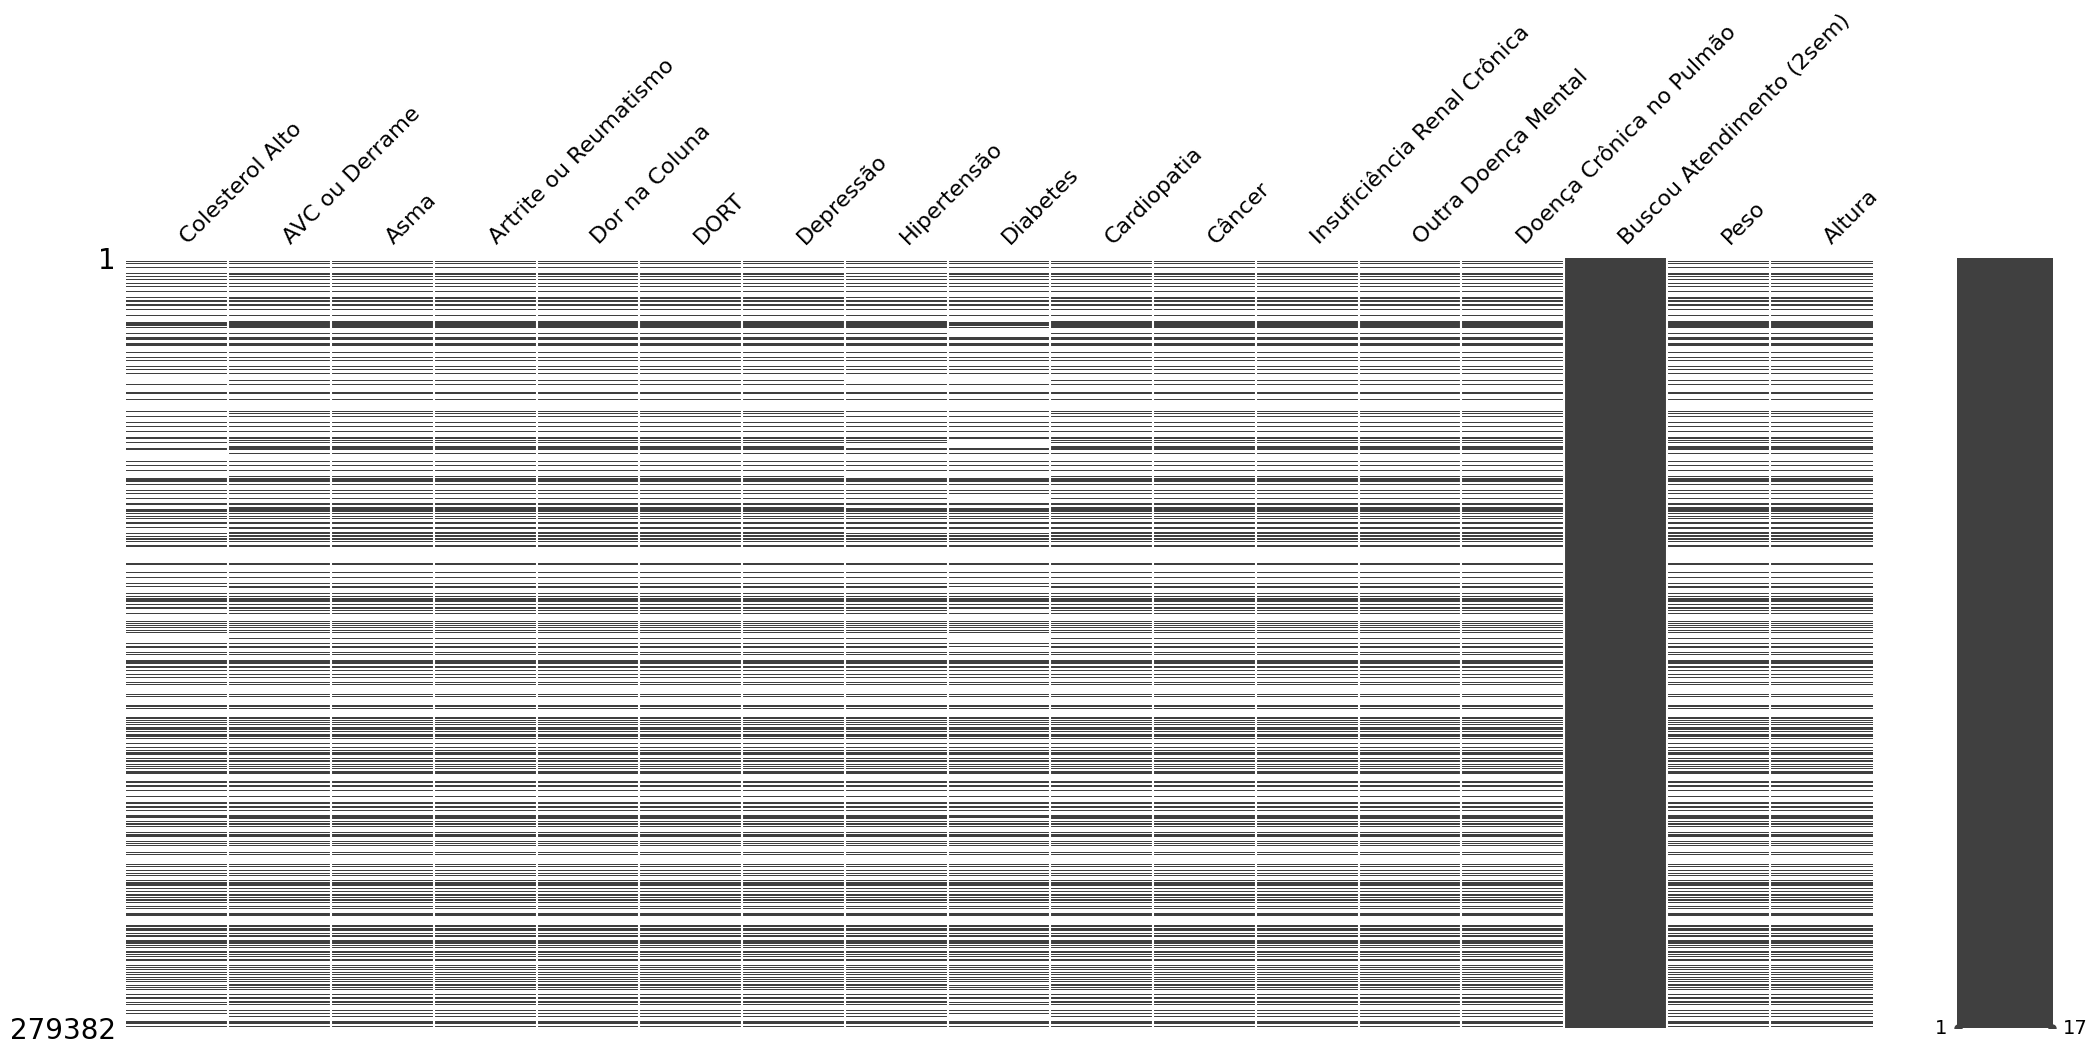

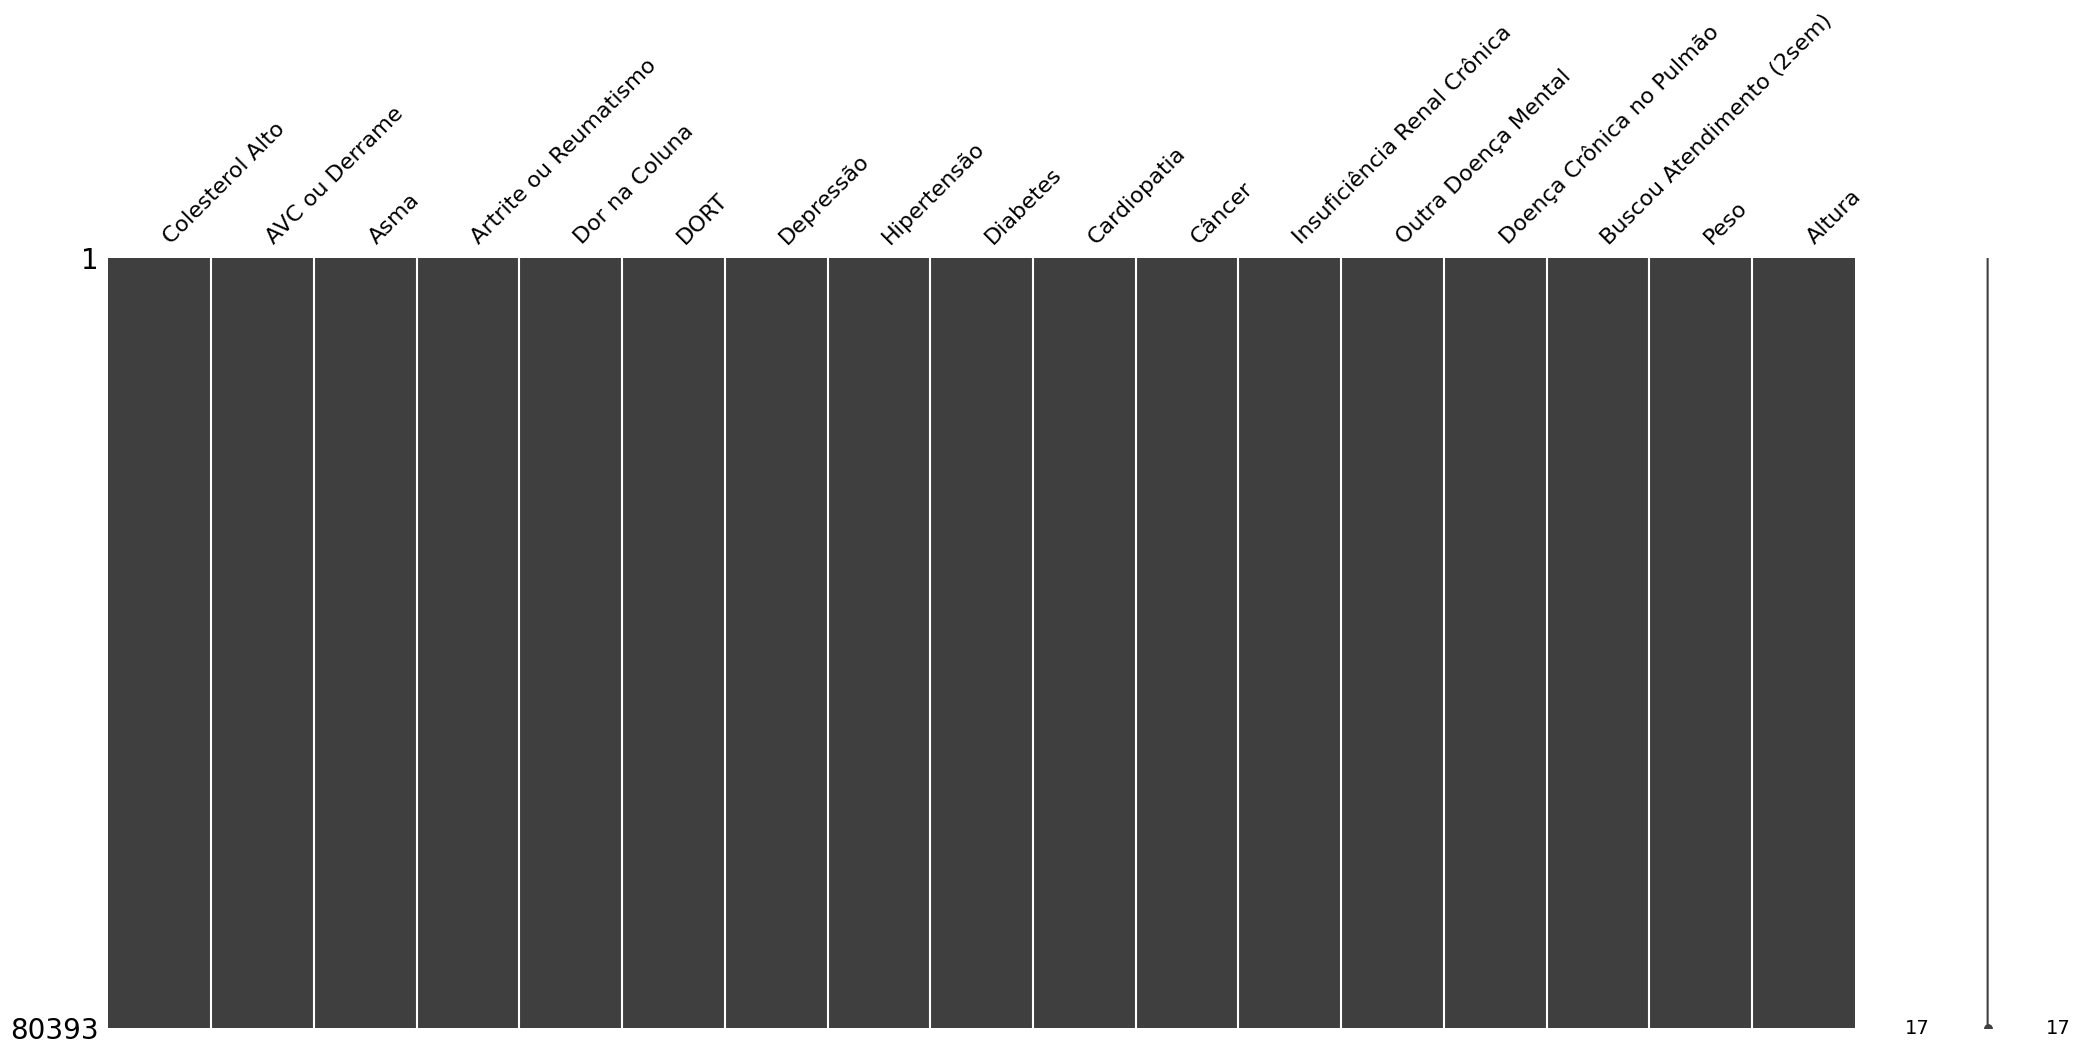

In [ ]:
# novo dataframe para esta etapa
plano_amostral_1311 = plano_amostral_123.copy()

# colunas de interesse
cols_interesse = [
    "Colesterol Alto",
    "AVC ou Derrame",
    "Asma",
    "Artrite ou Reumatismo",
    "Dor na Coluna",
    "DORT",
    "Depressão",
    "Hipertensão",
    "Diabetes",
    "Cardiopatia",
    "Câncer",
    "Insuficiência Renal Crônica",
    "Outra Doença Mental",
    "Doença Crônica no Pulmão",
    "Buscou Atendimento (2sem)",
    "Peso",
    "Altura",
]

# garante que só usamos colunas que existem no DataFrame
cols_existentes = [c for c in cols_interesse if c in plano_amostral_1311.columns]

# visualiza faltantes ANTES do filtro (somente nas colunas de interesse) ===
msno.matrix(plano_amostral_1311[cols_existentes])

# define colunas obrigatórias para manter a linha ===
cols_obrigatorias = [c for c in ["Colesterol Alto", "Hipertensão", "Diabetes", "Peso"]
                     if c in plano_amostral_1311.columns]

# índices válidos: mantém linhas SEM NA nessas colunas obrigatórias
if cols_obrigatorias:
    indices_validos = plano_amostral_1311[cols_obrigatorias].notna().all(axis=1)
    plano_amostral_1311 = plano_amostral_1311.loc[indices_validos].copy()

# visualiza faltantes DEPOIS do filtro (colunas de interesse) ===
msno.matrix(plano_amostral_1311[cols_existentes])

# inspeção
nlin, ncol = plano_amostral_1311.shape
print(f"Linhas: {nlin:,} | Colunas: {ncol}")

#### **1.3.1.2 - Segmentação da População Adulta**

Nesta etapa do processo, realizamos a seleção das linhas com idade de 18 anos ou mais. Excluindo os casos em que se sabe que o indivíduo é menor de idade, já que o foco da pesquisa permanece voltado à população adulta.



In [ ]:
# novo dataframe para esta etapa
plano_amostral_1312 = plano_amostral_1311.copy()

# mantém linhas onde Idade é NA OU Idade >= 18
idade_num = pd.to_numeric(plano_amostral_1312["Idade"], errors="coerce")
mask = (idade_num >= 18) # | idade_num.isna()
plano_amostral_1312 = plano_amostral_1312.loc[mask].copy()

# inspeção
nlin, ncol = plano_amostral_1312.shape
print(f"Linhas: {nlin:,} | Colunas: {ncol}")
plano_amostral_1312.head(5)

Linhas: 78,999 | Colunas: 82


,UF,Estrato,Ordem do Domicílio,Zona,Cadastro UBS,Visita ACS,Ordem Morador,Sexo,Idade,Cor/Raça,...,Câncer,Câncer Limita Atividades,Insuficiência Renal Crônica,Insuficiência Renal Limita Atividades,Última Consulta (H),Motivo da Consulta,Local do Atendimento,Peso Amostral,Grau de Ensino,Faixa Renda PC
0,Rondônia,1110011,1,Urbano,Sim,Uma vez,1,Mulher,55,Branca,...,Não,None,Não,None,Mais de 15 dias até 1 mês,Continuação de tratamento ou terapia,Unidade básica de saúde (posto ou centro de sa...,9.008903e-07,Fundamental incompleto ou equivalente,Mais de ¼ até ½ salário mínimo
9,Rondônia,1110011,2,Urbano,Sim,Nunca recebeu,4,Mulher,19,Parda,...,Não,None,Não,None,Mais de 1 mês até 6 meses,Exame médico periódico,Consultório particular ou clínica privada,9.008871e-07,Médio incompleto ou equivalente,Mais de ¼ até ½ salário mínimo
10,Rondônia,1110011,3,Urbano,Sim,Uma vez,1,Mulher,45,Preta,...,Não,None,Não,None,Mais de 6 meses até 1 ano,None,None,9.008887e-07,Médio completo ou equivalente,Mais de ½ até 1 salário mínimo
18,Rondônia,1110011,4,Urbano,Sim,Nunca recebeu,1,Mulher,58,Preta,...,Não,None,Não,None,Mais de 6 meses até 1 ano,None,None,9.008879e-07,Sem instrução,Mais de ¼ até ½ salário mínimo
19,Rondônia,1110011,5,Urbano,Sim,Nunca recebeu,1,Mulher,28,Parda,...,Não,None,Não,None,Mais de 1 mês até 6 meses,None,None,9.008871e-07,Superior incompleto ou equivalente,Até ¼ salário mínimo


### **1.3.2 - Transformação de Dados**

Nesta etapa é realizada a transformação de variáveis para tornar a base mais informativa e pronta para modelagem. Derivar indicadores a partir de medidas originais (ex.: transformar peso e altura em IMC).

#### **1.3.2.1 - Padronização de Versão da Base**

Nesta etapa realizamos um pré-processamento de consistência dos dados para garantir que a base de trabalho esteja inteiramente numérica, pronta para análises estatísticas e modelagem.

In [ ]:
# novo dataframe para esta etapa
plano_amostral_1321 = plano_amostral_1312.copy()

# dicionários de mapeamento (código -> rótulo) com nomes atualizados
MAPAS = {
    # Geografia / amostral
    "UF": {
        11: "Rondônia", 12: "Acre", 13: "Amazonas", 14: "Roraima", 15: "Pará", 16: "Amapá", 17: "Tocantins",
        21: "Maranhão", 22: "Piauí", 23: "Ceará", 24: "Rio Grande do Norte", 25: "Paraíba", 26: "Pernambuco",
        27: "Alagoas", 28: "Sergipe", 29: "Bahia", 31: "Minas Gerais", 32: "Espírito Santo",
        33: "Rio de Janeiro", 35: "São Paulo", 41: "Paraná", 42: "Santa Catarina", 43: "Rio Grande do Sul",
        50: "Mato Grosso do Sul", 51: "Mato Grosso", 52: "Goiás", 53: "Distrito Federal",
    },
    "Zona": {1: "Rural", 2: "Urbana"},
    "Grau de Ensino": {
        1: "Sem instrução", 2: "Fundamental incompleto ou equivalente",
        3: "Fundamental completo ou equivalente", 4: "Médio incompleto ou equivalente",
        5: "Médio completo ou equivalente", 6: "Superior incompleto ou equivalente",
        7: "Superior completo",
    },
    "Faixa Renda PC": {
        1: "Até ¼ salário mínimo", 2: "Mais de ¼ até ½ salário mínimo",
        3: "Mais de ½ até 1 salário mínimo",
        4: "Mais de 1 até 2 salários mínimos (R$ 998,01 até R$ 1996,00)",
        5: "Mais de 2 até 3 salários mínimos", 6: "Mais de 3 até 5 salários mínimos",
        7: "Mais de 5 salários mínimos",
    },

    # Domicílio / acesso a serviços
    "Cadastro UBS": {1: "Sim", 2: "Não", 3: "Não sabe", 9: "Ignorado"},
    "Visita ACS": {1: "Mensalmente", 2: "A cada 2 meses", 3: "De 2 a 4 vezes", 4: "Uma vez", 5: "Nunca recebeu", 9: "Ignorado"},

    # Características individuais
    "Sexo": {1: "Homem", 2: "Mulher"},
    "Cor/Raça": {1: "Branca", 2: "Preta", 3: "Amarela", 4: "Parda", 5: "Indígena", 9: "Ignorado"},
    "Estado Civil": {1: "Casado(a)", 2: "Divorciado(a)/desquitado(a)/separado(a) judicialmente", 3: "Viúvo(a)", 4: "Solteiro(a)", 9: "Ignorado"},
    "Alfabetizado": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Na Escola": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Trabalha": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Plano de Saúde": {1: "Sim", 2: "Não", 9: "Ignorado"},

    # Uso/estado de saúde
    "Saúde Geral": {1: "Muito bom", 2: "Bom", 3: "Regular", 4: "Ruim", 5: "Muito ruim", 9: "Ignorado"},
    "Última Consulta Médica": {1: "Até 1 ano", 2: "Mais de 1 a 2 anos", 3: "Mais de 2 a 3 anos", 4: "Mais de 3 anos", 5: "Nunca foi ao médico", 9: "Ignorado"},
    "Buscou Atendimento (2sem)": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Atend. Coberto Plano": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Pagou Atendimento (2sem)": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Atendimento SUS": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra"},
    "Receitou Medicamento": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Obteve Medicamentos": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Motivo Não Obter Meds": {
        1: "Não conseguiu obter no serviço público de saúde",
        2: "Não conseguiu no Aqui Tem Farmácia Popular",
        3: "Sem farmácia próxima/dificuldade de transporte",
        4: "Não encontrou todos na farmácia",
        5: "Não tinha dinheiro",
        6: "Não achou necessário",
        7: "Desistiu (melhorou)",
        8: "Outro",
        9: "Ignorado",
    },
    "Medicamento Coberto Plano": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Meds Farmácia Popular": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Meds Serviço Público": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Pagou Medicamentos": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Internação 12m": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Internação Coberta Plano": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Pagou Internação": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Internação SUS": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra"},
    "Urgência no Domicílio": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Urgência Coberta Plano": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Pagou Urgência": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Urgência SUS": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra"},
    "Ambulância": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Medicamento Contínuo": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra", 9: "Ignorado"},
    "Vacina Gripe (12m)": {1: "Sim", 2: "Não", 9: "Ignorado"},

    # Estilo de vida
    "Álcool": {1: "Não bebo nunca", 2: "Menos de uma vez por mês", 3: "Uma vez ou mais por mês", 9: "Ignorado"},
    "Exercício Físico": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Tabaco": {1: "Sim, diariamente", 2: "Sim, menos que diariamente", 3: "Não fumo atualmente", 9: "Ignorado"},

    # Condições: binárias (Sim/Não/Ignorado)
    "Colesterol Alto": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "AVC ou Derrame": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Asma": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Artrite ou Reumatismo": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Dor na Coluna": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "DORT": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Depressão": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Hipertensão": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Hipertensão na Gestação": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Diabetes": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Diabetes na Gestação": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Cardiopatia": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Câncer": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Insuficiência Renal Crônica": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Outra Doença Mental": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Doença Crônica no Pulmão": {1: "Sim", 2: "Não", 9: "Ignorado"},

    # Likert (1..5 + 9 Ignorado)
    "AVC Limita Atividades":              {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Asma Limita Atividades":             {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Artrite/Reumatismo Limita":          {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Dor na Coluna Limita Atividades":    {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "DORT Limita Atividades":             {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Depressão Limita Atividades":        {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Hipertensão Limita Atividades":      {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Diabetes Limita Atividades":         {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Cardiopatia Limita Atividades":      {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Câncer Limita Atividades":           {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Insuficiência Renal Limita":         {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Doença Pulmão Limita":               {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},

    # Módulo H (referências médicas)
    "Última Consulta (H)": {1: "Até 15 dias", 2: "Mais de 15 dias até 1 mês", 3: "Mais de 1 mês até 6 meses",
                            4: "Mais de 6 meses até 1 ano", 5: "Há mais de 1 ano", 9: "Ignorado"},
    "Motivo da Consulta": {
        1: "Acidente ou lesão",
        2: "Continuação de tratamento ou terapia",
        3: "Consulta pré-natal",
        4: "Exame médico periódico",
        5: "Outro exame médico",
        6: "Problema de saúde mental",
        7: "Doença ou outro problema de saúde",
        8: "Outro",
        9: "Ignorado",
    },
    "Local do Atendimento": {
        1: "UBS/USF",
        2: "Centro de Especialidades/Policlínica/PAM",
        3: "CAPS",
        4: "UPA",
        5: "Outro PA público (24h)",
        6: "PS/emergência hospital público",
        7: "Hospital público/ambulatório",
        8: "Consultório/Clínica privada",
        9: "Ambulatório/consultório de empresa/sindicato",
        10: "PA/emergência hospital privado",
        11: "Domicílio - médico particular",
        12: "Domicílio - médico ESF",
        13: "Outro",
        99: "Ignorado",
    },
}

def _is_categorical_series(s: pd.Series) -> bool:
    return isinstance(s.dtype, CategoricalDtype)

def _has_nominal(df: pd.DataFrame, cols: list[str]) -> bool:
    for c in cols:
        if c in df.columns and (is_object_dtype(df[c]) or _is_categorical_series(df[c])):
            return True
    return False

# checagem de colunas-alvo presentes na base
cols_alvo = [c for c in MAPAS.keys() if c in plano_amostral_1321.columns]
base_nominal = _has_nominal(plano_amostral_1321, cols_alvo)

# conversão: se a base veio NOMINAL (strings rótulos), converte para códigos numéricos
if base_nominal:
    for col, mapa in MAPAS.items():
        if col in plano_amostral_1321.columns and (is_object_dtype(plano_amostral_1321[col]) or _is_categorical_series(plano_amostral_1321[col])):
            inv = {v: k for k, v in mapa.items()}
            plano_amostral_1321[col] = pd.to_numeric(plano_amostral_1321[col].map(inv), errors="coerce")
    status_conv = "Base estava NOMINAL → convertida para NUMÉRICA em plano_amostral_1321."
else:
    status_conv = "Base já estava NUMÉRICA → mantida em plano_amostral_1321."

# relatório
print("Tratamento de versão concluído.")
print(f"• Colunas-alvo presentes: {len(cols_alvo)} de {len(MAPAS)} possíveis")
print(f"• Situação: {status_conv}")
print(f"• Dimensões atuais: {plano_amostral_1321.shape[0]} linhas × {plano_amostral_1321.shape[1]} colunas")

Tratamento de versão concluído.
• Colunas-alvo presentes: 70 de 71 possíveis
• Situação: Base estava NOMINAL → convertida para NUMÉRICA em plano_amostral_1321.
• Dimensões atuais: 78999 linhas × 82 colunas


#### **1.3.2.2 - Normalização do Peso Amostral**

Nesta etapa, padronizamos e preparamos os pesos amostrais para uso consistente. Primeiro, garantimos que o campo “Peso amostral” esteja numérico e o copiamos para peso_pop, preservando o peso calibrado original do microdado (o que reflete a expansão para a população). Em seguida, calculamos uma constante de normalização const_norm = n_amostra / soma(peso_pop) e criamos peso_norm = peso_pop * const_norm, de modo que a soma dos pesos normalizados seja igual ao tamanho da amostra.

**Referências:**

[Fiocruz – “Cálculo dos Indicadores” (Módulos N/R, PNS 2019)](https://www.pns.icict.fiocruz.br/calculo-dos-indicadores-modulo-r-2019/?utm_source=chatgpt.com): tutoriais que mostram, passo a passo, como carregar microdados, definir pesos e filtrar respondentes antes de criar indicadores

In [ ]:
# novo dataframe para esta etapa
plano_amostral_1322 = plano_amostral_1321.copy()

COL_PESO = "Peso Amostral"

# checa se a coluna existe
if COL_PESO not in plano_amostral_1322.columns:
    raise KeyError(f"Não encontrei a coluna '{COL_PESO}'.")

# garante numérico
plano_amostral_1322[COL_PESO] = pd.to_numeric(plano_amostral_1322[COL_PESO], errors="coerce")

# checa NA/infinito/valores inválidos
na_count = plano_amostral_1322[COL_PESO].isna().sum()
if na_count > 0:
    raise ValueError(f"Existem {na_count} registros sem '{COL_PESO}'. Trate/filtre antes de normalizar.")

inf_count = np.isinf(plano_amostral_1322[COL_PESO]).sum()
if inf_count > 0:
    raise ValueError(f"Existem {inf_count} registros infinitos em '{COL_PESO}'. Trate/filtre antes de normalizar.")

neg_count = (plano_amostral_1322[COL_PESO] < 0).sum()
if neg_count > 0:
    raise ValueError(f"Existem {neg_count} registros negativos em '{COL_PESO}'. Verifique os dados.")

zero_count = (plano_amostral_1322[COL_PESO] == 0).sum()
if zero_count > 0:
    print(f"Aviso: {zero_count} registros com '{COL_PESO} = 0'. Eles não contribuirão para o peso populacional.")

# peso populacional (como no microdado calibrado)
plano_amostral_1322["Peso Populacional"] = plano_amostral_1322[COL_PESO].astype(float)

# constante de normalização: soma(Peso Normalizado) = tamanho da amostra
n_amostra     = len(plano_amostral_1322)
soma_peso_pop = float(plano_amostral_1322["Peso Populacional"].sum())

if not np.isfinite(soma_peso_pop) or soma_peso_pop <= 0:
    raise ValueError("Soma do 'Peso Populacional' é inválida (<=0 ou não finita).")

const_norm = n_amostra / soma_peso_pop

# peso normalizado à amostra
plano_amostral_1322["Peso Normalizado"] = plano_amostral_1322["Peso Populacional"] * const_norm

# checagem objetiva
soma_norm = float(plano_amostral_1322["Peso Normalizado"].sum())
resultado = {
    "Tamanho da Amostra": int(n_amostra),
    "Soma do Peso Populacional": soma_peso_pop,
    "Constante de Normalização": const_norm,
    "Soma do Peso Normalizado": soma_norm
}
print(resultado)

# verificação de aderência numérica
tol = 1e-6 * n_amostra
if abs(soma_norm - n_amostra) > tol:
    print(f"Aviso: soma do 'Peso Normalizado' ({soma_norm:.6f}) difere do tamanho da amostra ({n_amostra}) acima da tolerância ({tol:.6f}).")

{'Tamanho da Amostra': 78999, 'Soma do Peso Populacional': 0.03075466525877571, 'Constante de Normalização': 2568683.4610387436, 'Soma do Peso Normalizado': 78999.00000000001}


#### **1.3.2.3 - Peso e Altura para IMC**

Nesta etapa calculamos o IMC = peso(kg) / [altura(m)]². E a partir do IMC, geramos duas variáveis úteis:

- Obesidade (Sim/Não), marcada como categórica binária (níveis Não, Sim);

- Classe IMC, categórica ordenada com quatro faixas (Baixo peso, Peso normal, Sobrepeso, Obesidade) usando pontos de corte usuais.

Ao final, a base passa a conter IMC, Obesidade e Classe IMC, prontas para serem usadas tanto em análises descritivas quanto em etapas posteriores de agrupamento ou modelagem.

**Referências:**

[Rimes-Dias et al., 2022 – BMC Public Health (PNS 2013)](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-022-13906-2): usa peso/altura para calcular e categorizar IMC segundo a OMS em análises de utilização de serviços.

In [ ]:
# novo dataframe para esta etapa
plano_amostral_1323 = plano_amostral_1322.copy()

# garante tipo numérico e evita divisões por zero/negativas
peso_num  = pd.to_numeric(plano_amostral_1323["Peso"],   errors="coerce")
altura_cm = pd.to_numeric(plano_amostral_1323["Altura"], errors="coerce")

altura_m  = altura_cm / 100.0
altura_ok = altura_m > 0

# IMC = peso(kg) / [altura(m)]^2
plano_amostral_1323["IMC"] = np.where(
    altura_ok,
    peso_num / (altura_m ** 2),
    np.nan
)

# Binária “Obesidade” (Sim/Não)
plano_amostral_1323["Obesidade"] = np.where(
    plano_amostral_1323["IMC"] >= 30, "Sim", "Não"
)
plano_amostral_1323["Obesidade"] = pd.Categorical(
    plano_amostral_1323["Obesidade"], categories=["Não","Sim"]
)

# classes OMS/NIH
bins   = [-np.inf, 18.5, 25.0, 30.0, np.inf]
labels = ["Baixo peso", "Peso normal", "Sobrepeso", "Obesidade"]

plano_amostral_1323["Classe IMC"] = pd.cut(
    plano_amostral_1323["IMC"],
    bins=bins,
    labels=labels,
    right=False,
    ordered=True
)

# resumo
plano_amostral_1323[["Peso","Altura","IMC","Classe IMC","Obesidade"]].head()

,Peso,Altura,IMC,Classe IMC,Obesidade
0,60.0,145.0,28.537455,Sobrepeso,Não
9,65.0,152.0,28.133657,Sobrepeso,Não
10,77.0,155.0,32.049948,Obesidade,Sim
18,56.0,159.0,22.151023,Peso normal,Não
19,55.0,176.0,17.755682,Baixo peso,Não


#### **1.3.2.4 - Estados para Regiões**

Nesta etapa criamos a coluna “Grandes Regiões” a partir da UF, mapeando cada estado para Norte, Nordeste, Sudeste, Sul ou Centro-Oeste, conforme a divisão macrorregional oficial do IBGE. Isso padroniza a análise espacial e permite comparar resultados por blocos territoriais amplamente usados em estatísticas públicas e na literatura.

In [ ]:
# novo dataframe para esta etapa
plano_amostral_1324 = plano_amostral_1323.copy()

# garante UF numérica
plano_amostral_1324["UF"] = pd.to_numeric(plano_amostral_1324["UF"], errors="coerce")

# mapeamento IBGE (UF numérica -> Grandes Regiões)
UF_TO_REGIAO = {
    # Norte
    11: "Norte", 12: "Norte", 13: "Norte", 14: "Norte", 15: "Norte", 16: "Norte", 17: "Norte",
    # Nordeste
    21: "Nordeste", 22: "Nordeste", 23: "Nordeste", 24: "Nordeste", 25: "Nordeste",
    26: "Nordeste", 27: "Nordeste", 28: "Nordeste", 29: "Nordeste",
    # Sudeste
    31: "Sudeste", 32: "Sudeste", 33: "Sudeste", 35: "Sudeste",
    # Sul
    41: "Sul", 42: "Sul", 43: "Sul",
    # Centro-Oeste
    50: "Centro-Oeste", 51: "Centro-Oeste", 52: "Centro-Oeste", 53: "Centro-Oeste",
}

# cria coluna de Grandes Regiões com categoria ordenada
ordem = ["Norte", "Nordeste", "Sudeste", "Sul", "Centro-Oeste"]
cat_reg = pd.api.types.CategoricalDtype(categories=ordem, ordered=True)

plano_amostral_1324["Grandes Regioes"] = (
    plano_amostral_1324["UF"].map(UF_TO_REGIAO).astype(cat_reg)
)

# checagem rápida
plano_amostral_1324["Grandes Regioes"].value_counts(dropna=False)

,count
Grandes Regioes,
Nordeste,26904
Sudeste,18228
Norte,14280
Sul,10392
Centro-Oeste,9195


### **1.3.3 - Geração das Versões Numérica e Nominal para Cache**

Nesta etapa você define todos os dicionários de rótulos (MAPAS) e informa quais colunas devem permanecer numéricas. Em seguida, o script tenta carregar do cache as duas versões da base.

#### **1.3.3.1 - Mapas de Dicionário**

In [ ]:
# ================================
# MAPAS (código -> rótulo)
# ================================
MAPAS_1331 = {
    # Geografia / Estrato
    "UF": {
        11: "Rondônia", 12: "Acre", 13: "Amazonas", 14: "Roraima", 15: "Pará", 16: "Amapá", 17: "Tocantins",
        21: "Maranhão", 22: "Piauí", 23: "Ceará", 24: "Rio Grande do Norte", 25: "Paraíba", 26: "Pernambuco",
        27: "Alagoas", 28: "Sergipe", 29: "Bahia",
        31: "Minas Gerais", 32: "Espírito Santo", 33: "Rio de Janeiro", 35: "São Paulo",
        41: "Paraná", 42: "Santa Catarina", 43: "Rio Grande do Sul",
        50: "Mato Grosso do Sul", 51: "Mato Grosso", 52: "Goiás", 53: "Distrito Federal",
    },
    "Zona": {1: "Rural", 2: "Urbana"},

    # Socioeconômicas
    "Grau de Ensino": {
        1: "Sem instrução", 2: "Fundamental incompleto ou equivalente",
        3: "Fundamental completo ou equivalente", 4: "Médio incompleto ou equivalente",
        5: "Médio completo ou equivalente", 6: "Superior incompleto ou equivalente",
        7: "Superior completo",
    },
    "Faixa Renda PC": {
        1: "Até ¼ salário mínimo", 2: "Mais de ¼ até ½ salário mínimo",
        3: "Mais de ½ até 1 salário mínimo", 4: "Mais de 1 até 2 salários mínimos (R$ 998,01 até R$ 1996,00)",
        5: "Mais de 2 até 3 salários mínimos", 6: "Mais de 3 até 5 salários mínimos",
        7: "Mais de 5 salários mínimos",
    },

    # Cadastro/visitas
    "Cadastro UBS": {1: "Sim", 2: "Não", 3: "Não sabe", 9: "Ignorado"},
    "Visita ACS": {1: "Mensalmente", 2: "A cada 2 meses", 3: "De 2 a 4 vezes", 4: "Uma vez", 5: "Nunca recebeu", 9: "Ignorado"},

    # Demográficas
    "Sexo": {1: "Homem", 2: "Mulher"},
    "Cor/Raça": {1: "Branca", 2: "Preta", 3: "Amarela", 4: "Parda", 5: "Indígena", 9: "Ignorado"},
    "Estado Civil": {1: "Casado(a)", 2: "Divorciado(a)/desquitado(a)/separado(a) judicialmente", 3: "Viúvo(a)", 4: "Solteiro(a)", 9: "Ignorado"},

    # Educação / Trabalho
    "Alfabetizado": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Na Escola": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Trabalha": {1: "Sim", 2: "Não", 9: "Ignorado"},

    # Acesso/uso de saúde
    "Plano de Saúde": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Saúde Geral": {1: "Muito bom", 2: "Bom", 3: "Regular", 4: "Ruim", 5: "Muito ruim", 9: "Ignorado"},
    "Última Consulta Médica": {1: "Até 1 ano", 2: "Mais de 1 ano a 2 anos", 3: "Mais de 2 anos a 3 anos", 4: "Mais de 3 anos", 5: "Nunca foi ao médico", 9: "Ignorado"},
    "Buscou Atendimento (2sem)": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Atend. Coberto Plano": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Pagou Atendimento (2sem)": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Atendimento SUS": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra"},
    "Receitou Medicamento": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Obteve Medicamentos": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Medicamento Coberto Plano": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Meds Farmácia Popular": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Meds Serviço Público": {1: "Sim, todos", 2: "Sim, alguns", 3: "Não, nenhum", 9: "Ignorado"},
    "Pagou Medicamentos": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Motivo Não Obter Meds": {
        1: "Não conseguiu obter no serviço público de saúde",
        2: "Não conseguiu o(s) medicamento(s) no programa Aqui Tem Farmácia Popular",
        3: "Não tinha farmácia próxima ou teve dificuldade de transporte",
        4: "Não conseguiu encontrar todos os medicamentos na farmácia",
        5: "Não tinha dinheiro para comprar",
        6: "Não achou necessário",
        7: "Desistiu de procurar, pois melhorou",
        8: "Outro",
        9: "Ignorado",
    },

    # Internações e urgência
    "Internação 12m": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Internação Coberta Plano": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Pagou Internação": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Internação SUS": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra"},
    "Urgência no Domicílio": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Urgência Coberta Plano": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Pagou Urgência": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Urgência SUS": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra"},
    "Ambulância": {1: "Sim", 2: "Não", 9: "Ignorado"},

    # Medicamentos/Vacinas
    "Medicamento Contínuo": {1: "Sim", 2: "Não", 3: "Não sabe/Não lembra", 9: "Ignorado"},
    "Nº Meds Contínuos (2sem)": None,  # quantitativa
    "Vacina Gripe (12m)": {1: "Sim", 2: "Não", 9: "Ignorado"},

    # Estilo de vida
    "Álcool": {1: "Não bebo nunca", 2: "Menos de uma vez por mês", 3: "Uma vez ou mais por mês", 9: "Ignorado"},
    "Exercício Físico": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Tabaco": {1: "Sim, diariamente", 2: "Sim, menos que diariamente", 3: "Não fumo atualmente", 9: "Ignorado"},

    # Doenças (Sim/Não/Ignorado)
    "Hipertensão": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Hipertensão na Gestação": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Diabetes": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Diabetes na Gestação": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Colesterol Alto": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Cardiopatia": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "AVC ou Derrame": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Asma": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Artrite ou Reumatismo": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Dor na Coluna": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "DORT": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Depressão": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Outra Doença Mental": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Doença Crônica no Pulmão": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Câncer": {1: "Sim", 2: "Não", 9: "Ignorado"},
    "Insuficiência Renal Crônica": {1: "Sim", 2: "Não", 9: "Ignorado"},

    # Limitação das atividades (Likert 1..5 + 9)
    "Hipertensão Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Diabetes Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Cardiopatia Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "AVC Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Asma Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Artrite/Reumatismo Limita": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Dor na Coluna Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "DORT Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Depressão Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Outra Doença Mental Limita": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Doença Pulmão Limita": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Câncer Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},
    "Insuficiência Renal Limita Atividades": {1: "Não limita", 2: "Um pouco", 3: "Moderadamente", 4: "Intensamente", 5: "Muito intensamente", 9: "Ignorado"},

    # H módulo
    "Última Consulta (H)": {1: "Até 15 dias", 2: "Mais de 15 dias até 1 mês", 3: "Mais de 1 mês até 6 meses", 4: "Mais de 6 meses até 1 ano", 5: "Há mais de 1 ano", 9: "Ignorado"},
    "Motivo da Consulta": {1: "Acidente ou lesão", 2: "Continuação de tratamento ou terapia", 3: "Consulta pré-natal", 4: "Exame médico periódico", 5: "Outro exame médico (admissional, para carteira de motorista, etc)", 6: "Problema de saúde mental", 7: "Doença ou outro problema de saúde", 8: "Outro (Especifique:__)", 9: "Ignorado"},
    "Local do Atendimento": {
        1: "Unidade básica de saúde (posto ou centro de saúde ou unidade de saúde da família)",
        2: "Centro de Especialidades, Policlínica pública ou PAM – Posto de Assistência Médica",
        3: "CAPS – Centro de Atenção Psicossocial",
        4: "UPA (Unidade de Pronto Atendimento)",
        5: "Outro tipo de Pronto Atendimento Público (24 horas)",
        6: "Pronto-socorro ou emergência de hospital público",
        7: "Hospital público/ambulatório",
        8: "Consultório particular ou clínica privada",
        9: "Ambulatório ou consultório de empresa ou sindicato",
        10: "Pronto-atendimento ou emergência de hospital privado",
        11: "No domicílio, com médico particular",
        12: "No domicílio, com médico da equipe de saúde da família",
        13: "Outro (Especifique:__)",
        99: "Ignorado",
    },
}

# variáveis derivadas do pipeline (ex.: regiões e imc)
REGIAO_MAP_1331    = {1: "Norte", 2: "Nordeste", 3: "Sudeste", 4: "Sul", 5: "Centro-Oeste"}
IMC_CLASS_MAP_1331 = {1: "Baixo peso", 2: "Peso normal", 3: "Sobrepeso", 4: "Obesidade"}
OBES_MAP_1331      = {1: "Sim", 2: "Não"}

MAPAS_1331.update({
    "Grandes Regioes": REGIAO_MAP_1331,
    "Classe IMC": IMC_CLASS_MAP_1331,
    "Obesidade": OBES_MAP_1331,
})

# colunas numéricas puras (não mapear)
NUMERICAS_PURAS_1331 = {
    "Peso", "Altura", "Idade", "Ordem Morador", "Peso Amostral", "IMC",
    "Consultas 12m", "Nº Internações 12m", "Nº Meds Contínuos (2sem)",
}

# helper para likert
LIKERT_SET_1331 = {"Não limita", "Um pouco", "Moderadamente", "Intensamente", "Muito intensamente"}
LIKERT_ORD_1331 = ["Não limita", "Um pouco", "Moderadamente", "Intensamente", "Muito intensamente"]

#### **1.3.3.2 - Processamento das Bases**

In [ ]:
# cópias de seções anteriores
MAPAS            = MAPAS_1331.copy()
NUMERICAS_PURAS  = set(NUMERICAS_PURAS_1331)
LIKERT_SET       = set(LIKERT_SET_1331)
LIKERT_ORD       = list(LIKERT_ORD_1331)
plano_amostral_1332 = plano_amostral_1324.copy()

# caminhos de saída
OUT_NUM = Path("plano_amostral_numerica_1332.parquet")
OUT_NOM = Path("plano_amostral_nominal_1332.parquet")

# tenta carregar do cache
if OUT_NUM.exists() and OUT_NOM.exists():
    plano_amostral_1332         = pd.read_parquet(OUT_NUM, engine="pyarrow")
    plano_amostral_nominal_1332 = pd.read_parquet(OUT_NOM, engine="pyarrow")
    cache_status = "Cache carregado (Numérica e Nominal)."

else:
    # parte 2: força colunas mapeadas a ficarem numéricas
    # (rótulo -> código onde houver texto/categorical)
    for col, mapa in MAPAS.items():
        if col in plano_amostral_1332.columns and col not in NUMERICAS_PURAS:
            if mapa is None:
                # variável quantitativa (tem nome no MAPAS, mas sem dicionário)
                plano_amostral_1332[col] = pd.to_numeric(plano_amostral_1332[col], errors="coerce")
                continue

            if is_object_dtype(plano_amostral_1332[col]) or isinstance(plano_amostral_1332[col].dtype, CategoricalDtype):
                inv = {v: k for k, v in mapa.items()}  # rótulo -> código
                plano_amostral_1332[col] = pd.to_numeric(
                    plano_amostral_1332[col].map(inv), errors="coerce"
                )
            else:
                plano_amostral_1332[col] = pd.to_numeric(plano_amostral_1332[col], errors="coerce")

    # parte 3: cria versão nominal (códigos -> rótulos)
    plano_amostral_nominal_1332 = plano_amostral_1332.copy()

    for col, mapa in MAPAS.items():
        if col in plano_amostral_nominal_1332.columns and col not in NUMERICAS_PURAS:
            if mapa is None:
                # quantitativa pura; nada a rotular
                continue

            # aplica rótulos
            plano_amostral_nominal_1332[col] = pd.to_numeric(
                plano_amostral_nominal_1332[col], errors="coerce"
            ).map(mapa)

            # ordena Likert quando aplicável
            vals = set(mapa.values())
            if LIKERT_SET.issubset(vals):
                categorias = LIKERT_ORD + (["Ignorado"] if "Ignorado" in vals else [])
                plano_amostral_nominal_1332[col] = pd.Categorical(
                    plano_amostral_nominal_1332[col], categories=categorias, ordered=True
                )

    # parte 4: salvar as duas bases
    plano_amostral_1332.to_parquet(OUT_NUM, engine="pyarrow", compression="snappy")
    plano_amostral_nominal_1332.to_parquet(OUT_NOM, engine="pyarrow", compression="snappy")
    cache_status = "Processamento concluído (novos arquivos salvos)."

# parte 5: relatório
print(cache_status)
print(f"• Numérica: {plano_amostral_1332.shape[0]} × {plano_amostral_1332.shape[1]} → {OUT_NUM.name}")
print(f"• Nominal:  {plano_amostral_nominal_1332.shape[0]} × {plano_amostral_nominal_1332.shape[1]} → {OUT_NOM.name}")

# inspeção (assume summarize_df disponível no notebook)
summarize_df(plano_amostral_1332)
summarize_df(plano_amostral_nominal_1332)

Processamento concluído (novos arquivos salvos).
• Numérica: 78999 × 88 → plano_amostral_numerica_1332.parquet
• Nominal:  78999 × 88 → plano_amostral_nominal_1332.parquet


,coluna,classe,tipo_inferido,n,n_na,prop_na,n_distinct,exemplos
0,Motivo Não Obter Meds,object,texto,78999,78147,98.92,3,"Não achou necessário, Não conseguiu obter no s..."
1,Doença Pulmão Limita,category,ordinal,78999,77810,98.49,5,"Não limita, Um pouco, Moderadamente, Intensame..."
2,Insuficiência Renal Limita Atividades,category,ordinal,78999,77781,98.46,5,"Não limita, Um pouco, Moderadamente, Intensame..."
3,DORT Limita Atividades,category,ordinal,78999,77371,97.94,5,"Não limita, Um pouco, Moderadamente, Intensame..."
4,AVC Limita Atividades,category,ordinal,78999,77105,97.60,5,"Não limita, Um pouco, Moderadamente, Intensame..."
...,...,...,...,...,...,...,...,...
83,Outra Doença Mental,object,texto,78999,0,0.00,2,"Não, Sim"
84,Doença Crônica no Pulmão,object,texto,78999,0,0.00,2,"Não, Sim"
85,Câncer,object,texto,78999,0,0.00,2,"Não, Sim"
86,Insuficiência Renal Crônica,object,texto,78999,0,0.00,2,"Não, Sim"


## **1.4 - Pre-Processamento para Agrupamento**

Essa etapa é realizado passos que preparam a base para métodos de agrupamento (K-means e LCA). A ideia é padronizar entradas, reduzir ruído e evitar vieses que distorçam distâncias ou dificultem a identificação de classes latentes.

### **1.4.1 - Carregar Base**

In [ ]:
# carregar base
ARQUIVO = Path("/content/plano_amostral_numerica_1332.parquet")
plano_amostral_141 = pd.read_parquet(ARQUIVO, engine="pyarrow")

print(f"Base: {plano_amostral_141.shape[0]:,} linhas × {plano_amostral_141.shape[1]:,} colunas")

Base: 78,999 linhas × 88 colunas


### **1.4.2 - Gerar escala de pesos para ML (média = 1)**

Esta etapa coloca os pesos “em escala” para não inflar artificialmente o tamanho efetivo da amostra, assim, apenas as relações relativas entre os pesos influenciam o ajuste

**Referências:**

[West et al. (2015)](https://pmc.ncbi.nlm.nih.gov/articles/PMC4605185/):
Mostram que reescalar pesos para que a soma iguale o tamanho da amostra evita “superestimar” o n efetivo em modelos com pesos de amostragem.

In [ ]:
# Novo dataframe para esta etapa
plano_amostral_142 = plano_amostral_141.copy()

# Se já existe "Peso Normalizado" (soma = n), aproveite-o; caso contrário, use "Peso Amostral"
if "Peso Normalizado" in plano_amostral_142.columns:
    peso_ml = plano_amostral_142["Peso Normalizado"].astype("float64")
else:
    w = pd.to_numeric(plano_amostral_142["Peso Amostral"], errors="coerce")
    # Escala para ML: média = 1 (evita alterar o n efetivo em modelos não-survey)
    peso_ml = (w / w.mean()).astype("float64")

# Anexa coluna com a escala de uso em ML
plano_amostral_142["Peso ML (média=1)"] = peso_ml

# Resumo compacto
n_amostra = len(peso_ml)
resumo_peso_ml = {
    "Tamanho da Amostra": int(n_amostra),
    "Média (≈1)": float(np.nanmean(peso_ml)),
    "Mínimo": float(np.nanmin(peso_ml)),
    "Máximo": float(np.nanmax(peso_ml)),
    "Soma": float(np.nansum(peso_ml)),
}
print(resumo_peso_ml)

{'Tamanho da Amostra': 78999, 'Média (≈1)': 1.0000000000000002, 'Mínimo': 0.4837227591900748, 'Máximo': 2.3141021420818886, 'Soma': 78999.00000000001}


### **1.4.3 - Recodificar comorbidades para binário (0/1)**

Para K-means e LCA, é prático trabalhar com indicadores binários (presença/ausência). Em microdados da PNS é comum: 1 = Sim, 2 = Não, 9/99 = Ignorado/NS/NR. A boa prática é transformar “Sim/Não” → 1/0 e tratar 9/99 como ausentes (NaN).

**Referências:**

[PNS/IBGE – Microdados](https://www.latentclassanalysis.com/wp-content/uploads/2021/01/proc_lca_lta_1-3-2-1_users_guide-2ggq4d3.pdf?utm_source=chatgpt.com):
Documentação e dicionários de variáveis seguem convenções como 1=Sim, 2=Não, 9=Ignorado.

[Compatibilidade com modelos](https://online.stat.psu.edu/stat462/node/161/?utm_source):
Muitos métodos (p.ex., regressão logística) e tutoriais assumem 0/1 para o desfecho binário e para indicadores, o que evita pré-processamento extra e facilita interpretação de coeficientes/odds ratios.

In [ ]:
# Novo dataframe para esta etapa
plano_amostral_143 = plano_amostral_142.copy()

# variáveis de interesse (comorbidades)
colunas_comorb = [
    "Hipertensão","Diabetes","Colesterol Alto","Cardiopatia","AVC ou Derrame",
    "Asma","Artrite ou Reumatismo","DORT","Depressão","Outra Doença Mental",
    "Doença Crônica no Pulmão","Câncer","Insuficiência Renal Crônica",
    "Dor na Coluna","Obesidade"
]

# força numérico (mantém NaN nos não conversíveis)
sub = plano_amostral_143[colunas_comorb].apply(pd.to_numeric, errors="coerce")

# 9/99 -> NaN (ignorado/NS/NR)
sub = sub.replace({9: np.nan, 99: np.nan})

# {1,2} -> {1,0}
sub = sub.replace({1: 1, 2: 0}).astype("float32")  # float permite NaN

# grava de volta no DF original desta etapa
plano_amostral_143.loc[:, colunas_comorb] = sub

# resumo
resumo = (
    plano_amostral_143[colunas_comorb]
    .agg(["count", "mean"])
    .T.rename(columns={"count": "n válidos", "mean": "prevalência (média)"})
)

print("Comorbidades recodificadas (0/1).")
print(resumo)

Comorbidades recodificadas (0/1).
                             n válidos  prevalência (média)
Hipertensão                    78999.0             0.290409
Diabetes                       78999.0             0.091697
Colesterol Alto                78999.0             0.167065
Cardiopatia                    78999.0             0.058191
AVC ou Derrame                 78999.0             0.023975
Asma                           78999.0             0.049330
Artrite ou Reumatismo          78999.0             0.088254
DORT                           78999.0             0.020608
Depressão                      78999.0             0.099609
Outra Doença Mental            78999.0             0.057874
Doença Crônica no Pulmão       78999.0             0.015051
Câncer                         78999.0             0.028621
Insuficiência Renal Crônica    78999.0             0.015418
Dor na Coluna                  78999.0             0.220104
Obesidade                      78999.0             0.213838


### **1.4.4 - Checagem de variância quase-zero (NZV) nas comorbidades**

Variáveis binárias com prevalência muito próxima de 0% ou 100% têm “variância quase-zero”. Elas pouco ajudam o K-means (dominam a distância sem diferenciar observações) e podem prejudicar LCA, gerando problemas de identificação e separação numérica. A boa prática é detectar essas variáveis e remover/agrupá-las antes da modelagem.

**prevalência_unweighted**
- É a prevalência simples (não ponderada) de cada comorbidade: a média da coluna 0/1 ignorando NaN.

**prevalência_weighted**
- É a prevalência ponderada pelos pesos (“Peso ML (média=1)”): média ponderada = sum(w*x)/sum(w), ignorando NaN em x ou w.

**Referências:**

[Applied Predictive Modeling (Kuhn & Johnson, 2013)](https://link.springer.com/book/10.1007/978-1-4614-6849-3):
Capítulo de pré-processamento/seleção de variáveis comenta filtragem de variância quase zero.

In [ ]:
# Novo dataframe para esta etapa
plano_amostral_144 = plano_amostral_143.copy()

# comorbidades
colunas_comorb = [
    "Hipertensão","Diabetes","Colesterol Alto","Cardiopatia","AVC ou Derrame",
    "Asma","Artrite ou Reumatismo","DORT","Depressão","Outra Doença Mental",
    "Doença Crônica no Pulmão","Câncer","Insuficiência Renal Crônica",
    "Dor na Coluna","Obesidade"
]

# matriz binária (permite NaN)
X_bin = plano_amostral_144[colunas_comorb].apply(pd.to_numeric, errors="coerce")

# limites NZV
LIMITE_INFERIOR = 0.01   # 1%
LIMITE_SUPERIOR = 0.99   # 99%

# Prevalência não ponderada
prev_unw = X_bin.mean(axis=0, skipna=True)

# Prevalência ponderada
peso_col = "Peso ML (média=1)"
if peso_col in plano_amostral_144.columns:
    w = pd.to_numeric(plano_amostral_144[peso_col], errors="coerce")
    prev_w = {}
    for c in X_bin.columns:
        x = X_bin[c]
        m = x.notna() & w.notna()
        prev_w[c] = (w[m] * x[m]).sum() / w[m].sum() if m.any() else np.nan
    prev_w = pd.Series(prev_w, name="prevalência_ponderada")
else:
    prev_w = pd.Series(index=X_bin.columns, dtype="float64", name="prevalência_ponderada")

# Flags NZV
flag_low_unw  = prev_unw <= LIMITE_INFERIOR
flag_high_unw = prev_unw >= LIMITE_SUPERIOR
flag_low_w    = prev_w   <= LIMITE_INFERIOR
flag_high_w   = prev_w   >= LIMITE_SUPERIOR

flag_nzv = (
    flag_low_unw.fillna(False)  | flag_high_unw.fillna(False) |
    flag_low_w.fillna(False)    | flag_high_w.fillna(False)
)

# Quadro resumo
resumo_nzv = (
    pd.DataFrame({
        "prevalência_unweighted": prev_unw,
        "prevalência_weighted":   prev_w,
        "NZV?":                   flag_nzv
    })
    .sort_values(by=["NZV?", "prevalência_weighted", "prevalência_unweighted"],
                 ascending=[False, True, True])
)

# lista das variáveis sinalizadas
variaveis_nzv = resumo_nzv.index[resumo_nzv["NZV?"]].tolist()

# print("Variáveis NZV (qualquer critério):")
# print(variaveis_nzv if variaveis_nzv else "Nenhuma variável sinalizada.")

print("\nResumo:")
display(resumo_nzv)

# remover NZV direto no DF da etapa
if variaveis_nzv:
    plano_amostral_144.drop(columns=variaveis_nzv, inplace=True)

print("\nDimensões pós-tratamento NZV:")
print({
    "Originais": (len(X_bin), X_bin.shape[1]),
    "Removidas NZV": len(variaveis_nzv),
    "Atuais no DF": len([c for c in colunas_comorb if c in plano_amostral_144.columns])
})


Resumo:


,prevalência_unweighted,prevalência_weighted,NZV?
Doença Crônica no Pulmão,0.015051,0.013429,False
Insuficiência Renal Crônica,0.015418,0.014624,False
DORT,0.020608,0.017959,False
AVC ou Derrame,0.023975,0.023994,False
Câncer,0.028621,0.025761,False
Asma,0.049330,0.047507,False
Outra Doença Mental,0.057874,0.051239,False
Cardiopatia,0.058191,0.053850,False
Artrite ou Reumatismo,0.088254,0.087752,False
Diabetes,0.091697,0.087833,False



Dimensões pós-tratamento NZV:
{'Originais': (78999, 15), 'Removidas NZV': 0, 'Atuais no DF': 15}


### **1.4.5 - Redundância alta entre comorbidades (correlação φ/Phi)**

Comorbidades binárias podem ser quase duplicatas (ex.: “Depressão” ↔ “Outra Doença Mental”). Isso distorce distâncias no K-means e dificulta identificação de classes na LCA. A prática é medir associação par-a-par com o coeficiente φ (Phi) — que é a correlação de Pearson aplicada a variáveis 0/1 e remover/sintetizar pares com |φ| muito alto (ex.: > 0,90). Quando há pesos amostrais, pode-se usar a versão ponderada (correlação de Pearson ponderada) para refletir a população.

**Referências:**

[Multicollinearity in Regression Analyses](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC4835615/):
Redundância/colinearidade atrapalha inferência e ajuste. Seção de impactos e mitigação.

In [ ]:
# Novo dataframe para esta etapa
plano_amostral_145 = plano_amostral_144.copy()

# Conjunto de comorbidades
cols_comorb = [
    "Hipertensão","Diabetes","Colesterol Alto","Cardiopatia","AVC ou Derrame",
    "Asma","Artrite ou Reumatismo","DORT","Depressão","Outra Doença Mental",
    "Doença Crônica no Pulmão","Câncer","Insuficiência Renal Crônica",
    "Dor na Coluna","Obesidade"
]
cols_comorb = [c for c in cols_comorb if c in plano_amostral_145.columns]

X = plano_amostral_145[cols_comorb].apply(pd.to_numeric, errors="coerce").astype("float32")
w = (plano_amostral_145["Peso ML (média=1)"].astype("float64")
     if "Peso ML (média=1)" in plano_amostral_145.columns else None)

LIMIAR = 0.90  # |φ| muito alto

# helpers
def _pearson(a, b):
    m = a.notna() & b.notna()
    if m.sum() < 2:
        return np.nan
    return np.corrcoef(a[m], b[m])[0, 1]

def _pearson_weighted(a, b, w):
    m = a.notna() & b.notna() & w.notna()
    if m.sum() < 2:
        return np.nan
    aw, bw, ww = a[m].astype("float64"), b[m].astype("float64"), w[m].astype("float64")
    wm = ww.sum()
    if wm <= 0:
        return np.nan
    ma = np.sum(ww * aw) / wm
    mb = np.sum(ww * bw) / wm
    cov = np.sum(ww * (aw - ma) * (bw - mb)) / wm
    va  = np.sum(ww * (aw - ma)**2) / wm
    vb  = np.sum(ww * (bw - mb)**2) / wm
    den = np.sqrt(va * vb)
    return cov / den if den > 0 else np.nan

# matriz φ (ponderada se houver pesos)
n = len(cols_comorb)
phi = pd.DataFrame(np.eye(n), index=cols_comorb, columns=cols_comorb, dtype="float64")

for i in range(n):
    for j in range(i+1, n):
        a, b = X.iloc[:, i], X.iloc[:, j]
        r = _pearson_weighted(a, b, w) if w is not None else _pearson(a, b)
        phi.iat[i, j] = r
        phi.iat[j, i] = r

# pares com |φ| alto
pares_altos = []
for i in range(n):
    for j in range(i+1, n):
        r = phi.iat[i, j]
        if pd.notna(r) and abs(r) >= LIMIAR:
            pares_altos.append((cols_comorb[i], cols_comorb[j], float(r)))

# regra simples para decidir remoção em cada par:
#     manter a variável com MAIOR variância p(1-p) (mais informativa),
#     remover a com menor variância
a_remover = set()
if pares_altos:
    prev = X.mean(axis=0, skipna=True)  # p
    varb = prev * (1 - prev)            # p(1-p)
    for a, b, r in pares_altos:
        va, vb = varb[a], varb[b]
        drop = a if (va < vb) else b
        a_remover.add(drop)

# aplica remoção
if a_remover:
    plano_amostral_145.drop(columns=list(a_remover), inplace=True)

# resumo
resumo = {
    "Iniciais": int(len(cols_comorb)),
    "Pares com |φ| ≥ limiar": int(len(pares_altos)),
    "Variáveis removidas": sorted(a_remover) if a_remover else [],
    "Atuais": int(sum(c in plano_amostral_145.columns for c in cols_comorb)),
    "Limiar |φ|": float(LIMIAR),
    "Usou peso": bool(w is not None),
}
print(resumo)

# inspecionar top correlações absolutas
top_abs = (
    phi.where(~np.eye(n, dtype=bool))
       .abs()
       .stack()
       .sort_values(ascending=False)
       .head(10)
)
print("\nTop |φ|:")
print(top_abs)

{'Iniciais': 15, 'Pares com |φ| ≥ limiar': 0, 'Variáveis removidas': [], 'Atuais': 15, 'Limiar |φ|': 0.9, 'Usou peso': True}

Top |φ|:
Depressão              Outra Doença Mental      0.304206
Outra Doença Mental    Depressão                0.304206
Hipertensão            Colesterol Alto          0.256524
Colesterol Alto        Hipertensão              0.256524
Diabetes               Hipertensão              0.253761
Hipertensão            Diabetes                 0.253761
Dor na Coluna          Artrite ou Reumatismo    0.214435
Artrite ou Reumatismo  Dor na Coluna            0.214435
Colesterol Alto        Diabetes                 0.202861
Diabetes               Colesterol Alto          0.202861
dtype: float64


### **1.4.6 - Normalização (0–1) das variáveis numéricas do plano amostral**

Nesta subseção, normalizamos todas as variáveis numéricas do plano amostral para a escala **0–1** usando a transformação *min–max*. A ideia é deixar os atributos na mesma ordem de grandeza, o que facilita tanto:

- a interpretação gráfica (por exemplo, em **mapas de calor** e **diagramas de radar**, onde valores muito grandes podem “apagar” os demais atributos),  
- quanto análises posteriores que dependem de distância ou comparação entre perfis médios de clusters.

In [ ]:
# Novo dataframe para esta etapa
plano_amostral_146 = plano_amostral_145.copy()

# Seleciona apenas colunas numéricas (int e float)
cols_numericas_146 = plano_amostral_146.select_dtypes(
    include=["int64", "float64"]
).columns

# Colunas de PESO AMOSTRAL / DERIVADOS que NÃO devem ser normalizadas
cols_peso_amostral_146 = {
    "Peso Amostral",
    "Peso Populacional",
    "Peso Normalizado",
    "Peso ML (média=1)",
}

# Faz a interseção com as colunas existentes (pra não dar KeyError se alguma não existir ainda)
cols_peso_amostral_146_presentes = [
    c for c in cols_numericas_146 if c in cols_peso_amostral_146
]

# Remove apenas esses pesos amostrais da lista de colunas a normalizar
cols_numericas_sem_peso_146 = cols_numericas_146.difference(cols_peso_amostral_146_presentes)

print("Colunas numéricas de PESO AMOSTRAL (não serão normalizadas):")
print(cols_peso_amostral_146_presentes)

print("\nQuantidade de colunas numéricas para normalizar (sem pesos amostrais):", len(cols_numericas_sem_peso_146))
print("Exemplo de colunas numéricas normalizadas:", list(cols_numericas_sem_peso_146[:10]))

# Cria o MinMaxScaler (0–1)
scaler_146 = MinMaxScaler(feature_range=(0, 1))

# Aplica a normalização apenas nas colunas numéricas selecionadas (sem os pesos amostrais)
plano_amostral_146[cols_numericas_sem_peso_146] = scaler_146.fit_transform(
    plano_amostral_146[cols_numericas_sem_peso_146]
)

# Checagem rápida
print("\nResumo após normalização (valores devem estar entre 0 e 1) para as colunas normalizadas:")
plano_amostral_146[cols_numericas_sem_peso_146].describe().T.head()

Colunas numéricas de PESO AMOSTRAL (não serão normalizadas):
['Peso Amostral', 'Peso Populacional', 'Peso Normalizado', 'Peso ML (média=1)']

Quantidade de colunas numéricas para normalizar (sem pesos amostrais): 85
Exemplo de colunas numéricas normalizadas: ['AVC Limita Atividades', 'AVC ou Derrame', 'Alfabetizado', 'Altura', 'Ambulância', 'Artrite ou Reumatismo', 'Artrite/Reumatismo Limita', 'Asma', 'Asma Limita Atividades', 'Atend. Coberto Plano']

Resumo após normalização (valores devem estar entre 0 e 1) para as colunas normalizadas:


,count,mean,std,min,25%,50%,75%,max
AVC Limita Atividades,1894.0,0.285771,0.339948,0.0,0.000000,0.250000,0.500000,1.0
AVC ou Derrame,78999.0,0.023975,0.152972,0.0,0.000000,0.000000,0.000000,1.0
Alfabetizado,78999.0,0.106710,0.308746,0.0,0.000000,0.000000,0.000000,1.0
Altura,78999.0,0.470722,0.124682,0.0,0.384615,0.474359,0.551282,1.0
Ambulância,2120.0,0.581132,0.493490,0.0,0.000000,1.000000,1.000000,1.0


### **1.4.7 - Salvar base processada e gerar sumário**

In [ ]:
# Novo dataframe para esta etapa
plano_amostral_147 = plano_amostral_146.copy()

# Salvar em Parquet
ARQ_SAIDA = Path("/content/plano_amostral_processado_agrupamento_147.parquet")
plano_amostral_147.to_parquet(ARQ_SAIDA, engine="pyarrow", compression="snappy")

# Função de sumário por coluna
def resumir_colunas(df: pd.DataFrame, top_n: int = 5) -> pd.DataFrame:
    linhas = []
    n = len(df)
    for c in df.columns:
        s = df[c]
        dt = s.dtype
        nn = s.notna().sum()
        na = n - nn
        na_pct = 100 * na / n if n else 0.0
        nunique = s.nunique(dropna=True)

        resumo = {
            "Variável": c,
            "Tipo (dtype)": str(dt),
            "Não nulos": int(nn),
            "Faltantes": int(na),
            "% faltantes": round(na_pct, 2),
            "Valores distintos": int(nunique),
        }

        # Numéricas (inclui 0/1)
        if pd.api.types.is_numeric_dtype(s):
            vals = set(pd.unique(s.dropna()))
            if vals.issubset({0, 1, 0.0, 1.0}) and len(vals) > 0:
                resumo.update({
                    "Tipo inferido": "binária (0/1)",
                })
            else:
                s_num = pd.to_numeric(s, errors="coerce")
                resumo.update({
                    "Tipo inferido": "numérica",
                    "Média": round(float(s_num.mean(skipna=True)), 4) if nn else np.nan,
                    "Desvio padrão": round(float(s_num.std(skipna=True)), 4) if nn else np.nan,
                    "Mediana": round(float(s_num.quantile(0.50)), 4) if nn else np.nan,
                })

        # Datas
        elif pd.api.types.is_datetime64_any_dtype(s):
            resumo.update({
                "Tipo inferido": "data/hora",
                "Data mínima": str(s.min(skipna=True)) if nn else None,
                "Data máxima": str(s.max(skipna=True)) if nn else None,
            })

        # Categóricas/Objeto
        else:
            vc = s.value_counts(dropna=True)
            top = ", ".join([f"{idx}: {int(cnt)} ({cnt/nn:.1%})" for idx, cnt in vc.head(top_n).items()]) if nn else ""
            resumo.update({
                "Tipo inferido": "categórica",
                f"Top {top_n}": top
            })

        linhas.append(resumo)

    df_sum = pd.DataFrame(linhas).sort_values(by="Variável").reset_index(drop=True)
    return df_sum

# Rodar sumário
sumario_147 = resumir_colunas(plano_amostral_147, top_n=5)

# Impressão
print("\nSumário das variáveis (todas as colunas):")
print(f"- Total de linhas: {len(plano_amostral_147):,}")
print(f"- Total de colunas: {plano_amostral_147.shape[1]:,}")
display(sumario_147)


Sumário das variáveis (todas as colunas):
- Total de linhas: 78,999
- Total de colunas: 89


,Variável,Tipo (dtype),Não nulos,Faltantes,% faltantes,Valores distintos,Tipo inferido,Média,Desvio padrão,Mediana
0,AVC Limita Atividades,float64,1894,77105,97.60,5,numérica,0.2858,0.3399,0.2500
1,AVC ou Derrame,float64,78999,0,0.00,2,binária (0/1),NaN,NaN,NaN
2,Alfabetizado,float64,78999,0,0.00,2,binária (0/1),NaN,NaN,NaN
3,Altura,float64,78999,0,0.00,76,numérica,0.4707,0.1247,0.4744
4,Ambulância,float64,2120,76879,97.32,2,binária (0/1),NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
84,Visita ACS,float64,49790,29209,36.97,5,numérica,0.4297,0.4022,0.5000
85,Zona,float64,16595,62404,78.99,1,binária (0/1),NaN,NaN,NaN
86,Álcool,float64,78999,0,0.00,3,numérica,0.3288,0.4365,0.0000
87,Última Consulta (H),float64,78999,0,0.00,5,numérica,0.4735,0.2747,0.5000


# **Etapa 2 - Mineração de Dados Aplicada a Pesquisa Nacional de Saúde de 2019 - Agrupamento**

Nesta etapa partimos da base da PNS-2019 já tratada na Etapa 1 e aplicamos, de fato, as técnicas de mineração de dados voltadas ao agrupamento de indivíduos. O objetivo é identificar perfis de multimorbidade e uso de serviços de saúde a partir das combinações de doenças e condições investigadas na pesquisa, sempre respeitando a estrutura amostral por meio dos pesos amostrais normalizados.

## **2.1 - Importação de Bibliotecas**

Nesta etapa, realizamos a importação das bibliotecas (pacotes) que serão utilizadas para a análise e agrupamento dos dados. Cada biblioteca oferece funcionalidades específicas que nos auxiliarão na manipulação, visualização e análise dos dados.

**Funcionalidades de Cada Biblioteca:**

- **NumPy (`np`)**: Operações numéricas e manipulação de arrays e matrizes.
- **Pandas (`pd`)**: Manipulação e análise de dados, criação e gerenciamento de DataFrames.

In [13]:
!pip -q install prince StepMix

# Instalando pacotes necessários
import prince  # Biblioteca para métodos de análise multivariada, como PCA e MCA para dados categóricos.
import numpy as np  # Operações numéricas e vetoriais de alto desempenho.
import pandas as pd  # Manipulação e análise de dados em DataFrames.
import warnings, os  # 'warnings' para controlar avisos; 'os' para interagir com o sistema operacional (paths, variáveis de ambiente).
import seaborn as sns
import matplotlib.cm as cm  # Criação de mapas de cores, usado em visualizações com gradientes.
import matplotlib.pyplot as plt  # Biblioteca base para criação de gráficos estáticos em Python.
import plotly.graph_objects as go

from pathlib import Path  # Manipulação de caminhos de arquivos e pastas de forma portátil.
from sklearn.cluster import KMeans  # Algoritmo de agrupamento não supervisionado baseado em centróides (K-Means).
from stepmix.stepmix import StepMix  # Implementação de modelos de mistura/Classes Latentes (LCA/LPA) com diferentes distribuições.
from sklearn.decomposition import PCA  # Redução de dimensionalidade via Análise de Componentes Principais.
from sklearn.metrics import silhouette_score  # Métrica global de qualidade de agrupamento com coeficiente de Silhouette médio.
from sklearn.metrics import silhouette_samples  # Cálculo do coeficiente de Silhouette para cada amostra (avaliação ponto a ponto).
from sklearn.preprocessing import StandardScaler  # Padronização das variáveis (média 0, desvio 1) antes de PCA e agrupamentos.

## **2.2 - Importação e Seleção da Base de Dados**

Nesta seção, carregamos a base total pronta para agrupamento, criamos um subconjunto apenas com comorbidades (para uso direto no cluster) e também carregamos a versão nominal (rótulos textuais) para descrições e tabelas nas análises seguintes.

In [14]:
# caminho do arquivo processado na etapa anterior (numérico para cluster)
ARQUIVO = Path("/content/plano_amostral_processado_agrupamento_147.parquet")

# carregar base completa (total)
plano_amostral_processado_22 = pd.read_parquet(ARQUIVO, engine="pyarrow")
print(f"Base total: {plano_amostral_processado_22.shape[0]:,} linhas × {plano_amostral_processado_22.shape[1]:,} colunas")

# variáveis de interesse (comorbidades)
colunas_comorb = [
    "Hipertensão","Diabetes","Colesterol Alto","Cardiopatia","AVC ou Derrame",
    "Asma","Artrite ou Reumatismo","DORT","Depressão","Outra Doença Mental",
    "Doença Crônica no Pulmão","Câncer","Insuficiência Renal Crônica",
    "Dor na Coluna","Obesidade"
]

# checagem: quais colunas existem / não existem
colunas_existentes = [c for c in colunas_comorb if c in plano_amostral_processado_22.columns]
colunas_ausentes   = [c for c in colunas_comorb if c not in plano_amostral_processado_22.columns]

if colunas_ausentes:
    print("Atenção: as colunas abaixo não foram encontradas na base e serão ignoradas:")
    for c in colunas_ausentes:
        print("   -", c)

# novo dataframe para esta etapa: somente comorbidades (cópia imutável)
plano_amostral_processado_comorbidades_22 = plano_amostral_processado_22[colunas_existentes].copy()

# garantia de tipo: força numérico (mantém NaN quando não for conversível)
for c in plano_amostral_processado_comorbidades_22.columns:
    plano_amostral_processado_comorbidades_22[c] = pd.to_numeric(plano_amostral_processado_comorbidades_22[c], errors="coerce")

# resumo rápido da base de comorbidades
n_linhas, n_cols = plano_amostral_processado_comorbidades_22.shape
print(f"Base de comorbidades: {n_linhas:,} linhas × {n_cols:,} colunas")

# A base nominal tem uma coluna a menos pois não tem a coluna "Peso ML (média=1)" que é criada no pré-processamento para o agrupamento.

Base total: 78,999 linhas × 89 colunas
Base de comorbidades: 78,999 linhas × 15 colunas


## **2.3 - Algoritmos de Reduzir a Dimensionalidade**



### **2.3.1 - Análise de Componentes Principais (PCA)**

Esta seção, usamos PCA para reduzir a dimensionalidade do conjunto de comorbidades. A ideia é condensar correlações entre variáveis binárias (0/1) em poucos componentes que concentram a maior parte da variância, facilitando visualização e pré-processamento para clusterização. Seguimos boas práticas: filtramos linhas com NaN, centralizamos/padronizamos as colunas e relatamos a variância explicada (individual e acumulada).

**Referências:**

[Jolliffe & Cadima, 2016 — Philosophical Transactions A](https://pmc.ncbi.nlm.nih.gov/articles/PMC4792409/):
Revisão clássica sobre fundamentos, interpretação e boas práticas de PCA em dados multivariados.

[Karwański et al., 2024 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-024-18355-7):
Contextualiza PCA como técnica de redução de dimensionalidade/visualização em pesquisas por questionário antes de métodos mais complexos.


#### **2.3.1.1 - Aplicação do PCA**

*   **Componente:** combinação linear das comorbidades originais (PC1, PC2, …).

*   **Variação Explicada:** parcela da variância total capturada por cada componente.

*   **Variação Acumulada:** soma da variação explicada até o componente atual.

In [15]:
# Cópias de seções anteriores
plano_amostral_processado_comorbidades_2311 = plano_amostral_processado_comorbidades_22.copy()

# Casos completos (PCA não lida com NaN)
antes  = plano_amostral_processado_comorbidades_2311.shape[0]
plano_amostral_processado_comorbidades_2311 = plano_amostral_processado_comorbidades_2311.dropna(axis=0)
depois = plano_amostral_processado_comorbidades_2311.shape[0]
print(f"Registros sem NaN para PCA: {depois:,} (removidos: {antes - depois:,})")

# Padronização (média 0, desvio 1)
scaler_2311 = StandardScaler(with_mean=True, with_std=True)
X_2311_std  = scaler_2311.fit_transform(plano_amostral_processado_comorbidades_2311.values)

# PCA exploratório máximo de componentes: 15 colunas
n_max_2311 = min(15, X_2311_std.shape[1])

# Um único fit no máximo de componentes
pca_2311 = PCA(n_components=n_max_2311, random_state=42)
scores_2311_full = pca_2311.fit_transform(X_2311_std)

# Variância explicada (frações) e acumulada
explained_2311 = pca_2311.explained_variance_ratio_.copy()
cumexp_2311    = np.cumsum(explained_2311)

# Tabela
resultPCA = pd.DataFrame({
    "Componente": [f"PC{i}" for i in range(1, n_max_2311 + 1)],
    "Variação Explicada": explained_2311,
    "Variação Acumulada": cumexp_2311
})
print(resultPCA.to_string(index=False))

#-------------------------------------------------------------------------------
# Scores finais (ex.: usar 11 PCs)
nComponents_2311 = min(11, n_max_2311)
plano_amostral_pca_2311 = pd.DataFrame(
    scores_2311_full[:, :nComponents_2311],
    index=plano_amostral_processado_comorbidades_2311.index,             # preserva índice pós-dropna
    columns=[f"PC{i}" for i in range(1, nComponents_2311 + 1)]
)

print(
    f"\nScores PCA (d={nComponents_2311}): "
    f"{plano_amostral_pca_2311.shape[0]:,} linhas × {plano_amostral_pca_2311.shape[1]:,} colunas"
)

Registros sem NaN para PCA: 78,999 (removidos: 0)
Componente  Variação Explicada  Variação Acumulada
       PC1            0.141891            0.141891
       PC2            0.088817            0.230707
       PC3            0.074947            0.305654
       PC4            0.069564            0.375218
       PC5            0.068546            0.443765
       PC6            0.064922            0.508687
       PC7            0.064090            0.572777
       PC8            0.062236            0.635013
       PC9            0.060631            0.695644
      PC10            0.056338            0.751982
      PC11            0.054634            0.806616
      PC12            0.051701            0.858317
      PC13            0.050700            0.909017
      PC14            0.045836            0.954853
      PC15            0.045147            1.000000

Scores PCA (d=11): 78,999 linhas × 11 colunas


#### **2.3.1.2 - Análise Gráfica**

Nessa seção mostramos a variância explicada (individual e acumulada) pelos componentes. Adicionamos uma linha vermelha tracejada em 90% para facilitar a leitura do ponto de corte.

Pelo gráfico, a variância acumulada atinge ~90% no PC=13 (linha tracejada). Em PCA não existe regra fixa para o número ideal, mas manter até k=13 (≥90%) preserva quase toda a informação dos dados binários de comorbidades. E após ~PC10–11 o ganho marginal por componente fica pequeno (degraus mais curtos), então k=10–13 costuma equilibrar simplicidade e sinal útil para os clusters.

**Referências:**

[Jolliffe & Cadima, 2016 — Philosophical Transactions A](https://pmc.ncbi.nlm.nih.gov/articles/PMC4792409/):
Revisão clássica que discute por que não há corte universal; recomenda avaliar variância acumulada, “cotovelo” e propósito analítico.

[Gratão et al., 2022 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-022-14241-2):
Aplica PCA para padrões de estilo de vida; relata KMO e scree plot como suporte à escolha de k.

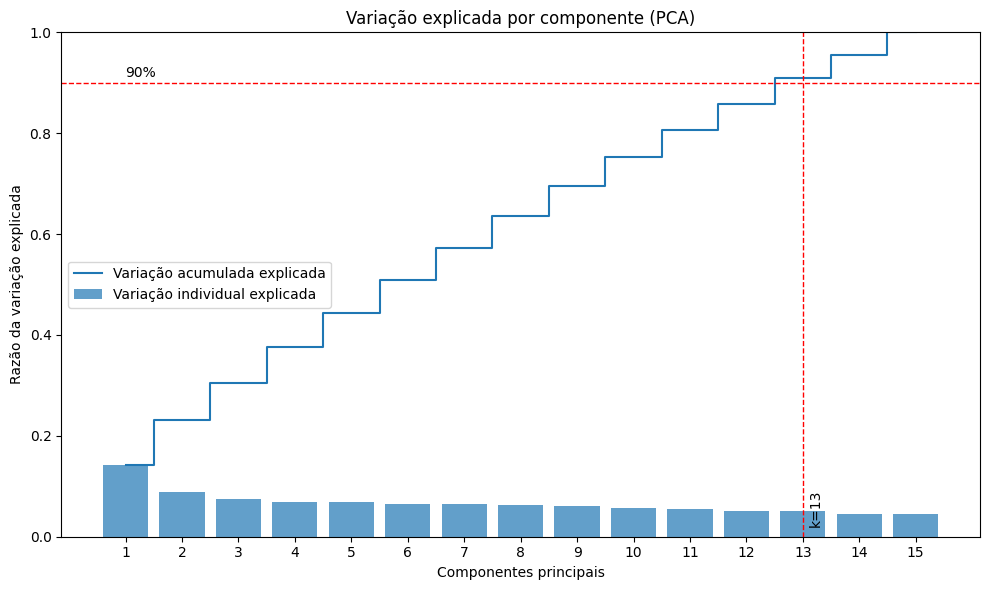

In [16]:
# Novo dataframe para esta etapa
explained_2312 = explained_2311
nComponents_2312 = n_max_2311
cumexp_2312 = np.cumsum(explained_2312)

# componente mínimo que atinge 90% (para referência visual)
k90 = int(np.argmax(cumexp_2312 >= 0.90) + 1) if np.any(cumexp_2312 >= 0.90) else None

plt.figure(figsize=(10, 6))

# Barras: variância explicada individual
plt.bar(
    range(1, nComponents_2312 + 1),
    explained_2312,
    alpha=0.7,
    align='center',
    label='Variação individual explicada'
)

# Linha em degraus: variância acumulada
plt.step(
    range(1, nComponents_2312 + 1),
    cumexp_2312,
    where='mid',
    label='Variação acumulada explicada'
)

# Linha horizontal vermelha tracejada em 90%
plt.axhline(y=0.90, linestyle='--', color='red', linewidth=1)
plt.text(
    x=1, y=0.905, s='90%',
    va='bottom', ha='left'
)

# Linha vertical tracejada no componente que atinge 90%
if k90 is not None:
    plt.axvline(x=k90, linestyle='--', color='red', linewidth=1)
    plt.text(
        x=k90 + 0.1, y=0.02, s=f'k={k90}',
        rotation=90, va='bottom', ha='left'
    )

plt.ylim(0, 1)
plt.ylabel('Razão da variação explicada')
plt.xlabel('Componentes principais')
plt.xticks(range(1, nComponents_2312 + 1))
plt.title('Variação explicada por componente (PCA)')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

#### **2.3.1.3 - Preparar pesos para a clusterização**

Nesta seção, alinhamos os pesos amostrais às mesmas linhas usadas no PCA.

In [17]:
# Novo dataframe para esta etapa
plano_amostral_processado_2313 = plano_amostral_processado_22.copy()

# Selecionar diretamente o Peso ML (média=1)
col_peso_ml = "Peso ML (média=1)"
if col_peso_ml not in plano_amostral_processado_2313.columns:
    raise KeyError(f"Coluna esperada não encontrada: {col_peso_ml}")

# Lê a coluna de peso da base completa
peso_ml_2313 = pd.to_numeric(
    plano_amostral_processado_2313[col_peso_ml],
    errors="coerce"
)

# Alinha pelos índices do PCA
peso_ml_2313 = peso_ml_2313.loc[plano_amostral_pca_2311.index]

# Checagens rápidas (sanidade) *depois* do alinhamento
if peso_ml_2313.isna().any():
    raise ValueError("Há NA na coluna de pesos após alinhamento com os PCs. Verifique o pré-processamento.")
if (peso_ml_2313 <= 0).any():
    raise ValueError("Há pesos <= 0 após alinhamento com os PCs. Verifique a coluna de peso.")

# Vetor de pesos para cluster/avaliação (nome sugestivo para uso adiante)
vetor_peso_ml_pca_2313 = peso_ml_2313.to_numpy(dtype=float)

# Resumo claro e n_eff
w = vetor_peso_ml_pca_2313
n_eff = (w.sum() ** 2) / (np.sum(w ** 2))

print("Resumo dos Pesos — 'Peso ML (média=1)' (após alinhamento com PCA)")
print(f"Observações (n)          : {w.size:,}")
print(f"Média                    : {w.mean():.3f}")
print(f"Desvio-padrão            : {w.std(ddof=0):.3f}")
print(f"Mínimo                   : {w.min():.3f}")
print(f"Máximo                   : {w.max():.3f}")
print(f"Tamanho amostral efetivo : {n_eff:,.0f}")

# Objetos prontos:
# - vetor_peso_ml_pca_2313 (np.ndarray) -> pesos alinhados às linhas dos PCs
# - peso_ml_2313 (pd.Series)           -> mesma coisa, mas com índice
# - plano_amostral_processado_2313     -> contém 'Peso ML (média=1)' para referência

Resumo dos Pesos — 'Peso ML (média=1)' (após alinhamento com PCA)
Observações (n)          : 78,999
Média                    : 1.000
Desvio-padrão            : 1.490
Mínimo                   : 0.006
Máximo                   : 62.602
Tamanho amostral efetivo : 24,522


### **2.3.2 - Análise de Correspondência Múltipla (MCA)**

Nesta seção, usamos MCA para reduzir a dimensionalidade do bloco de comorbidades binárias (0/1) tratado como categórico. A ideia é condensar padrões de coocorrência entre categorias em poucas dimensões (componentes/fatores) que capturam a maior parte da inércia (variância categórica), facilitando visualização e pré-processamento para clusterização. Seguimos boas práticas: copiamos as comorbidades, garantimos tipos categóricos, rodamos o MCA e relatamos a inércia explicada (individual e acumulada).

**Referências:**

[Oliveira et al., 2021 — BMC Public Health (ELSA-Brasil)](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-021-11760-2):
Exemplo aplicado de MCA em inquérito de saúde; mostra como as dimensões sintetizam perfis de saúde.

[Greenacre, 2010 — WIREs Comp. Stats (PDF)](https://www.jeffreycjohnson.org/app/download/769778722/WIREs%2BComputational%2BStats%2B-%2B2010%2B-%2BGreenacre%2B-%2BCorrespondence%2Banalysis.pdf?utm_source=chatgpt.com):
Fundamentos de CA/MCA e interpretação de biplots/inércia.


#### **2.3.2.1 - Aplicação do MCA**

*   **Dimensão:** ombinações das categorias originais (Dim1, Dim2, …).

*   **Inércia explicada:** fração da inércia total capturada por cada dimensão.

*   **Inércia acumulada:** soma da inércia explicada até a dimensão atual.

In [ ]:
# Cópias de seções anteriores
plano_amostral_processado_comorbidades_2321 = plano_amostral_processado_comorbidades_22.copy()

# Garante dtype categórico (MCA trata colunas como categorias)
for c in plano_amostral_processado_comorbidades_2321.columns:
    plano_amostral_processado_comorbidades_2321[c] = plano_amostral_processado_comorbidades_2321[c].astype("category")

# MCA exploratória — até 15 dimensões ou nº de colunas (o que for menor)
d_max_2321 = min(15, plano_amostral_processado_comorbidades_2321.shape[1])

import prince  # biblioteca 'prince' de CA/MCA
mca_2321 = prince.MCA(
    n_components=d_max_2321,
    n_iter=5,
    copy=True,
    check_input=True,
    engine="sklearn",     # 'sklearn' costuma ser o caminho mais compatível
    random_state=42,
)

# Ajuste e transformação
mca_2321 = mca_2321.fit(plano_amostral_processado_comorbidades_2321)
scores_2321 = mca_2321.transform(plano_amostral_processado_comorbidades_2321)  # mesmo índice da base

# Inércia explicada (frações). Algumas versões expõem 'explained_inertia_';
# em outras, precisamos calcular eigenvalues_/total_inertia_.
if hasattr(mca_2321, "explained_inertia_") and mca_2321.explained_inertia_ is not None:
    inercia_2321 = np.array(mca_2321.explained_inertia_)
else:
    eig = np.array(mca_2321.eigenvalues_)
    tot = float(mca_2321.total_inertia_)
    inercia_2321 = eig / tot if tot > 0 else np.zeros_like(eig)

inercia_acum_2321 = np.cumsum(inercia_2321)

# Tabela de inércia explicada
resultMCA = pd.DataFrame({
    "Dimensão": [f"Dim{i}" for i in range(1, len(inercia_2321) + 1)],
    "Inércia Explicada": inercia_2321,
    "Inércia Acumulada": inercia_acum_2321
})
print(resultMCA.to_string(index=False))

#-------------------------------------------------------------------------------
# MCA final (ex.: usar 13 dimensões)
nDims_2321 = min(13, scores_2321.shape[1])
plano_amostral_mca_2321 = scores_2321.iloc[:, :nDims_2321].copy()
plano_amostral_mca_2321.columns = [f"Dim{i}" for i in range(1, nDims_2321 + 1)]

print(
    f"\nScores MCA (d={nDims_2321}): "
    f"{plano_amostral_mca_2321.shape[0]:,} linhas × {plano_amostral_mca_2321.shape[1]:,} colunas"
)

KeyboardInterrupt: 

#### **2.3.2.2 - Análise Gráfica**

Nesta seção, mostramos a inércia explicada (individual e acumulada) pelas dimensões do MCA. Incluímos linha vermelha tracejada em 90% para auxiliar o ponto de corte.
Pelo padrão usual, d=10–13 tende a equilibrar simplicidade e sinal; d=13 costuma bater ≥90% em blocos com ~15 variáveis binárias (validaremos com seu resultado).

**Referências:**

[Oliveira et al., 2021 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-021-11760-2):
Exemplo de leitura de eixos/dimensões com MCA em inquérito nacional.

[Abdi & Valentin, 2007 — Tutorial](https://personal.utdallas.edu/~herve/Abdi-MCA2007-pretty.pdf):
Interpretação de inércia, contribuições e qualidade de representação.

In [ ]:
# Novo dataframe para esta etapa
inercia_2322 = inercia_2321
nDims_2322 = d_max_2321
inercia_acum_2322 = np.cumsum(inercia_2322)

# Dimensão mínima que atinge 90% (referência visual)
d90 = int(np.argmax(inercia_acum_2322 >= 0.90) + 1) if np.any(inercia_acum_2322 >= 0.90) else None

plt.figure(figsize=(10, 6))

# Barras: inércia explicada individual
plt.bar(
    range(1, nDims_2322 + 1),
    inercia_2322,
    alpha=0.7,
    align='center',
    label='Inércia individual explicada'
)

# Linha em degraus: inércia acumulada
plt.step(
    range(1, nDims_2322 + 1),
    inercia_acum_2322,
    where='mid',
    label='Inércia acumulada explicada'
)

# Linha horizontal vermelha tracejada em 90%
plt.axhline(y=0.90, linestyle='--', color='red', linewidth=1)
plt.text(x=1, y=0.905, s='90%', va='bottom', ha='left')

# Linha vertical tracejada na dimensão que atinge 90%
if d90 is not None:
    plt.axvline(x=d90, linestyle='--', color='red', linewidth=1)
    plt.text(x=d90 + 0.1, y=0.02, s=f'd={d90}', rotation=90, va='bottom', ha='left')

plt.ylim(0, 1)
plt.ylabel('Frações de inércia explicada')
plt.xlabel('Dimensões (MCA)')
plt.xticks(range(1, nDims_2322 + 1))
plt.title('Inércia explicada por dimensão (MCA)')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

#### **2.3.2.3 - Preparar pesos para a clusterização**

Nesta seção, alinhamos os pesos amostrais às mesmas linhas usadas no PCA.

In [ ]:
# Novos dataframes para esta etapa
plano_amostral_processado_2323 = plano_amostral_processado_22.copy()

# Selecionar diretamente o Peso ML (média=1)
col_peso_ml = "Peso ML (média=1)"
if col_peso_ml not in plano_amostral_processado_2323.columns:
    raise KeyError(f"Coluna esperada não encontrada: {col_peso_ml}")

peso_ml_2323 = pd.to_numeric(plano_amostral_processado_2323[col_peso_ml], errors="coerce")

# Checagens rápidas (sanidade)
if peso_ml_2323.isna().any():
    raise ValueError("Há NA na coluna de pesos. Verifique o pré-processamento.")
if (peso_ml_2323 <= 0).any():
    raise ValueError("Há pesos <= 0. Verifique a coluna de peso.")

# Vetor de pesos para cluster/avaliação (nome sugestivo para uso adiante)
vetor_peso_ml_mca_2323 = peso_ml_2323.to_numpy(dtype=float)

# Resumo claro e n_eff
w = vetor_peso_ml_mca_2323
n_eff = (w.sum() ** 2) / (np.sum(w ** 2))

print("Resumo dos Pesos — 'Peso ML (média=1)' (para MCA)")
print(f"Observações (n)          : {w.size:,}")
print(f"Média                    : {w.mean():.3f}")
print(f"Desvio-padrão            : {w.std(ddof=0):.3f}")
print(f"Mínimo                   : {w.min():.3f}")
print(f"Máximo                   : {w.max():.3f}")
print(f"Tamanho amostral efetivo : {n_eff:,.0f}")

# Objetos prontos:
# - vetor_peso_ml_mca_2323 (np.ndarray)  -> pesos alinhados às linhas das dimensões
# - plano_amostral_processado_2323       -> contém 'Peso ML (média=1)' para referência

### **2.3.2 - Análise de Correspondência Múltipla (MCA)**

Nesta seção, usamos MCA para reduzir a dimensionalidade do bloco de comorbidades binárias (0/1) tratado como categórico. A ideia é condensar padrões de coocorrência entre categorias em poucas dimensões (componentes/fatores) que capturam a maior parte da inércia (variância categórica), facilitando visualização e pré-processamento para clusterização. Seguimos boas práticas: copiamos as comorbidades, garantimos tipos categóricos, rodamos o MCA e relatamos a inércia explicada (individual e acumulada).

**Referências:**

[Oliveira et al., 2021 — BMC Public Health (ELSA-Brasil)](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-021-11760-2):
Exemplo aplicado de MCA em inquérito de saúde; mostra como as dimensões sintetizam perfis de saúde.

[Greenacre, 2010 — WIREs Comp. Stats (PDF)](https://www.jeffreycjohnson.org/app/download/769778722/WIREs%2BComputational%2BStats%2B-%2B2010%2B-%2BGreenacre%2B-%2BCorrespondence%2Banalysis.pdf?utm_source=chatgpt.com):
Fundamentos de CA/MCA e interpretação de biplots/inércia.


#### **2.3.2.1 - Aplicação do MCA**

*   **Dimensão:** ombinações das categorias originais (Dim1, Dim2, …).

*   **Inércia explicada:** fração da inércia total capturada por cada dimensão.

*   **Inércia acumulada:** soma da inércia explicada até a dimensão atual.

In [ ]:
# Cópias de seções anteriores
plano_amostral_processado_comorbidades_2321 = plano_amostral_processado_comorbidades_22.copy()

# Garante dtype categórico (MCA trata colunas como categorias)
for c in plano_amostral_processado_comorbidades_2321.columns:
    plano_amostral_processado_comorbidades_2321[c] = plano_amostral_processado_comorbidades_2321[c].astype("category")

# MCA exploratória — até 15 dimensões ou nº de colunas (o que for menor)
d_max_2321 = min(15, plano_amostral_processado_comorbidades_2321.shape[1])

import prince  # biblioteca 'prince' de CA/MCA
mca_2321 = prince.MCA(
    n_components=d_max_2321,
    n_iter=5,
    copy=True,
    check_input=True,
    engine="sklearn",     # 'sklearn' costuma ser o caminho mais compatível
    random_state=42,
)

# Ajuste e transformação
mca_2321 = mca_2321.fit(plano_amostral_processado_comorbidades_2321)
scores_2321 = mca_2321.transform(plano_amostral_processado_comorbidades_2321)  # mesmo índice da base

# Inércia explicada (frações). Algumas versões expõem 'explained_inertia_';
# em outras, precisamos calcular eigenvalues_/total_inertia_.
if hasattr(mca_2321, "explained_inertia_") and mca_2321.explained_inertia_ is not None:
    inercia_2321 = np.array(mca_2321.explained_inertia_)
else:
    eig = np.array(mca_2321.eigenvalues_)
    tot = float(mca_2321.total_inertia_)
    inercia_2321 = eig / tot if tot > 0 else np.zeros_like(eig)

inercia_acum_2321 = np.cumsum(inercia_2321)

# Tabela de inércia explicada
resultMCA = pd.DataFrame({
    "Dimensão": [f"Dim{i}" for i in range(1, len(inercia_2321) + 1)],
    "Inércia Explicada": inercia_2321,
    "Inércia Acumulada": inercia_acum_2321
})
print(resultMCA.to_string(index=False))

#-------------------------------------------------------------------------------
# MCA final (ex.: usar 13 dimensões)
nDims_2321 = min(13, scores_2321.shape[1])
plano_amostral_mca_2321 = scores_2321.iloc[:, :nDims_2321].copy()
plano_amostral_mca_2321.columns = [f"Dim{i}" for i in range(1, nDims_2321 + 1)]

print(
    f"\nScores MCA (d={nDims_2321}): "
    f"{plano_amostral_mca_2321.shape[0]:,} linhas × {plano_amostral_mca_2321.shape[1]:,} colunas"
)

KeyboardInterrupt: 

#### **2.3.2.2 - Análise Gráfica**

Nesta seção, mostramos a inércia explicada (individual e acumulada) pelas dimensões do MCA. Incluímos linha vermelha tracejada em 90% para auxiliar o ponto de corte.
Pelo padrão usual, d=10–13 tende a equilibrar simplicidade e sinal; d=13 costuma bater ≥90% em blocos com ~15 variáveis binárias (validaremos com seu resultado).

**Referências:**

[Oliveira et al., 2021 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-021-11760-2):
Exemplo de leitura de eixos/dimensões com MCA em inquérito nacional.

[Abdi & Valentin, 2007 — Tutorial](https://personal.utdallas.edu/~herve/Abdi-MCA2007-pretty.pdf):
Interpretação de inércia, contribuições e qualidade de representação.

In [ ]:
# Novo dataframe para esta etapa
inercia_2322 = inercia_2321
nDims_2322 = d_max_2321
inercia_acum_2322 = np.cumsum(inercia_2322)

# Dimensão mínima que atinge 90% (referência visual)
d90 = int(np.argmax(inercia_acum_2322 >= 0.90) + 1) if np.any(inercia_acum_2322 >= 0.90) else None

plt.figure(figsize=(10, 6))

# Barras: inércia explicada individual
plt.bar(
    range(1, nDims_2322 + 1),
    inercia_2322,
    alpha=0.7,
    align='center',
    label='Inércia individual explicada'
)

# Linha em degraus: inércia acumulada
plt.step(
    range(1, nDims_2322 + 1),
    inercia_acum_2322,
    where='mid',
    label='Inércia acumulada explicada'
)

# Linha horizontal vermelha tracejada em 90%
plt.axhline(y=0.90, linestyle='--', color='red', linewidth=1)
plt.text(x=1, y=0.905, s='90%', va='bottom', ha='left')

# Linha vertical tracejada na dimensão que atinge 90%
if d90 is not None:
    plt.axvline(x=d90, linestyle='--', color='red', linewidth=1)
    plt.text(x=d90 + 0.1, y=0.02, s=f'd={d90}', rotation=90, va='bottom', ha='left')

plt.ylim(0, 1)
plt.ylabel('Frações de inércia explicada')
plt.xlabel('Dimensões (MCA)')
plt.xticks(range(1, nDims_2322 + 1))
plt.title('Inércia explicada por dimensão (MCA)')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

#### **2.3.2.3 - Preparar pesos para a clusterização**

Nesta seção, alinhamos os pesos amostrais às mesmas linhas usadas no PCA.

In [ ]:
# Novos dataframes para esta etapa
plano_amostral_processado_2323 = plano_amostral_processado_22.copy()

# Selecionar diretamente o Peso ML (média=1)
col_peso_ml = "Peso ML (média=1)"
if col_peso_ml not in plano_amostral_processado_2323.columns:
    raise KeyError(f"Coluna esperada não encontrada: {col_peso_ml}")

peso_ml_2323 = pd.to_numeric(plano_amostral_processado_2323[col_peso_ml], errors="coerce")

# Checagens rápidas (sanidade)
if peso_ml_2323.isna().any():
    raise ValueError("Há NA na coluna de pesos. Verifique o pré-processamento.")
if (peso_ml_2323 <= 0).any():
    raise ValueError("Há pesos <= 0. Verifique a coluna de peso.")

# Vetor de pesos para cluster/avaliação (nome sugestivo para uso adiante)
vetor_peso_ml_mca_2323 = peso_ml_2323.to_numpy(dtype=float)

# Resumo claro e n_eff
w = vetor_peso_ml_mca_2323
n_eff = (w.sum() ** 2) / (np.sum(w ** 2))

print("Resumo dos Pesos — 'Peso ML (média=1)' (para MCA)")
print(f"Observações (n)          : {w.size:,}")
print(f"Média                    : {w.mean():.3f}")
print(f"Desvio-padrão            : {w.std(ddof=0):.3f}")
print(f"Mínimo                   : {w.min():.3f}")
print(f"Máximo                   : {w.max():.3f}")
print(f"Tamanho amostral efetivo : {n_eff:,.0f}")

# Objetos prontos:
# - vetor_peso_ml_mca_2323 (np.ndarray)  -> pesos alinhados às linhas das dimensões
# - plano_amostral_processado_2323       -> contém 'Peso ML (média=1)' para referência

## **2.4 - Método do Cotovelo (Elbow Method)**

Nesta seção, estimamos um intervalo plausível para k (número de clusters) pelo método do cotovelo. A ideia é rodar K-means para vários valores de k e observar a curva da inércia/WCSS (soma dos quadrados intra-cluster): quando o ganho marginal passa a diminuir fortemente (o “cotovelo”), temos um ponto de equilíbrio entre compacidade e parcimônia. Usaremos as features reduzidas (ex.: PCA/MCA) e, quando disponível, pesos amostrais na etapa de ajuste.

**Referências:**

[Zhou et al., 2023 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-023-17177-3):
Exemplo aplicado que compara cotovelo e silhueta para definir k em perfis de estilo de vida, reportando soluções distintas por sexo.

[scikit-learn — Documentação do KMeans](https://scikit-learn.org/stable/modules/clustering.html):
Define inércia/WCSS e discute comportamento do K-means; base para implementação do cotovelo.

### **2.4.1 - Aplicação do Elbow Method (Mediana sobre seeds + EV(k))**

Nesta seção, reforçamos o método do cotovelo para tornar o joelho mais visível e estável. Em vez de uma única execução por k, rodamos várias inicializações e diferentes seeds, tomamos a mediana da WCSS, criamos bandas p10–p90, e normalizamos a curva em termos de EV(k) = 1 − WCSS/TSS (variância explicada pelo agrupamento). Isso reduz ruído e suavizações artificiais.

**Referências:**

[scikit-learn — KMeans (docs)](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html):
Define inércia/WCSS, recomenda múltiplas inicializações e discute o impacto de n_init.

[Tibshirani et al., 2001 — Gap Statistic](https://hastie.su.domains/Papers/gap.pdf):
Alternativa estatística para escolha de k, útil quando o cotovelo é difuso.

In [21]:
# Novo dataframe para esta etapa
# plano_amostral_241 = plano_amostral_pca_2311.copy()
# vetor_peso_ml_241 = vetor_peso_ml_pca_2313.copy()

plano_amostral_241 = plano_amostral_processado_comorbidades_22.copy()
plano_amostral_totaL_241 = plano_amostral_processado_22.copy()
vetor_peso_ml_241 = (
    pd.to_numeric(
        plano_amostral_totaL_241
        .loc[plano_amostral_241.index, "Peso ML (média=1)"],
        errors="coerce"
    )
    .to_numpy(dtype=float)
)

# Entrada
X = plano_amostral_241.values

# Pesos (opcional)
usar_peso = 'vetor_peso_ml_241' in globals()
w = vetor_peso_ml_241 if usar_peso else None

# Faixa de k e seeds
ks = list(range(2, 16))
seeds = [42, 7, 13, 21, 101, 202, 303, 404, 505, 606]  # 10 seeds

wcss_mediana, wcss_p10, wcss_p90 = [], [], []
for k in ks:
    inerts = []
    for sd in seeds:
        km = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=sd)
        km.fit(X, sample_weight=w)  # se w=None, roda sem ponderação
        inerts.append(km.inertia_)
    inerts = np.array(inerts, dtype=float)
    wcss_mediana.append(np.median(inerts))
    wcss_p10.append(np.percentile(inerts, 10))
    wcss_p90.append(np.percentile(inerts, 90))

result_elbow_rob_241 = pd.DataFrame({
    "k": ks,
    "WCSS_med": wcss_mediana,
    "WCSS_p10": wcss_p10,
    "WCSS_p90": wcss_p90,
    "Ajuste ponderado": "sim" if usar_peso else "não"
})

# TSS (Total Sum of Squares) — compatível com ponderação
if usar_peso:
    w_norm = w / w.mean()  # estabilidade numérica
    xbar = np.average(X, axis=0, weights=w_norm)
    TSS = np.sum(w_norm[:, None] * (X - xbar)**2)
else:
    xbar = X.mean(axis=0)
    TSS = np.sum((X - xbar)**2)

# Variância explicada pelo cluster: EV(k) = 1 - WCSS/TSS   (↑ melhor)
result_elbow_rob_241["EV"] = np.clip(1.0 - (result_elbow_rob_241["WCSS_med"] / TSS), 0.0, 1.0)

print(result_elbow_rob_241.to_string(index=False))

 k     WCSS_med     WCSS_p10     WCSS_p90 Ajuste ponderado       EV
 2 77225.760446 77225.759581 77225.760586              sim 0.189860
 3 68111.813294 68111.813294 68111.813349              sim 0.285470
 4 61354.112848 61351.663849 61494.965998              sim 0.356362
 5 56532.838628 56420.822865 56899.051116              sim 0.406940
 6 52551.379620 52505.960845 52848.715249              sim 0.448707
 7 50053.049653 49520.344063 50177.667813              sim 0.474916
 8 47170.833932 47099.207899 47744.974294              sim 0.505152
 9 45240.921639 45028.377999 45628.781689              sim 0.525398
10 43572.218099 43286.482856 43850.855625              sim 0.542904
11 42161.717865 41839.904984 42409.080544              sim 0.557701
12 40739.946351 40574.149081 40996.822095              sim 0.572616
13 39592.619415 39488.398618 39769.766405              sim 0.584652
14 38527.736896 38328.131781 38751.973685              sim 0.595823
15 37549.731583 37324.831819 37973.311537       

### **2.4.2 - Detecção automática do joelho (“Kneedle” simples)**

Aqui destacamos o “ombro” usando uma versão simples do algoritmo Kneedle (máxima distância ao segmento que liga os extremos). Que devolve um k* candidato, depois confirmaremos com métricas internas.

**Referências:**

[Satopää et al., 2011 — Kneedle](https://raghavan.usc.edu/papers/kneedle-simplex11.pdf):
Detector automático de “joelho/cotovelo” em curvas suaves.

In [22]:
# Novo dataframe para esta etapa
result_elbow_rob_242 = result_elbow_rob_241.copy()

# Curva base para “joelho”: EV(k) é mais legível que WCSS
x = result_elbow_rob_242["k"].to_numpy(dtype=float)
y = result_elbow_rob_242["EV"].to_numpy(dtype=float)  # 0..1 (↑ melhor)

# Δ e Δ² (para inspeção)
# delta  = np.r_[np.nan, np.diff(y)]
# delta2 = np.r_[np.nan, np.nan, np.diff(y, n=2)]
# k_delta2 = int(x[np.nanargmax(delta2)])

# Kneedle: distância ao segmento entre (k_min, EV_min) e (k_max, EV_max)
x1, y1 = x[0], y[0]
x2, y2 = x[-1], y[-1]
num = np.abs((y2 - y1)*x - (x2 - x1)*y + x2*y1 - y2*x1)
den = np.sqrt((y2 - y1)**2 + (x2 - x1)**2)
dist = num / den
k_kneedle = int(x[np.argmax(dist)])

n_clusters_242 = 2 # k_kneedle
# print(f"Candidato por Δ²      : k = {k_delta2}")
print(f"Candidato por Kneedle : k = {k_kneedle}")
print(f"k* adotado            : k = {n_clusters_242}")

Candidato por Kneedle : k = 6
k* adotado            : k = 2


### **2.4.3 - Gráficos (banda p10–p90 e EV(k) com k'*')**

Largura máxima da faixa p10–p90: 657.32 (unidades de WCSS)


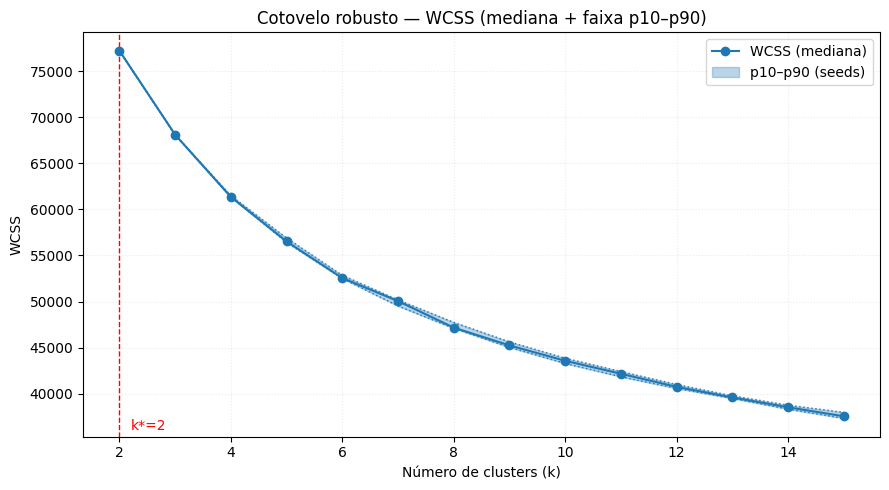

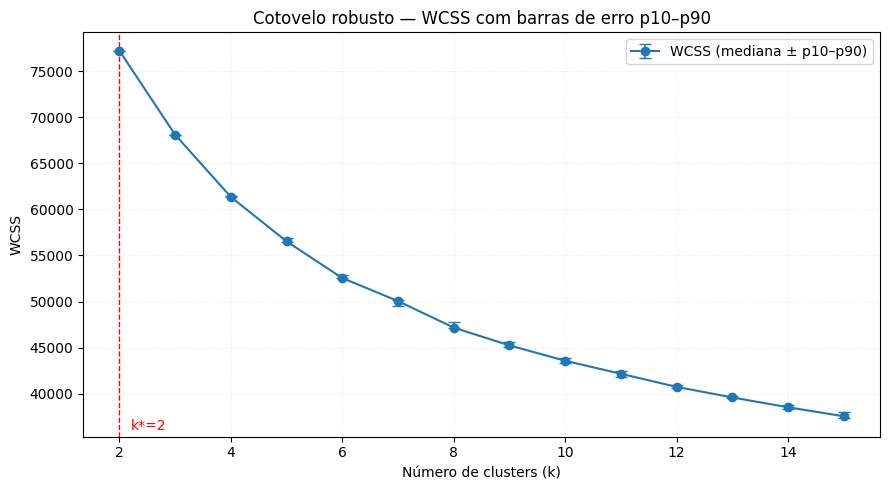

In [23]:
# Cópias de seções anteriores
result_elbow_rob_243 = result_elbow_rob_241.copy()
n_clusters_243 = int(n_clusters_242)

x   = result_elbow_rob_243["k"].to_numpy()
y   = result_elbow_rob_243["WCSS_med"].to_numpy()
ylo = result_elbow_rob_243["WCSS_p10"].to_numpy()
yhi = result_elbow_rob_243["WCSS_p90"].to_numpy()

# Diagnóstico: quão estreita é a faixa?
spread = yhi - ylo
print(f"Largura máxima da faixa p10–p90: {spread.max():.2f} (unidades de WCSS)")

# Gráfico com faixa p10–p90 bem visível
fig, ax = plt.subplots(figsize=(9,5))

(line_med,) = ax.plot(x, y, marker='o', label='WCSS (mediana)', zorder=3)
cor = line_med.get_color()

# Sombreado com MESMA cor da linha e alpha maior
ax.fill_between(x, ylo, yhi, color=cor, alpha=0.30, label='p10–p90 (seeds)', zorder=1)

# Bordas pontilhadas da faixa (reforça a leitura quando a banda é fina)
ax.plot(x, ylo, linestyle=':', linewidth=1.1, color=cor, alpha=0.9, zorder=2)
ax.plot(x, yhi, linestyle=':', linewidth=1.1, color=cor, alpha=0.9, zorder=2)

# Marca do k*
ax.axvline(n_clusters_243, ls='--', color='red', linewidth=1)
ax.text(n_clusters_243 + 0.2, ax.get_ylim()[0]*1.02, f'k*={n_clusters_243}', color='red')

ax.set_title('Cotovelo robusto — WCSS (mediana + faixa p10–p90)')
ax.set_xlabel('Número de clusters (k)'); ax.set_ylabel('WCSS')
ax.grid(alpha=.25, linestyle=':'); ax.legend()
plt.tight_layout(); plt.show()

# Barras de erro (± p10–p90) — aparece mesmo com banda muito estreita
yerr_lower = y - ylo
yerr_upper = yhi - y
yerr = np.vstack([yerr_lower, yerr_upper])

plt.figure(figsize=(9,5))
plt.errorbar(x, y, yerr=yerr, fmt='o-', capsize=4, elinewidth=1.2, label='WCSS (mediana ± p10–p90)')
plt.axvline(n_clusters_243, ls='--', color='red', linewidth=1)
plt.text(n_clusters_243 + 0.2, plt.ylim()[0]*1.02, f'k*={n_clusters_243}', color='red')
plt.title('Cotovelo robusto — WCSS com barras de erro p10–p90')
plt.xlabel('Número de clusters (k)'); plt.ylabel('WCSS')
plt.grid(alpha=.25, linestyle=':'); plt.legend()
plt.tight_layout(); plt.show()

## **2.5 - Algoritmos de Agrupamento (clustering)**

### **2.5.1 - Algoritmo K-Means**

Nesta seção aplicamos o K-Means sobre as features reduzidas (PCA/MCA) para construir os clusters finais. Usamos o valor de k escolhido na etapa do cotovelo (ex.: k = 9), inicialização k-means++ e muitas reinicializações para maior estabilidade. Se houver peso amostral (“Peso ML (média=1)”), ele é usado no fit. Ao final, salvamos: rótulos por linha, tamanhos (brutos e ponderados), e os centroides no espaço dos componentes — tudo pronto para perfilamento e análises posteriores.

**Referências:**

[Zhou et al., 2023 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-023-17177-3):
Usa k-means para perfis de estilo de vida; discute escolha de k (cotovelo/silhueta).

[He et al., 2023 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-023-17096-3):
Clustering não supervisionado de indicadores de saúde; aplica k-means como método principal.

#### **2.5.1.1 - Treinar K-Means e gerar rótulos**

In [24]:
# Cópias de seções anteriores
# plano_amostral_2511 = plano_amostral_pca_2311.copy()
# vetor_peso_ml_2511 = vetor_peso_ml_pca_2313.copy()
n_clusters_2511 = int(n_clusters_242)

plano_amostral_2511 = plano_amostral_processado_comorbidades_22.copy()
plano_amostral_totaL_2511 = plano_amostral_processado_22.copy()
vetor_peso_ml_2511 = (
    pd.to_numeric(
        plano_amostral_totaL_2511
        .loc[plano_amostral_2511.index, "Peso ML (média=1)"],
        errors="coerce"
    )
    .to_numpy(dtype=float)
)

# Treino do K-Means
modelo_kmeans_2511 = KMeans(
    n_clusters=n_clusters_2511,
    init="k-means++",
    n_init=100,
    random_state=42
)
modelo_kmeans_2511.fit(
    plano_amostral_2511.values,
    sample_weight= vetor_peso_ml_2511  # None é aceito
)

# Rótulos (1..k) como Série com nome fixo "clusters"
rotulos_base0 = pd.Series(
    modelo_kmeans_2511.labels_,
    index=plano_amostral_2511.index
)
labels_clusters_kmeans_2511 = rotulos_base0 + 1
labels_clusters_kmeans_2511.name = "clusters"

# Tamanho dos clusters (uso só para resumo, independe do nome da coluna)
contagem_n = labels_clusters_kmeans_2511.value_counts().sort_index()

# Tamanho ponderado (opcional)
usar_peso = vetor_peso_ml_2511 is not None
if usar_peso:
    df_peso = pd.DataFrame({
        "cluster": labels_clusters_kmeans_2511,
        "peso": vetor_peso_ml_2511
    })
    contagem_peso = df_peso.groupby("cluster")["peso"].sum().sort_index()
    total_peso = contagem_peso.sum()
else:
    contagem_peso = None

# Centroides no espaço reduzido
centroides_kmeans_2511 = pd.DataFrame(
    modelo_kmeans_2511.cluster_centers_,
    index=[f"Cluster {i}" for i in range(1, n_clusters_2511 + 1)],
    columns=plano_amostral_2511.columns
)

# Resumo
resumo_dict = {
    "Total de pessoas (n)": contagem_n,
    "Participação (%)": (contagem_n / contagem_n.sum() * 100).round(2),
}
if contagem_peso is not None:
    resumo_dict["Peso amostral (soma)"] = contagem_peso.round(2)
    resumo_dict["Peso amostral (%)"] = (contagem_peso / total_peso * 100).round(2)

resumo_clusters_kmeans_2511 = (
    pd.DataFrame(resumo_dict)
    .sort_index()
    .rename_axis("Cluster")
)

# Dataframe final “clusterizado” no espaço reduzido (PCA)
plano_amostral_cluster_2511 = plano_amostral_2511.copy()
plano_amostral_cluster_2511["clusters"] = labels_clusters_kmeans_2511  # nome fixo

if usar_peso:
    # adiciona peso para facilitar agregações e tabelas ponderadas depois
    plano_amostral_cluster_2511["Peso ML (média=1)"] = vetor_peso_ml_2511

# Saída
print(f"K-Means treinado | k={n_clusters_2511} | inércia={modelo_kmeans_2511.inertia_:,.0f}")

print("\nTamanho dos clusters:")
print(resumo_clusters_kmeans_2511.to_string())

print("\nCentroides no espaço (médias por dimensão):")
print(centroides_kmeans_2511.round(3).to_string())

K-Means treinado | k=2 | inércia=77,226

Tamanho dos clusters:
         Total de pessoas (n)  Participação (%)  Peso amostral (soma)  Peso amostral (%)
Cluster                                                                                 
1                       23109             29.25              21782.76              27.57
2                       55890             70.75              57216.24              72.43

Centroides no espaço (médias por dimensão):
           Hipertensão  Diabetes  Colesterol Alto  Cardiopatia  AVC ou Derrame   Asma  Artrite ou Reumatismo   DORT  Depressão  Outra Doença Mental  Doença Crônica no Pulmão  Câncer  Insuficiência Renal Crônica  Dor na Coluna  Obesidade
Cluster 1        0.992     0.213            0.318        0.138           0.053  0.058                  0.170  0.035      0.159                0.081                     0.026   0.048                        0.033          0.335      0.339
Cluster 2       -0.000     0.041            0.100        0.027

#### **2.5.1.2 - Anexar rótulos de cluster às bases**

In [25]:
# Cópias de seções anteriores
labels_clusters_kmeans_2512 = labels_clusters_kmeans_2511.copy()  # Série 1..k
labels_clusters_kmeans_2512.name = "clusters"  # garante nome fixo

# Caminhos de entrada e saída
ARQ_NUM  = Path("plano_amostral_numerica_1332.parquet")
ARQ_NOM  = Path("plano_amostral_nominal_1332.parquet")
ARQ_NORM = Path("plano_amostral_processado_agrupamento_147.parquet")

OUT_NUM      = Path("plano_amostral_numerica_clustered_kmeans_2512.parquet")
OUT_NOM      = Path("plano_amostral_nominal_clustered_kmeans_2512.parquet")
OUT_NUM_NORM = Path("plano_amostral_normalizado_clustered_kmeans_2512.parquet")

# Carregar bases numérica, nominal e normalizada
plano_amostral_2512_numerica = pd.read_parquet(ARQ_NUM,  engine="pyarrow")
plano_amostral_2512_nominal  = pd.read_parquet(ARQ_NOM,  engine="pyarrow")
plano_amostral_2512_norm     = pd.read_parquet(ARQ_NORM, engine="pyarrow")

# Selecionar as mesmas linhas usadas no cluster
idx_2512 = labels_clusters_kmeans_2512.index

plano_amostral_numerica_clustered_kmeans_2512 = plano_amostral_2512_numerica.loc[idx_2512].copy()
plano_amostral_nominal_clustered_kmeans_2512  = plano_amostral_2512_nominal.loc[idx_2512].copy()
plano_amostral_normalizado_clustered_kmeans_2512 = plano_amostral_2512_norm.loc[idx_2512].copy()

# Nome fixo da coluna de cluster
clusters_col = "clusters"

# Anexar rótulos de cluster
plano_amostral_numerica_clustered_kmeans_2512[clusters_col]    = labels_clusters_kmeans_2512
plano_amostral_nominal_clustered_kmeans_2512[clusters_col]     = labels_clusters_kmeans_2512
plano_amostral_normalizado_clustered_kmeans_2512[clusters_col] = labels_clusters_kmeans_2512

# Apagar arquivos de saída se já existirem
for caminho_saida in [OUT_NUM, OUT_NOM, OUT_NUM_NORM]:
    if caminho_saida.exists():
        caminho_saida.unlink()

# Salvar arquivos prontos para análise
plano_amostral_numerica_clustered_kmeans_2512.to_parquet(
    OUT_NUM, engine="pyarrow", compression="snappy"
)
plano_amostral_nominal_clustered_kmeans_2512.to_parquet(
    OUT_NOM, engine="pyarrow", compression="snappy"
)
plano_amostral_normalizado_clustered_kmeans_2512.to_parquet(
    OUT_NUM_NORM, engine="pyarrow", compression="snappy"
)

# Relatório rápido
print("Bases K-Means com rótulos anexados e salvas:")
print(f"• Numérica:     {plano_amostral_numerica_clustered_kmeans_2512.shape[0]} × "
      f"{plano_amostral_numerica_clustered_kmeans_2512.shape[1]} → {OUT_NUM.name}")
print(f"• Nominal:      {plano_amostral_nominal_clustered_kmeans_2512.shape[0]} × "
      f"{plano_amostral_nominal_clustered_kmeans_2512.shape[1]} → {OUT_NOM.name}")
print(f"• Normalizada:  {plano_amostral_normalizado_clustered_kmeans_2512.shape[0]} × "
      f"{plano_amostral_normalizado_clustered_kmeans_2512.shape[1]} → {OUT_NUM_NORM.name}")

Bases K-Means com rótulos anexados e salvas:
• Numérica:     78999 × 89 → plano_amostral_numerica_clustered_kmeans_2512.parquet
• Nominal:      78999 × 89 → plano_amostral_nominal_clustered_kmeans_2512.parquet
• Normalizada:  78999 × 90 → plano_amostral_normalizado_clustered_kmeans_2512.parquet


### **2.5.2 - Análise de Classes/Perfis Latentes (LCA/LPA)**

Nesta seção estimamos classes latentes para agrupar perfis de saúde sem supervisão. Quando as variáveis são binárias/categóricas, usamos LCA (Bernoulli); quando são contínuas (como scores do MCA), usamos LPA (Gaussiana). O número de classes 𝑘 é selecionado por BIC em uma grade (k=2..15). Entregamos rótulos 1..k, tamanhos (brutos e ponderados) e os parâmetros por classe (probabilidades nas binárias; médias por dimensão nos contínuos).

**Referências:**

[Craig et al., 2021 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-021-11225-6):
Usa LCA para padrões de multimorbidade e determinantes sociais em inquérito nacional na Jamaica.

[Knowles et al., 2024 — BMC Public Health](https://bmcpublichealth.biomedcentral.com/articles/10.1186/s12889-024-20004-y):
LCA de comportamentos de saúde em adolescentes, com associação a desfechos de bem-estar mental.

#### **2.5.2.1 – Treinar LCA/LPA e gerar rótulos**

In [ ]:
# Cópias de seções anteriores
plano_amostral_reduzido_2521 = plano_amostral_pca_2311.copy()
vetor_peso_ml_2521 = vetor_peso_ml_pca_2313.copy()

# Silenciar avisos de depreciação do sklearn e avisos genéricos
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ["TQDM_DISABLE"] = "1"

X_2521 = plano_amostral_reduzido_2521.values
w_2521 = vetor_peso_ml_2521
ks_2521 = range(2, 15)

def fit_stepmix_k(k, X, sample_weight):
    model = StepMix(
        n_components=k,
        measurement="gaussian",  # LPA sobre scores contínuos (PCA/MCA)
        n_steps=2,
        n_init=10,
        max_iter=200,
        random_state=42,
    )
    model.fit(X, sample_weight=sample_weight)
    return model

bic_list, models_by_k = [], {}
for k in ks_2521:
    m = fit_stepmix_k(k, X_2521, w_2521)
    models_by_k[k] = m
    bic_list.append(m.bic(X_2521))

result_bic_2521 = (
    pd.DataFrame({"k": list(ks_2521), "BIC": bic_list})
    .set_index("k")
    .sort_index()
)
k_bic_2521 = int(result_bic_2521["BIC"].idxmin())
print("Seleção por BIC (menor = melhor):")
print(result_bic_2521.to_string())
print(f"\nClasse escolhida por BIC: k = {k_bic_2521}")

modelo_lca_2521 = models_by_k[k_bic_2521]

# Rótulos 1..k com nome fixo "clusters"
labels_base0 = pd.Series(
    modelo_lca_2521.predict(X_2521),
    index=plano_amostral_reduzido_2521.index,
    dtype=int
)
labels_clusters_lca_2521 = labels_base0 + 1
labels_clusters_lca_2521.name = "clusters"

# Contagens (bruta e ponderada)
contagem_bruta_2521 = labels_clusters_lca_2521.value_counts().sort_index()
if w_2521 is not None:
    df_peso = pd.DataFrame({"cluster": labels_clusters_lca_2521, "peso": w_2521})
    contagem_pond_2521 = df_peso.groupby("cluster")["peso"].sum().sort_index()
    total_peso_2521 = contagem_pond_2521.sum()
else:
    contagem_pond_2521 = None

# Parâmetros (médias por dimensão)
params = modelo_lca_2521.get_parameters()  # API StepMix
means_2521 = pd.DataFrame(
    params["measurement"]["means"],
    index=[f"Classe {i}" for i in range(1, k_bic_2521 + 1)],
    columns=plano_amostral_reduzido_2521.columns
)

# Resumo
resumo_cols = {
    "Total de pessoas": contagem_bruta_2521,
    "Participação (%)": (contagem_bruta_2521 / contagem_bruta_2521.sum() * 100).round(2),
}
if contagem_pond_2521 is not None:
    resumo_cols["Peso amostral (soma)"] = contagem_pond_2521.round(2)
    resumo_cols["Peso amostral (%)"] = (contagem_pond_2521 / total_peso_2521 * 100).round(2)

resumo_lca_2521 = (
    pd.DataFrame(resumo_cols)
    .sort_index()
    .rename_axis("Classe")
)

print(f"\nLPA (Gaussiana) treinada | k={k_bic_2521}")
print("\nResumo por classe:")
print(resumo_lca_2521.to_string())

print("\nMédias por dimensão (perfil dos scores por classe):")
print(means_2521.round(3).to_string())

Fitting StepMix...


Initializations (n_init) :  10%|█         | 1/10 [00:11<01:47, 11.99s/it, max_LL=-9.48e+5, max_avg_LL=-12]


KeyboardInterrupt: 

#### **2.5.2.2 – Anexar rótulos da LCA às bases e salvar**

In [ ]:
# Cópias de seções anteriores
labels_clusters_lca_2522 = labels_clusters_lca_2521.copy()
labels_clusters_lca_2522.name = "clusters"  # garante

# Caminhos de entrada/saída
ARQ_NUM  = Path("plano_amostral_numerica_1332.parquet")
ARQ_NOM  = Path("plano_amostral_nominal_1332.parquet")
ARQ_NORM = Path("plano_amostral_processado_agrupamento_147.parquet")

OUT_NUM      = Path("plano_amostral_numerica_clustered_lca_2522.parquet")
OUT_NOM      = Path("plano_amostral_nominal_clustered_lca_2522.parquet")
OUT_NUM_NORM = Path("plano_amostral_normalizado_clustered_lca_2522.parquet")

# Carregar bases
base_num_2522  = pd.read_parquet(ARQ_NUM,  engine="pyarrow")
base_nom_2522  = pd.read_parquet(ARQ_NOM,  engine="pyarrow")
base_norm_2522 = pd.read_parquet(ARQ_NORM, engine="pyarrow")

# Subconjunto alinhado ao índice dos rótulos
idx_2522 = labels_clusters_lca_2522.index

plano_amostral_numerica_clustered_lca_2522 = base_num_2522.loc[idx_2522].copy()
plano_amostral_nominal_clustered_lca_2522  = base_nom_2522.loc[idx_2522].copy()
plano_amostral_normalizado_clustered_lca_2522 = base_norm_2522.loc[idx_2522].copy()

# Nome fixo da coluna
clusters_col = "clusters"

# Anexar coluna de cluster
plano_amostral_numerica_clustered_lca_2522[clusters_col]    = labels_clusters_lca_2522
plano_amostral_nominal_clustered_lca_2522[clusters_col]     = labels_clusters_lca_2522
plano_amostral_normalizado_clustered_lca_2522[clusters_col] = labels_clusters_lca_2522

# Salvar versões prontas
plano_amostral_numerica_clustered_lca_2522.to_parquet(OUT_NUM,      engine="pyarrow", compression="snappy")
plano_amostral_nominal_clustered_lca_2522.to_parquet(OUT_NOM,       engine="pyarrow", compression="snappy")
plano_amostral_normalizado_clustered_lca_2522.to_parquet(OUT_NUM_NORM, engine="pyarrow", compression="snappy")

print("Bases LCA com rótulos anexados e salvas:")
print(f"• Numérica:     {plano_amostral_numerica_clustered_lca_2522.shape[0]} × {plano_amostral_numerica_clustered_lca_2522.shape[1]} → {OUT_NUM.name}")
print(f"• Nominal:      {plano_amostral_nominal_clustered_lca_2522.shape[0]} × {plano_amostral_nominal_clustered_lca_2522.shape[1]} → {OUT_NOM.name}")
print(f"• Normalizada:  {plano_amostral_normalizado_clustered_lca_2522.shape[0]} × {plano_amostral_normalizado_clustered_lca_2522.shape[1]} → {OUT_NUM_NORM.name}")

## **2.6 - Verificação da distribuição dos clusters (Silhouette Analysis)**

A Silhouette mede, para cada ponto, o quão “em casa” ele está no seu cluster comparado aos vizinhos dos outros clusters. Vai de −1 a +1: perto de +1 é ótimo, perto de 0 é “na divisa”, negativo sugere má alocação. Aqui calculamos (i) a média global (silhouette score), (ii) o valor por amostra, e (iii) um gráfico clássico por cluster. Também mostramos a inércia (WCSS) do K-Means como noção de dispersão interna. Esses diagnósticos ajudam a confirmar se o k escolhido faz sentido e onde estão os clusters mais “misturados”.

### **2.6.1 – Carregamento dos clusters pré-calculados**

Antes de avaliar a qualidade dos agrupamentos, precisamos garantir que os rótulos de cluster estejam carregados de forma organizada e reaproveitável ao longo do notebook. Nesta subseção, realizamos o carregamento do plano amostral já clusterizado (seja pela abordagem de **K-Means** ou pela **LCA**) a partir dos arquivos em formato Parquet, e extraímos apenas a série de rótulos de cluster.

A ideia é padronizar essa etapa em uma célula só: definimos qual versão de clusterização queremos usar, lemos o arquivo correspondente e salvamos os rótulos em um objeto genérico (`labels_clusters_260`). A partir dele, as seções seguintes podem simplesmente criar cópias com nomes específicos (por exemplo, `labels_clusters_261`) sem precisar reler arquivos ou repetir lógica de carregamento.


In [26]:
# -----------------------------
# Escolha da versão de cluster (dinâmica)
# -----------------------------
# Agora este valor deve ser exatamente o SUFIXO do nome do arquivo,
# sem o prefixo "plano_amostral_numerica_clustered_" e sem ".parquet".
#
# Ex:
#   arquivo: plano_amostral_numerica_clustered_kmeans_2512.parquet
#   -> cluster_versao_261 = "kmeans_2512"
#
#   arquivo: plano_amostral_numerica_clustered_lca_2522.parquet
#   -> cluster_versao_261 = "lca_2522"
#
cluster_versao_261 = "kmeans_2512"  # basta mudar isso aqui

# Monta o caminho do arquivo de forma genérica
caminho_parquet_261 = f"plano_amostral_numerica_clustered_{cluster_versao_261}.parquet"

# -----------------------------
# Carrega o plano amostral já clusterizado
# -----------------------------
plano_amostral_clusterizado_261 = pd.read_parquet(caminho_parquet_261)

# Coluna padrão de rótulos
clusters_col_261 = "clusters"

if clusters_col_261 not in plano_amostral_clusterizado_261.columns:
    raise KeyError(
        f"A coluna '{clusters_col_261}' não foi encontrada em {caminho_parquet_261}. "
        f"Verifique se o arquivo salvo para a versão '{cluster_versao_261}' possui essa coluna."
    )

# Extrai apenas a série de rótulos de cluster
labels_clusters_261 = plano_amostral_clusterizado_261[clusters_col_261].copy()

# -----------------------------
# Seção de comorbidades (261)
# -----------------------------

# variáveis de interesse (comorbidades)
colunas_comorb_261 = [
    "Hipertensão","Diabetes","Colesterol Alto","Cardiopatia","AVC ou Derrame",
    "Asma","Artrite ou Reumatismo","DORT","Depressão","Outra Doença Mental",
    "Doença Crônica no Pulmão","Câncer","Insuficiência Renal Crônica",
    "Dor na Coluna","Obesidade"
]

# checagem: quais colunas existem / não existem na base clusterizada 261
colunas_existentes_261 = [
    c for c in colunas_comorb_261
    if c in plano_amostral_clusterizado_261.columns
]
colunas_ausentes_261 = [
    c for c in colunas_comorb_261
    if c not in plano_amostral_clusterizado_261.columns
]

if colunas_ausentes_261:
    print("Atenção: as colunas abaixo não foram encontradas em", caminho_parquet_261, "e serão ignoradas:")
    for c in colunas_ausentes_261:
        print("   -", c)

# novo dataframe para esta etapa: somente comorbidades (cópia imutável)
plano_amostral_comorbidades_261 = plano_amostral_clusterizado_261[colunas_existentes_261].copy()

# (opcional) se quiser já ter um df combinando comorbidades + cluster:
plano_amostral_comorb_clusters_261 = plano_amostral_comorbidades_261.copy()
plano_amostral_comorb_clusters_261["cluster_261"] = labels_clusters_261.values

# -----------------------------
# Checagens rápidas
# -----------------------------
print("Versão de clusterização carregada:", cluster_versao_261)
print("Arquivo:", caminho_parquet_261)
print("Coluna de rótulos:", clusters_col_261)

print("\nExemplo de rótulos (head):")
print(labels_clusters_261.head())

print("\nDistribuição de observações por cluster:")
print(labels_clusters_261.value_counts().sort_index())

print("\nShape do dataframe de comorbidades 261:", plano_amostral_comorbidades_261.shape)
print("Exemplo de comorbidades (head):")
print(plano_amostral_comorbidades_261.head())

Versão de clusterização carregada: kmeans_2512
Arquivo: plano_amostral_numerica_clustered_kmeans_2512.parquet
Coluna de rótulos: clusters

Exemplo de rótulos (head):
0     1
9     2
10    2
18    2
19    2
Name: clusters, dtype: int32

Distribuição de observações por cluster:
clusters
1    23109
2    55890
Name: count, dtype: int64

Shape do dataframe de comorbidades 261: (78999, 15)
Exemplo de comorbidades (head):
    Hipertensão  Diabetes  Colesterol Alto  Cardiopatia  AVC ou Derrame  Asma  \
0           1.0       2.0              1.0          2.0             2.0   2.0   
9           2.0       2.0              2.0          2.0             2.0   2.0   
10          2.0       2.0              2.0          2.0             2.0   2.0   
18          2.0       2.0              2.0          2.0             2.0   2.0   
19          2.0       2.0              2.0          2.0             2.0   2.0   

    Artrite ou Reumatismo  DORT  Depressão  Outra Doença Mental  \
0                     1.0  

### **2.6.2 - Silhouette Score (média global)**

In [27]:
# Cópias de seções anteriores
labels_clusters_262 = labels_clusters_261.copy()  # Série 1..k
# plano_amostral_262 = plano_amostral_pca_2311.copy()
plano_amostral_262 = plano_amostral_comorbidades_261.copy()

# Garante que os dados de entrada (X) estão na MESMA ordem dos rótulos
plano_amostral_262 = plano_amostral_262.loc[labels_clusters_262.index].copy()

# (opcional, mas bom pra sanidade)
assert len(plano_amostral_262) == len(labels_clusters_262), \
    "Tamanhos de X e labels não batem para o Silhouette."

# Silhouette médio global (quanto maior, melhor)
silhouetteScore_262 = float(
    silhouette_score(
        plano_amostral_262.values,
        labels_clusters_262.values
    )
)
print(f"Silhouette médio: {silhouetteScore_262:.4f}")

Silhouette médio: 0.3423


### **2.6.3 - Silhouette Por Amostra**

In [28]:
# Cópias de seções anteriores
labels_clusters_263 = labels_clusters_261.copy()  # Série 1..k
# plano_amostral_263 = plano_amostral_pca_2311.copy()
plano_amostral_263 = plano_amostral_comorbidades_261.copy()

# Alinha o PCA às MESMAS linhas usadas na clusterização
plano_amostral_263 = plano_amostral_263.loc[labels_clusters_263.index].copy()

# Checagem de segurança
if len(plano_amostral_263) != len(labels_clusters_263):
    raise ValueError(
        f"Incompatibilidade entre X e labels: "
        f"{len(plano_amostral_263)} linhas em X vs "
        f"{len(labels_clusters_263)} rótulos."
    )

# Um valor de Silhouette por linha (quem está bem/mal no cluster)
silhouetteSamples_263 = silhouette_samples(
    plano_amostral_263.values,
    labels_clusters_263.values
)

# Tabela resumida para explorar depois
resultSilhouetteSamples_263 = pd.DataFrame(
    {
        "Silhouette Value": silhouetteSamples_263,
        "Cluster Label":    labels_clusters_263.values,
    },
    index=labels_clusters_263.index   # deixa claro que o índice é o das labels
)

resultSilhouetteSamples_263

,Silhouette Value,Cluster Label
0,0.109971,1
9,0.616326,2
10,0.361237,2
18,0.616326,2
19,0.616326,2
...,...,...
293697,0.616326,2
293702,0.245333,2
293709,0.242215,2
293713,0.361237,2


### **2.6.5 - Dispersão interna (WCSS) e Erro Médio Por Ponto**

O WCSS é uma medida da variabilidade dos pontos dentro de cada cluster, quanto menor o WCSS, mais densamente agrupados estão os pontos dentro de seus respectivos clusters. O erro médio por ponto dá uma ideia de quanto, em média, cada ponto difere do centro do cluster ao qual foi atribuído.

A soma dos quadrados intra-cluster (WCSS) do modelo k-means é aproximadamente 54.718,16 e o erro médio por ponto é 0.6240.

In [29]:
# Cópias de seções anteriores
labels_clusters_265 = labels_clusters_261.copy() # 1..k
# plano_amostral_265 = plano_amostral_pca_2311.copy()
plano_amostral_265 = plano_amostral_comorbidades_261.copy()

# Calcula WCSS de forma genérica (serve para K-Means, LCA, etc.)
wcss_265 = 0.0
unique_labels_265 = np.sort(labels_clusters_265.unique())

for lbl in unique_labels_265:
    mask_lbl = (labels_clusters_265.values == lbl)
    pts_lbl = plano_amostral_265[mask_lbl, :]  # pontos daquele cluster

    if pts_lbl.shape[0] == 0:
        continue  # só por segurança, se algum cluster vier vazio

    center_lbl = pts_lbl.mean(axis=0)
    # soma dos quadrados das distâncias para o centróide
    wcss_265 += ((pts_lbl - center_lbl) ** 2).sum()

# Erro médio por ponto (dispersão média)
erro_medio_265 = wcss_265 / plano_amostral_265.shape[0]

print(f"WCSS (soma dos quadrados intra-cluster): {wcss_265:,.2f}")
print(f"Erro médio por ponto: {erro_medio_265:.4f}")

InvalidIndexError: (array([ True, False, False, ..., False, False, False]), slice(None, None, None))

### **2.6.4 - Gráfico de Silhouette + dispersão em PC1×PC2**

O gráfico de silhueta ajuda a avaliar a qualidade dos clusters formados, fornecendo uma visão rápida de como cada ponto se encaixa dentro de seu cluster. Essas visualizações são cruciais para a otimização do modelo de clustering, pois indicam se o número de clusters escolhido é apropriado e se a distribuição dos clusters faz sentido com base na variabilidade dos dados.

In [ ]:
# ============================================================
# 1. CONFIGURAÇÃO
# ============================================================

# Texto opcional para aparecer no título (pra lembrar que base foi usada)
#     Ex.: " – PCA (8 componentes)", " – MCA", " – comorbidades originais"
sufixo_titulo_264 = ""

# Base numérica onde o algoritmo de agrupamento FOI TREINADO
#    Pode ser:
#      - matriz de componentes (PCA, MCA, FAMD, etc.)
#      - matriz original (ex.: comorbidades 0/1)

# matriz_base_agrupamento_264 = plano_amostral_pca_2311
# matriz_base_agrupamento_264 = plano_amostral_mca_2321
matriz_base_agrupamento_264 = plano_amostral_comorbidades_261

# Como gerar o espaço 2D do gráfico da direita?
#    - True  -> usa diretamente as DUAS PRIMEIRAS colunas da matriz_base_agrupamento_264
#    - False -> projeta a matriz completa em 2D via PCA só para visualização
usar_primeiras_dimensoes_264 = False

# ============================================================
# 2. CÓPIAS
# ============================================================

# Número de grupos (se quiser pode inferir dos próprios rótulos)
numero_clusters_264 = int(n_clusters_242)

# Série com rótulos de cluster (inteiros), alinhada linha a linha com a base acima
rotulos_clusters_base_264 = labels_clusters_261  # pode vir de K-Means, LCA, etc.

# Garante que estamos com uma matriz NumPy alinhada ao índice dos rótulos
if isinstance(matriz_base_agrupamento_264, pd.DataFrame):
    matriz_completa_agrupamento_264 = (
        matriz_base_agrupamento_264
        .loc[rotulos_clusters_base_264.index]  # garante alinhamento linha a linha
        .copy()
        .values
    )
else:
    # Se já for NumPy, assumimos que a ordem das linhas já está alinhada
    matriz_completa_agrupamento_264 = np.asarray(matriz_base_agrupamento_264)

rotulos_clusters_264 = rotulos_clusters_base_264.copy()


# ============================================================
# 3. FUNÇÃO GENÉRICA DE SILHOUETTE + SCATTER 2D
# ============================================================

def plot_silhouette_e_clusterizacao_2d(
    matriz_agrupamento,
    rotulos_clusters,
    numero_clusters=None,
    usar_primeiras_dimensoes=True,
    sufixo_titulo="",
    random_state=42,
):
    """
    Plota:
      - painel esquerdo: gráfico de Silhouette por cluster
      - painel direito: dispersão 2D (qualquer representação numérica em 2 dimensões)

    Parâmetros
    ----------
    matriz_agrupamento : array-like (n_amostras × n_features)
        Mesma matriz numérica usada pelo algoritmo de agrupamento
        (PCA, MCA, base original, etc.).
    rotulos_clusters : array-like (n_amostras,)
        Rótulos inteiros de cluster para cada linha da matriz_agrupamento.
    numero_clusters : int, opcional
        Número de clusters. Se None, é inferido a partir dos próprios rótulos.
    usar_primeiras_dimensoes : bool
        Se True, usa as duas primeiras colunas de matriz_agrupamento no scatter.
        Se False, aplica PCA(2) em matriz_agrupamento apenas para visualização.
    sufixo_titulo : str
        Texto extra para aparecer no título (ex.: indicar tipo de base/representação).
    random_state : int
        Semente usada no PCA de visualização (se usar_primeiras_dimensoes=False).

    Retorna
    -------
    valor_silhouette_medio : float
    valores_silhouette_amostra : np.ndarray (n_amostras,)
    """
    matriz_agrupamento = np.asarray(matriz_agrupamento)
    vetor_rotulos = np.asarray(rotulos_clusters)

    # Se numero_clusters não foi passado, infere pelos rótulos distintos
    if numero_clusters is None:
        rotulos_unicos = np.unique(vetor_rotulos)
        numero_clusters = len(rotulos_unicos)
    else:
        rotulos_unicos = np.sort(np.unique(vetor_rotulos))

    # ------------------------------------------------
    # Cálculo do Silhouette no MESMO espaço do agrupamento
    # ------------------------------------------------
    valores_silhouette_amostra = silhouette_samples(matriz_agrupamento, vetor_rotulos)
    valor_silhouette_medio = float(silhouette_score(matriz_agrupamento, vetor_rotulos))

    # ------------------------------------------------
    # Espaço 2D para o scatter da direita
    # ------------------------------------------------
    if usar_primeiras_dimensoes and matriz_agrupamento.shape[1] >= 2:
        matriz_2d_visualizacao = matriz_agrupamento[:, :2]
        titulo_scatter = "Dados agrupados (dimensões 1 e 2)"
        xlabel_scatter = "Dimensão 1"
        ylabel_scatter = "Dimensão 2"
    else:
        projetor_pca_visualizacao = PCA(n_components=2, random_state=random_state)
        matriz_2d_visualizacao = projetor_pca_visualizacao.fit_transform(matriz_agrupamento)
        titulo_scatter = "Dados agrupados (projeção 2D para visualização)"
        xlabel_scatter = "Componente 1 (visualização)"
        ylabel_scatter = "Componente 2 (visualização)"

    # ------------------------------------------------
    # Figura lado a lado
    # ------------------------------------------------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

    # =========================
    # Painel 1: Silhouette
    # =========================
    ax1.set_xlim([-0.1, 1.0])
    ax1.set_ylim([0, len(matriz_agrupamento) + (numero_clusters + 1) * 10])

    # Mapeia rótulos quaisquer (ex.: {1,2,4,7}) para índices 0..k-1
    rotulos_unicos_ordenados = np.sort(rotulos_unicos)
    mapa_rotulo_idx = {lbl: idx for idx, lbl in enumerate(rotulos_unicos_ordenados)}

    y_inferior = 10
    for rotulo in rotulos_unicos_ordenados:
        mascara_cluster = (vetor_rotulos == rotulo)
        valores_cluster = np.sort(valores_silhouette_amostra[mascara_cluster])
        tamanho_cluster = valores_cluster.shape[0]
        y_superior = y_inferior + tamanho_cluster

        indice_cor = mapa_rotulo_idx[rotulo] / numero_clusters
        cor_cluster = cm.nipy_spectral(indice_cor)

        ax1.fill_betweenx(
            np.arange(y_inferior, y_superior),
            0, valores_cluster,
            facecolor=cor_cluster, edgecolor=cor_cluster, alpha=0.7
        )
        ax1.text(-0.05, y_inferior + 0.5 * tamanho_cluster, str(rotulo))
        y_inferior = y_superior + 10  # espaço entre blocos

    ax1.set_title("Silhouette por cluster")
    ax1.set_xlabel("Coeficiente de Silhouette")
    ax1.set_ylabel("Cluster")
    ax1.axvline(x=valor_silhouette_medio, color="red", linestyle="--")
    ax1.set_yticks([])

    # =========================
    # Painel 2: Scatter 2D
    # =========================
    cores_pontos = cm.nipy_spectral(
        np.vectorize(mapa_rotulo_idx.get)(vetor_rotulos).astype(float) / numero_clusters
    )

    ax2.scatter(
        matriz_2d_visualizacao[:, 0],
        matriz_2d_visualizacao[:, 1],
        marker='.', s=30, lw=0, alpha=0.7,
        c=cores_pontos, edgecolor='k'
    )

    # Centroide de cada cluster nesse espaço 2D
    centros_clusters = []
    for rotulo in rotulos_unicos_ordenados:
        mascara_cluster = (vetor_rotulos == rotulo)
        pontos_cluster = matriz_2d_visualizacao[mascara_cluster, :]
        centro_cluster = pontos_cluster.mean(axis=0)
        centros_clusters.append(centro_cluster)

    centros_clusters = np.vstack(centros_clusters)

    ax2.scatter(
        centros_clusters[:, 0],
        centros_clusters[:, 1],
        marker='o', c="white", alpha=1, s=200, edgecolor='k'
    )
    for rotulo, centro in zip(rotulos_unicos_ordenados, centros_clusters):
        ax2.scatter(centro[0], centro[1], marker=f'${rotulo}$', alpha=1, s=50, edgecolor='k')

    ax2.set_title(titulo_scatter)
    ax2.set_xlabel(xlabel_scatter)
    ax2.set_ylabel(ylabel_scatter)

    plt.suptitle(
        f"Silhouette | k={numero_clusters} | d={matriz_agrupamento.shape[1]}{sufixo_titulo}",
        fontsize=14, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

    return valor_silhouette_medio, valores_silhouette_amostra


# ============================================================
# 4. CHAMADA DA FUNÇÃO
# ============================================================

silhouetteScore_264, silhouetteSamples_264 = plot_silhouette_e_clusterizacao_2d(
    matriz_agrupamento=matriz_completa_agrupamento_264,
    rotulos_clusters=rotulos_clusters_264,
    numero_clusters=numero_clusters_264,
    usar_primeiras_dimensoes=usar_primeiras_dimensoes_264,
    sufixo_titulo=sufixo_titulo_264,
)

## **2.7 – Análise dos clusters (perfil de saúde e uso de serviços)**

Após definir os clusters e avaliar sua qualidade por meio do *Silhouette Analysis*, o próximo passo é **interpretar o que cada grupo representa** em termos de condições de saúde, percepção subjetiva e uso de serviços. Nesta subseção, realizamos uma análise descritiva dos clusters a partir da base já clusterizada, calculando a média dos atributos dentro de cada grupo e construindo diferentes visualizações:

- **Mapa de calor** das médias dos atributos por cluster, para enxergar rapidamente quais condições são mais prevalentes em cada grupo.
- **Diagrama de radar**, que mostra o “formato” de cada cluster em relação a um conjunto de variáveis selecionadas.
- **Gráficos de barras interativos**, permitindo explorar, atributo por atributo, a média (ou porcentagem) em cada cluster.
- **Gráficos de bolhas**, evidenciando a interseção entre uso de serviços de saúde e autoavaliação do estado de saúde dentro de cada cluster.

Para isso, utilizamos a base clusterizada (por **K-Means** ou **LCA**), normalizada na escala 0–1, o que torna comparáveis tanto as variáveis originalmente contínuas quanto as variáveis binárias (0/1). A média de uma variável binária em cada cluster pode ser interpretada diretamente como **proporção de indivíduos** com aquela característica.

### **2.7.1 – Preparação da base normalizada e médias por cluster**

In [ ]:
# Reaproveita a escolha feita na seção 2.6.1
# cluster_versao_261 já deve estar definido como "kmeans" ou "lca"
cluster_versao_271 = cluster_versao_261  # se preferir, pode definir direto aqui

# Mapeia os arquivos normalizado e nominal clusterizados
if cluster_versao_271 == "kmeans":
    caminho_norm_271 = Path("plano_amostral_normalizado_clustered_kmeans_2512.parquet")
    caminho_nom_271  = Path("plano_amostral_nominal_clustered_kmeans_2512.parquet")
elif cluster_versao_271 == "lca":
    caminho_norm_271 = Path("plano_amostral_normalizado_clustered_lca_2522.parquet")
    caminho_nom_271  = Path("plano_amostral_nominal_clustered_lca_2522.parquet")
else:
    raise ValueError("Valor inválido para 'cluster_versao_271'. Use 'kmeans' ou 'lca'.")

print("Versão de clusterização para análise 2.7:", cluster_versao_271)
print("Arquivo normalizado clusterizado carregado:", caminho_norm_271)
print("Arquivo nominal   clusterizado carregado:", caminho_nom_271)

# Carrega a base normalizada já clusterizada
plano_amostral_normalizado_clustered_271 = pd.read_parquet(caminho_norm_271, engine="pyarrow")

# Carrega a base nominal clusterizada (para rótulos/legendas futuras)
plano_amostral_nominal_clustered_271 = pd.read_parquet(caminho_nom_271, engine="pyarrow")

# Calcula a média de cada atributo numérico por cluster
# (assumindo que a coluna de rótulos se chama "clusters")
plano_amostral_medias_clustered_271 = (
    plano_amostral_normalizado_clustered_271
    .groupby("clusters")
    .mean(numeric_only=True)
)

print("\nClusters encontrados:", plano_amostral_medias_clustered_271.index.tolist())
print("Formato de plano_amostral_medias_clustered_271:", plano_amostral_medias_clustered_271.shape)

# Visualização rápida das médias (transposto)
plano_amostral_medias_clustered_271.transpose().head()

Versão de clusterização para análise 2.7: kmeans
Arquivo normalizado clusterizado carregado: plano_amostral_normalizado_clustered_kmeans_2512.parquet
Arquivo nominal   clusterizado carregado: plano_amostral_nominal_clustered_kmeans_2512.parquet

Clusters encontrados: [1, 2, 3, 4, 5, 6, 7, 8, 9]
Formato de plano_amostral_medias_clustered_271: (9, 89)


clusters,1,2,3,4,5,6,7,8,9
UF,0.466236,0.511449,0.438874,0.522457,0.435499,0.449837,0.531334,0.507865,0.491917
Estrato,0.471368,0.516076,0.443933,0.527015,0.440685,0.454695,0.536006,0.512831,0.497443
Ordem do Domicílio,0.372477,0.368392,0.374097,0.364575,0.376345,0.373816,0.356710,0.368860,0.388344
Zona,0.201125,0.156670,0.229758,0.125326,0.219715,0.189364,0.167965,0.159462,0.221291
Cadastro UBS,0.210267,0.258014,0.249351,0.270235,0.206948,0.237293,0.236797,0.246123,0.217519


### **2.7.2 – Mapa de Calor dos atributos por cluster**

O mapa de calor permite visualizar, em uma única figura, as **médias normalizadas** dos atributos em cada cluster. Cada linha representa um atributo (por exemplo, comorbidades, percepção de saúde, sexo, área de residência, categorias de IMC), e cada coluna representa um cluster.

Cores mais próximas do amarelo/vermelho indicam valores médios mais elevados naquele atributo para o cluster correspondente, enquanto cores mais escuras indicam valores mais baixos. Isso ajuda a identificar rapidamente padrões, como “cluster mais multimórbido”, “cluster com pior autoavaliação de saúde” ou “cluster mais urbano”.


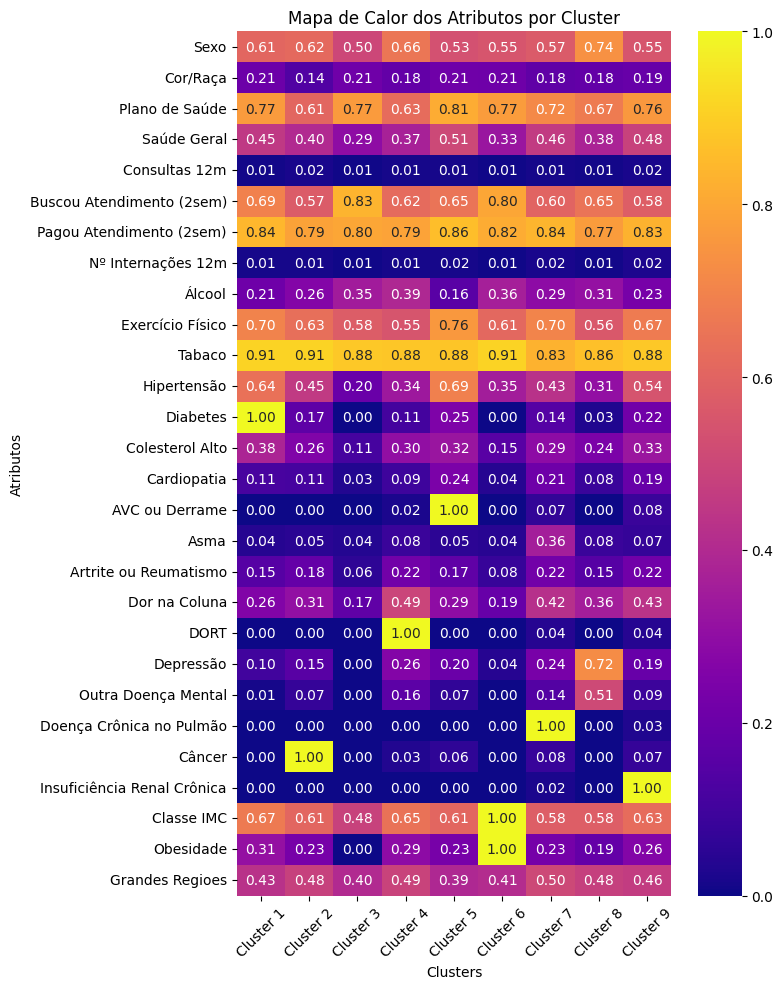

In [ ]:
# Copiando variáveis necessárias
plano_amostral_medias_clustered_272 = plano_amostral_medias_clustered_271.copy()

# Selecionando colunas para o mapa de calor
nomes = {

}
atributos_272 = [
    "Sexo",
    "Cor/Raça",
    "Plano de Saúde",
    "Saúde Geral",
    "Consultas 12m",
    "Buscou Atendimento (2sem)",
    "Pagou Atendimento (2sem)",
    "Nº Internações 12m",
    "Álcool",
    "Exercício Físico",
    "Tabaco",
    "Hipertensão",
    "Diabetes",
    "Colesterol Alto",
    "Cardiopatia",
    "AVC ou Derrame",
    "Asma",
    "Artrite ou Reumatismo",
    "Dor na Coluna",
    "DORT",
    "Depressão",
    "Outra Doença Mental",
    "Doença Crônica no Pulmão",
    "Câncer",
    "Insuficiência Renal Crônica",
    "Classe IMC",
    "Obesidade",
    "Grandes Regioes"
]

# Filtra apenas os atributos desejados
dfHeatMap_272 = plano_amostral_medias_clustered_272[atributos_272].transpose()

plt.figure(figsize=(8, 10))

ax = sns.heatmap(
    dfHeatMap_272,
    annot=True,
    cmap='plasma',
    fmt=".2f",
    linewidths=0,
    linecolor='white'
)

plt.title('Mapa de Calor dos Atributos por Cluster')
plt.xlabel('Clusters')
plt.ylabel('Atributos')

# Usa os próprios rótulos de cluster como rótulos do eixo X
ax.set_xticklabels([f'Cluster {c}' for c in plano_amostral_medias_clustered_272.index])

plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### **2.7.3 – Diagrama de Radar dos perfis de cluster**

O diagrama de radar apresenta, em um gráfico polar, o “desenho” de cada cluster em relação a um conjunto de atributos selecionados. Cada eixo radial representa uma variável, e a área preenchida de cada cluster mostra seu perfil médio.

Como os atributos estão na escala 0–1, valores mais altos indicam maior prevalência (no caso de variáveis binárias) ou maior intensidade (no caso de indicadores contínuos normalizados). Essa visualização ajuda a comparar, por exemplo, um cluster com alta carga de comorbidades e baixa percepção de saúde com outro com perfil oposto.

In [ ]:
def gerar_diagrama_radar_273(df, atributos, titulo="Perfis médios por cluster"):
    """
    Gera um diagrama de radar com um traço por cluster.
    df: dataframe com índice = cluster, colunas = atributos.
    """
    fig = go.Figure()

    # Paleta básica de cores (cicla se tiver mais clusters)
    base_colors = ['lightcoral', 'skyblue', 'gold', 'limegreen', 'orchid', 'deepskyblue']

    cluster_ids = list(df.index)

    for pos, cluster_id in enumerate(cluster_ids):
        color = base_colors[pos % len(base_colors)]
        valores = df.loc[cluster_id, atributos].values

        fig.add_trace(go.Scatterpolar(
            r=valores,
            theta=atributos,
            fill='toself',
            name=f'Cluster {cluster_id}',
            hoverinfo='all',
            line=dict(color=color)
        ))

    fig.update_layout(
        title=titulo,
        polar=dict(
            radialaxis=dict(
                visible=True,
                range=[0, 1]
            )
        ),
        showlegend=True,
        width=1000,
        height=800
    )

    fig.show()

# Copiando variáveis necessárias
plano_amostral_medias_clustered_273 = plano_amostral_medias_clustered_271.copy()

atributos_273 = [
    "Sexo",
    "Cor/Raça",
    "Plano de Saúde",
    "Saúde Geral",
    "Consultas 12m",
    "Buscou Atendimento (2sem)",
    "Pagou Atendimento (2sem)",
    "Nº Internações 12m",
    "Álcool",
    "Exercício Físico",
    "Tabaco",
    "Hipertensão",
    "Diabetes",
    "Colesterol Alto",
    "Cardiopatia",
    "AVC ou Derrame",
    "Asma",
    "Artrite ou Reumatismo",
    "Dor na Coluna",
    "DORT",
    "Depressão",
    "Outra Doença Mental",
    "Doença Crônica no Pulmão",
    "Câncer",
    "Insuficiência Renal Crônica",
    "Classe IMC",
    "Obesidade",
    "Grandes Regioes"
]

gerar_diagrama_radar_273(plano_amostral_medias_clustered_273, atributos_273)

### **2.7.4 – Gráficos de barras interativos (atributo × cluster)**

Nesta subseção, construímos um gráfico de barras interativo em que o usuário escolhe um atributo (por exemplo, “Hipertensão”, “Depressão” ou “Internação”) e o gráfico mostra, para cada cluster, a média daquele atributo, apresentada em **porcentagem**.

Como as variáveis são 0–1, a média multiplicada por 100 pode ser interpretada como “percentual de indivíduos do cluster com aquela característica”. Isso facilita muito a leitura de padrões, como “cluster 2 tem maior porcentagem de internações recentes”, “cluster 4 concentra a maior proporção de obesos”, etc.

In [ ]:
def gerar_grafico_barras_interativo_274(df, lista_de_atributos):
    """
    df: plano_amostral_medias_clustered_271 (índice = cluster, colunas = atributos)
    lista_de_atributos: lista de colunas a explorar
    """
    import plotly.graph_objects as go

    # Mapeia cores para cada cluster com base na posição
    base_colors = ['lightcoral', 'skyblue', 'gold', 'limegreen', 'orchid', 'deepskyblue']
    cluster_ids = list(df.index)
    cluster_color_map = {
        cid: base_colors[i % len(base_colors)] for i, cid in enumerate(cluster_ids)
    }

    # Um trace por atributo (vamos alternar visibilidade via botões)
    traces = []
    for idx, atributo in enumerate(lista_de_atributos):
        data_frame = df[[atributo]].copy()
        data_frame["Porcentagem"] = data_frame[atributo] * 100

        cores_das_barras = [cluster_color_map[cid] for cid in data_frame.index]

        trace = go.Bar(
            x=[str(cid) for cid in data_frame.index],
            y=data_frame["Porcentagem"],
            name=atributo,
            visible=True if idx == 0 else False,
            text=[f"{val:.0f}%" for val in data_frame["Porcentagem"]],
            textposition="outside",
            marker_color=cores_das_barras
        )
        traces.append(trace)

    fig = go.Figure(data=traces)

    botoes = []
    for idx, atributo in enumerate(lista_de_atributos):
        visibilidade = [i == idx for i in range(len(lista_de_atributos))]
        botoes.append({
            "label": atributo,
            "method": "update",
            "args": [
                {"visible": visibilidade},
                {
                    "title": f"Média de {atributo} por cluster",
                    "yaxis": {"title": "Média (%)"}
                }
            ]
        })

    fig.update_layout(
        updatemenus=[{
            "x": 0.5,
            "xanchor": "center",
            "y": 1.05,
            "yanchor": "top",
            "buttons": botoes,
            "showactive": True
        }],
        title=f"Porcentagem de {lista_de_atributos[0]} por cluster",
        xaxis_title="Cluster",
        xaxis={"type": "category"},
        yaxis={"title": "Porcentagem (%)"},
        height=950,
        showlegend=False
    )

    fig.show()

# Copiando variáveis necessárias
plano_amostral_medias_clustered_274 = plano_amostral_medias_clustered_271.copy()

atributos_274 = [
    "Sexo",
    "Cor/Raça",
    "Plano de Saúde",
    "Saúde Geral",
    "Consultas 12m",
    "Buscou Atendimento (2sem)",
    "Pagou Atendimento (2sem)",
    "Nº Internações 12m",
    "Álcool",
    "Exercício Físico",
    "Tabaco",
    "Hipertensão",
    "Diabetes",
    "Colesterol Alto",
    "Cardiopatia",
    "AVC ou Derrame",
    "Asma",
    "Artrite ou Reumatismo",
    "Dor na Coluna",
    "DORT",
    "Depressão",
    "Outra Doença Mental",
    "Doença Crônica no Pulmão",
    "Câncer",
    "Insuficiência Renal Crônica",
    "Classe IMC",
    "Obesidade",
    "Grandes Regioes"
]

gerar_grafico_barras_interativo_274(plano_amostral_medias_clustered_274, atributos_274)

### **2.7.5 – Gráfico de bolhas (uso de serviços × autoavaliação da saúde, por cluster)**

O gráfico de bolhas representa, para cada cluster, a quantidade (ou porcentagem) de indivíduos em diferentes combinações entre:

- uma variável de uso de serviços (por exemplo, “Serviço de Saúde”), e  
- categorias de autoavaliação de saúde (por exemplo, “Saúde Muito Bom”, “Saúde Regular”, “Saúde Muito Ruim”).

Cada linha do eixo Y representa um par “Variável de serviço – Sim/Não”, o eixo X representa as categorias de saúde, e o tamanho das bolhas reflete a magnitude daquela combinação. Isso ajuda a entender, por exemplo, se há um cluster que concentra indivíduos com pior percepção de saúde, mas que ainda assim **não** utilizam serviços de saúde com frequência.

In [ ]:
def plot_bubble_chart_interactive_275(df, y_attrs, x_attrs, cluster_col="Cluster"):
    """
    df: dataframe linha-a-linha com colunas binárias (0/1) e uma coluna de cluster.
    y_attrs: lista com variáveis "de serviço" (ex.: ['Serviço de Saúde'])
    x_attrs: lista com categorias de autoavaliação (ex.: ['Saúde Muito Bom', ...])
    """
    unique_clusters = sorted(df[cluster_col].unique())
    base_colors = ['lightcoral', 'skyblue', 'gold', 'limegreen', 'orchid', 'deepskyblue']

    fig = go.Figure()

    # Espaçamento vertical
    y_spacing = 1.0
    bubble_spacing = 0.6

    y_positions = {}
    y_attrs_duplicated = [f"{attr} - Sim" for attr in y_attrs] + [f"{attr} - Não" for attr in y_attrs]

    for i, y_attr in enumerate(y_attrs_duplicated):
        y_positions[y_attr] = i * (len(unique_clusters) * bubble_spacing + y_spacing)

    for pos, cluster_id in enumerate(unique_clusters):
        df_filtered = df[df[cluster_col] == cluster_id]
        total_cluster = len(df_filtered)

        data = []
        for y_attr in y_attrs:
            for x_attr in x_attrs:
                # Interseção positiva - Sim
                count_pos = len(df_filtered[(df_filtered[y_attr] == 1) & (df_filtered[x_attr] == 1)])
                percent_pos = (count_pos / total_cluster * 100) if total_cluster > 0 else 0.0
                y_pos_pos = y_positions[f"{y_attr} - Sim"] + pos * bubble_spacing
                data.append({
                    "y": y_pos_pos,
                    "x": x_attr,
                    "size": percent_pos,
                    "cluster": cluster_id,
                    "intersection": "Sim"
                })

                # Interseção negativa - Não (x_attr=1, y_attr=0)
                count_neg = len(df_filtered[(df_filtered[y_attr] == 0) & (df_filtered[x_attr] == 1)])
                percent_neg = (count_neg / total_cluster * 100) if total_cluster > 0 else 0.0
                y_pos_neg = y_positions[f"{y_attr} - Não"] + pos * bubble_spacing
                data.append({
                    "y": y_pos_neg,
                    "x": x_attr,
                    "size": percent_neg,
                    "cluster": cluster_id,
                    "intersection": "Não"
                })

        df_plot = pd.DataFrame(data)

        if df_plot["size"].max() == 0:
            sizeref = 1.0  # evita divisão por zero
        else:
            sizeref = 1.0 * df_plot["size"].max() / (40.0 ** 2)

        # customdata: cluster e 'Sim/Não' para o hover
        customdata = np.stack([df_plot["cluster"], df_plot["intersection"]], axis=-1)

        fig.add_trace(go.Scatter(
            x=df_plot["x"],
            y=df_plot["y"],
            mode="markers+text",
            marker=dict(
                size=df_plot["size"],
                sizemode="area",
                sizeref=sizeref,
                color=base_colors[pos % len(base_colors)],
                opacity=0.5
            ),
            text=df_plot["size"].apply(lambda x: f"{x:.2f}%"),
            textposition="middle center",
            textfont=dict(color="black"),
            customdata=customdata,
            hovertemplate=(
                "<b>%{x}</b><br>"
                "<b>%{y}</b><br>"
                "Porcentagem: %{text}<br>"
                "Cluster: %{customdata[0]}<br>"
                "Interseção: %{customdata[1]}<extra></extra>"
            ),
            name=f"Cluster {cluster_id}",
        ))

    fig.update_layout(
        title="Gráfico de bolhas por cluster - uso de serviço x autoavaliação de saúde",
        xaxis=dict(
            tickmode="array",
            tickvals=x_attrs,
            ticktext=x_attrs,
            showgrid=False,
            zeroline=False
        ),
        yaxis=dict(
            tickmode="array",
            tickvals=[
                y_positions[attr] + (len(unique_clusters) - 1) * bubble_spacing / 2
                for attr in y_attrs_duplicated
            ],
            ticktext=y_attrs_duplicated,
            showgrid=False,
            zeroline=False
        ),
        height=150 + 80 * (len(y_attrs_duplicated) * (len(unique_clusters) * bubble_spacing + y_spacing) - y_spacing),
        width=200 + 200 * len(x_attrs),
        showlegend=True,
        legend=dict(itemsizing="constant")
    )

    fig.show()

# Copiando variáveis necessárias (linha-a-linha)
plano_amostral_normalizado_clustered_275 = plano_amostral_normalizado_clustered_271.copy()
plano_amostral_normalizado_clustered_275 = plano_amostral_normalizado_clustered_275.rename(columns={"clusters": "Cluster"})  # padroniza o nome da coluna de cluster

atributos_Y_275 = [
    "Buscou Atendimento (2sem)",
    # "Internação",
    # "Plano de Saúde",
]

atributos_X_275 = [
    "Saúde Geral",
]

plot_bubble_chart_interactive_275(plano_amostral_normalizado_clustered_275, atributos_Y_275, atributos_X_275)

total_count_275 = len(plano_amostral_normalizado_clustered_275)
print(f"Total de registros: {total_count_275}")
print("Distribuição de registros por cluster:")
print(plano_amostral_normalizado_clustered_275["Cluster"].value_counts().sort_index())

Total de registros: 78999
Distribuição de registros por cluster:
Cluster
1     5688
2     1934
3    46623
4     1532
5     1684
6    11903
7     1155
8     7287
9     1193
Name: count, dtype: int64
